# 01 · Gurobi · Branch-and-Cut del modelo conservador
**Piloto de desarrollo · ejecución exclusivamente en Google Colab · CPU.**

Este notebook es autónomo: subir el `.ipynb`, abrirlo en Colab y ejecutar en orden.
Requiere un banco **sellado y aceptado por 00** en `MyDrive/TESIS-EHBG-FACS/banks/`.
No genera instancias, cambia ventanas ni usa certificados como soluciones iniciales.
Banco v4 ya aceptado: `pilot00_280553a33c2ab594`. Su identidad y hash del manifiesto
están fijados en la configuración común de 01/02/03. Se vuelven a verificar en Colab;
esta aceptación no valida todavía los resultados de cada método.

Se resuelve un modelo auxiliar determinista: minimizar minutos de viaje de la matriz
conservadora de 00, con capacidad y flota duras. Las ventanas y regreso son duros en
Gurobi; ACO/Tabú pueden explorar violaciones para buscar una solución factible y siempre
informan las violaciones de su mejor solución. Este objetivo **no es el costo completo
de dos etapas ni el óptimo del SVRP**. El costo de recurso sigue pendiente de definición.

Después se congelan las rutas y se reevalúan con el **mismo módulo guardado en el banco**,
todos los escenarios sellados `evaluation` y ambas políticas del banco. No se usan esos
escenarios para construir, elegir rutas, afinar parámetros ni seleccionar la mejor semilla.
Se conservan todas las semillas y fallos. Una geometría por tamaño no permite conclusiones estadísticas.

**Salidas:** tablas y figuras aquí; todos los archivos en Drive, incluyendo rutas planeadas,
rutas realizadas, eventos de todos los escenarios, métricas crudas, resumen, validaciones,
historial de búsqueda, parámetros, versiones, código y hashes.


Licencia WLS Academic disponible: `ENABLE_GUROBI = True`. Antes de ejecutar, agregar en
**Secretos de Colab** (ícono de llave) `WLSACCESSID`, `WLSSECRET` y `LICENSEID`, con los
valores del `gurobi.lic` descargado, y habilitar su acceso a este notebook.
No pegar credenciales en celdas, archivos ni Drive, ni subir `gurobi.lic` al repositorio.
Cada ejecución usa un entorno WLS explícito. Con `ENABLE_GUROBI = False` sólo se valida
el contrato y se registra `license_pending`, con métricas vacías. Dejar `RESUME_RUN_ID`
vacío en la primera corrida con licencia: una corrida `license_pending` no se reanuda como resuelta.

Gurobi usa su motor branch-and-cut con formulación de arcos, ventanas y eliminación MTZ
de subciclos. No se implementan cortes especializados VRP propios. El óptimo, la cota y
el gap corresponden exclusivamente al modelo conservador. Un límite de tiempo sin incumbente
no prueba infactibilidad. Los tamaños grandes pueden terminar sin solución; se reportan igualmente.

Fuentes: [WLS Academic](https://www.gurobi.com/academia/academic-program-and-licenses/),
[uso de WLS en Colab](https://support.gurobi.com/hc/en-us/articles/4409582394769-Google-Colab-Installation-and-Licensing),
[estados del solver](https://docs.gurobi.com/projects/optimizer/en/current/reference/numericcodes/statuscodes.html).


## 1. Configuración y entorno
`BANK_REFERENCE` fija el ID y SHA-256 del banco validado en 00; no se seleccionan otros
bancos automáticamente. Para adoptar otro banco, documentar primero su aceptación y
actualizar `configs/accepted_bank_00.json` y regenerar los tres notebooks.
`RESUME_RUN_ID` vacío crea una
corrida nueva; para recuperar una interrupción copiar el RUN_ID impreso previamente.
La reanudación exige los mismos archivos de código, banco y configuración.

Presupuesto inicial: 120 segundos por método, instancia y semilla, más evaluación,
validaciones y exportación. 02 tiene hasta 96 minutos de búsqueda para cuatro métodos; 01, hasta 24.
EDD suele terminar antes y se declara como control rápido. OR-Tools es una
referencia heurística, no un óptimo ni una cota superior garantizada.
`max_iterations=null` deja a ACO/Tabú usar el límite temporal; un entero permite un tope explícito. La semilla fija la aleatoriedad,
pero un límite por reloj puede variar el número de iteraciones entre máquinas.


In [1]:
import sys, os, json, shutil, subprocess, importlib.metadata
from pathlib import Path
try:
    import google.colab
except ImportError as exc:
    raise RuntimeError('Por instrucción del autor: ejecutar exclusivamente en Google Colab.') from exc
BANK_REFERENCE = {'bank_id': 'pilot00_280553a33c2ab594', 'protocol_version': 'pilot-00-v4', 'manifest_sha256': 'd8fe8d222f14acb9a32acfc62cdb105f3f364b85d47a4e8c96c7ef58c426fc02', 'acceptance_status': 'ready_for_method_development', 'role': 'development_only', 'validation_run_id': '20260917T021417Z_665a3a34', 'evidence': 'docs/NOTEBOOK_00_VALIDATION.md'}
BANK_ID = BANK_REFERENCE['bank_id']
SUPPORTED_BANK_PROTOCOLS = (BANK_REFERENCE['protocol_version'],)
RESUME_RUN_ID = ''
ENABLE_GUROBI = True
WORK = Path('/content/TESIS_METHODS')
RUNTIME = WORK / 'runtime'
(RUNTIME / 'svrplab').mkdir(parents=True, exist_ok=True)
(RUNTIME / 'tests').mkdir(exist_ok=True)
(RUNTIME / 'svrplab/__init__.py').write_text('"""Métodos y evaluador sellado del banco de tesis."""\n')
os.chdir(RUNTIME)
def version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None
needed = ['numpy', 'pandas', 'matplotlib', 'pytest', 'ortools']
if ENABLE_GUROBI:
    needed.append('gurobipy')
missing = [name for name in needed if version(name) is None]
if missing:
    constraints = RUNTIME / 'constraints.txt'
    protected = ['numpy','pandas','matplotlib','scipy','protobuf','torch','pillow']
    constraints.write_text(''.join(f'{name}=={version(name)}\n' for name in protected if version(name)))
    requirements = ['gurobipy>=11,<14' if name == 'gurobipy' else ('ortools>=9.11,<10' if name == 'ortools' else name) for name in missing]
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-c', str(constraints), *requirements], check=True)
print('Python:', sys.version)
print('Dependencias:', {name: version(name) for name in needed})
print('CPU; no se solicita GPU para estos métodos.')


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Dependencias: {'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'pytest': '8.4.2', 'ortools': '9.12.4544', 'gurobipy': '13.0.3'}
CPU; no se solicita GPU para estos métodos.


In [2]:
CONFIG = {'schema_version': 'methods-v2', 'role': 'development_only', 'objective': 'conservative_upper_travel_minutes_v1', 'time_scale': 1000, 'seeds': [11, 29, 47], 'search_seconds': 120.0, 'scenario_split': 'evaluation', 'export_all_scenario_events': True, 'methods': {'aco': {'max_iterations': None, 'ants': 20, 'alpha': 1.0, 'beta': 2.0, 'evaporation': 0.1, 'q0': 0.2, 'local_search_seconds': 1.0, 'local_search_moves': 20}, 'tabu': {'max_iterations': None, 'neighborhood_samples': 80, 'tenure': 15, 'initial_restarts': 4, 'local_search_seconds': 1.0, 'local_search_moves': 20}, 'gurobi': {'threads': 1, 'mip_gap': 0.0}, 'am_supervised': {'n_samples': 16, 'permute_samples': False, 'completion_search_nodes': 2048}, 'pomo': {'n_starts': 16, 'sampling_rounds': 1, 'permute_samples': False, 'all_starts': False, 'completion_search_nodes': 2048}, 'hbg_facs': {'ants': 16, 'iterations': 100, 'alpha': 1.0, 'evaporation': 0.1, 'temperature': 0.05, 'lambda_db': 0.5, 'depot_guided': True, 'constructive_seed': True, 'local_search_moves': 100, 'constructive_seconds': 2.0}, 'edd': {}, 'ortools_routing': {'capacity_scale': 1000}, 'pomo_untrained': {'n_starts': 16, 'sampling_rounds': 1, 'permute_samples': False, 'all_starts': False, 'completion_search_nodes': 2048}, 'random_masked': {'n_starts': 16, 'sampling_rounds': 1, 'permute_samples': False, 'all_starts': False, 'completion_search_nodes': 2048}, 'hbg_no_pheromone': {'ants': 16, 'iterations': 100, 'alpha': 0.0, 'evaporation': 0.1, 'temperature': 0.05, 'lambda_db': 0.5, 'depot_guided': True, 'constructive_seed': True, 'local_search_moves': 100, 'constructive_seconds': 2.0}, 'hbg_untrained': {'ants': 16, 'iterations': 100, 'alpha': 1.0, 'evaporation': 0.1, 'temperature': 0.05, 'lambda_db': 0.5, 'depot_guided': True, 'constructive_seed': True, 'local_search_moves': 100, 'constructive_seconds': 2.0}}}
print(json.dumps(CONFIG, indent=2))


{
  "schema_version": "methods-v2",
  "role": "development_only",
  "objective": "conservative_upper_travel_minutes_v1",
  "time_scale": 1000,
  "seeds": [
    11,
    29,
    47
  ],
  "search_seconds": 120.0,
  "scenario_split": "evaluation",
  "export_all_scenario_events": true,
  "methods": {
    "aco": {
      "max_iterations": null,
      "ants": 20,
      "alpha": 1.0,
      "beta": 2.0,
      "evaporation": 0.1,
      "q0": 0.2,
      "local_search_seconds": 1.0,
      "local_search_moves": 20
    },
    "tabu": {
      "max_iterations": null,
      "neighborhood_samples": 80,
      "tenure": 15,
      "initial_restarts": 4,
      "local_search_seconds": 1.0,
      "local_search_moves": 20
    },
    "gurobi": {
      "threads": 1,
      "mip_gap": 0.0
    },
    "am_supervised": {
      "n_samples": 16,
      "permute_samples": false,
      "completion_search_nodes": 2048
    },
    "pomo": {
      "n_starts": 16,
      "sampling_rounds": 1,
      "permute_samples": false,
   

## 2. Drive y banco sellado
Se exige el hash del manifiesto registrado en la aceptación de 00 y se comprueban todos
sus archivos antes de cargar código del banco. Se trabaja en el disco
de Colab y se vuelve a validar aceptación/certificados con `load_bank`. El certificado
permanece en la auditoría; los algoritmos sólo reciben datos de la instancia y tráfico conocido.
Si falta `acceptance.json` o la verificación falla, regresar al notebook 00.


In [3]:
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/TESIS-EHBG-FACS')
import hashlib
def verify_before_import(folder):
    folder = Path(folder)
    manifest = json.loads((folder / 'CHECKSUMS.json').read_text())
    actual = {str(f.relative_to(folder)) for f in folder.rglob('*')
              if f.is_file() and f.name != 'CHECKSUMS.json' and '__pycache__' not in f.relative_to(folder).parts}
    if actual != set(manifest):
        raise ValueError('Inventario del banco distinto del manifiesto.')
    for relative, expected in manifest.items():
        file = folder / relative
        if not file.resolve().is_relative_to(folder.resolve()):
            raise ValueError('Ruta de manifiesto fuera del banco.')
        if hashlib.sha256(file.read_bytes()).hexdigest() != expected:
            raise ValueError(f'Hash incorrecto: {relative}')
    return manifest
if BANK_ID != BANK_REFERENCE['bank_id']:
    raise ValueError('BANK_ID difiere de la referencia validada; actualizar la referencia común antes de cambiar banco.')
remote_bank = DRIVE_ROOT / 'banks' / BANK_ID
manifest = verify_before_import(remote_bank)
manifest_sha = hashlib.sha256(json.dumps(manifest, sort_keys=True, separators=(',', ':'),
                                        ensure_ascii=False, allow_nan=False).encode('utf-8')).hexdigest()
if manifest_sha != BANK_REFERENCE['manifest_sha256']:
    raise ValueError('El banco no coincide con el manifiesto aceptado en 00; no importar ni ejecutar.')
acceptance = json.loads((remote_bank / 'acceptance.json').read_text())
if (acceptance.get('status') != BANK_REFERENCE['acceptance_status']
        or acceptance.get('protocol_version') != BANK_REFERENCE['protocol_version']):
    raise ValueError('El acta no coincide con la aceptación esperada del banco.')
BANK = WORK / 'banks' / BANK_ID
if not BANK.exists():
    BANK.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(remote_bank, BANK)
if verify_before_import(BANK) != manifest:
    raise ValueError('La copia local no coincide con Drive.')
shutil.copy2(BANK / 'code/svrplab_pilot.py', RUNTIME / 'svrplab/pilot.py')
print('Banco validado en 00, copiado y hashes verificados:', BANK_ID, manifest_sha)


Mounted at /content/drive
Banco validado en 00, copiado y hashes verificados: pilot00_280553a33c2ab594 d8fe8d222f14acb9a32acfc62cdb105f3f364b85d47a4e8c96c7ef58c426fc02


## 3. Código de métodos y exportación
Las siguientes celdas sólo escriben módulos legibles incluidos en este notebook.
El evaluador `pilot.py` se copia exclusivamente desde el banco verificado en la celda anterior.


In [4]:
%%writefile svrplab/search.py
"""Contrato de búsqueda determinista; evaluación estocástica en pilot, sin certificados.

El objetivo es el viaje con una cota uniforme de medias por arco. No representa
el costo óptimo del SVRP ni el costo completo de recurso todavía pendiente.
"""
from __future__ import annotations

import math
import numpy as np

from . import pilot as p

OBJECTIVE = 'conservative_upper_travel_minutes_v1'


class SearchProblem:
    def __init__(self, x, spec, time_scale=1000):
        self.x = x
        self.n = x.n
        self.vehicles = len(x.capacities)
        self.capacities = x.capacities
        self.demands = x.demands
        self.open = np.maximum(x.windows[:, 0], x.appear_times)
        self.close = x.windows[:, 1]
        self.horizon = float(x.windows[0, 1])
        self.distances = p.distances(x)
        self.travel = p.nominal_upper_matrix(x, spec, time_scale) / time_scale
        self.time_scale = time_scale

    def route_stats(self, route, vehicle):
        clock = travel = late = 0.0
        node = 0
        starts = []
        for customer in route:
            leg = float(self.travel[node, customer])
            travel += leg
            clock = max(clock + leg, float(self.open[customer]))
            late += max(0.0, clock - float(self.close[customer]))
            starts.append(clock)
            node = customer
        if route:
            leg = float(self.travel[node, 0])
            clock += leg
            travel += leg
        return {'travel_minutes': travel, 'lateness_minutes': late,
                'depot_overtime_minutes': max(0.0, clock - self.horizon),
                'capacity_excess': max(0.0, float(sum(self.demands[j] for j in route)
                                                - self.capacities[vehicle])),
                'service_starts': starts, 'return_minutes': clock}

    def score(self, routes):
        p.validate_routes(self.x, routes)
        stats = [self.route_stats(route, v) for v, route in enumerate(routes)]
        return (sum(r['lateness_minutes'] + r['depot_overtime_minutes'] for r in stats),
                sum(r['travel_minutes'] for r in stats))

    def result(self, routes, status, elapsed, history, **metadata):
        if not math.isfinite(elapsed) or elapsed < 0:
            raise ValueError('Duración de búsqueda inválida.')
        if routes is not None:
            routes = [[int(j) for j in route] for route in routes]
            violation, cost = self.score(routes)
            metadata.update(search_violation_minutes=violation,
                            search_objective_minutes=cost,
                            conservative_feasible=violation <= 1e-9)
        metadata['objective_scope'] = OBJECTIVE
        return {'routes': routes, 'status': status, 'solve_seconds': float(elapsed),
                'history': history, 'metadata': metadata}


Writing svrplab/search.py


In [5]:
%%writefile svrplab/baselines.py
"""Independent conventional controls and paid construction/local search helpers.

EDD means earliest deadline first with feasible cheapest insertion. It is a
fast control, not a lower bound. OR-Tools Routing uses guided local search on
exactly the shared conservative travel grid. It is a heuristic reference, not
an optimal ceiling. No function reads certificates, scenarios or learned data.
All calls that construct/search routes are to be executed exclusively in Colab.

Primary API: https://developers.google.com/optimization/routing/vrptw and
https://developers.google.com/optimization/routing/routing_options .
"""
from __future__ import annotations

from collections.abc import Mapping
import importlib.metadata
import math
from numbers import Integral, Real
import time

import numpy as np

_TOL = 1e-9
_MAX_INT = 2**60
EDD_DEFAULTS = {'seconds': 120.}
ORTOOLS_DEFAULTS = {'seconds': 120., 'capacity_scale': 1000}


def _config(defaults, config):
    if config is not None and not isinstance(config, Mapping):
        raise ValueError('La configuración debe ser un mapping.')
    unknown = set(config or {}) - set(defaults)
    if unknown:
        raise ValueError(f'Parámetros desconocidos: {sorted(unknown)}')
    result = defaults | dict(config or {})
    seconds = result['seconds']
    if isinstance(seconds, bool) or not isinstance(seconds, Real) or not math.isfinite(seconds) or seconds < 0:
        raise ValueError('seconds debe ser finito y no negativo.')
    result['seconds'] = float(seconds)
    if 'capacity_scale' in result:
        value = result['capacity_scale']
        if isinstance(value, bool) or not isinstance(value, Integral) or value <= 0:
            raise ValueError('capacity_scale debe ser un entero positivo.')
        result['capacity_scale'] = int(value)
    return result


def _seed(seed):
    if isinstance(seed, bool) or not isinstance(seed, Integral) or seed < 0:
        raise ValueError('La semilla debe ser un entero no negativo.')
    return int(seed)


def _route_values(problem, route, vehicle):
    stats = problem.route_stats(route, vehicle)
    return (stats['lateness_minutes'] + stats['depot_overtime_minutes'], stats['travel_minutes'])


def _profile(problem, route):
    """Earliest prefix and latest suffix starts for constant-time insertions."""
    nodes = [0] + list(route) + [0]
    earliest = [0.]
    for previous, customer in zip(nodes[:-2], nodes[1:-1]):
        earliest.append(max(earliest[-1] + float(problem.travel[previous, customer]),
                            float(problem.open[customer])))
    latest = [0.] * len(nodes)
    latest[-1] = problem.horizon
    for position in range(len(nodes) - 2, 0, -1):
        customer, following = nodes[position:position + 2]
        latest[position] = min(float(problem.close[customer]),
                               latest[position + 1] - float(problem.travel[customer, following]))
    feasible = all(earliest[i] <= latest[i] + _TOL for i in range(1, len(nodes) - 1))
    return nodes, earliest, latest, feasible


def construct_insertion(problem, rng, deadline, pheromone=None, alpha=0., beta=2., q0=1.):
    """Complete EDD/RCL construction with hard capacity and paid soft repair.

    The deterministic case processes scarce-capacity customers, then deadlines.
    Stochastic construction samples among the three earliest eligible customers
    and feasible insertion positions, guided by travel and (optional) pheromone.
    If no temporal insertion exists, choose minimum total temporal violation;
    do not drop customers, add vehicles, or declare the instance infeasible.
    """
    routes = [[] for _ in range(problem.vehicles)]
    loads = np.zeros(problem.vehicles)
    remaining = set(range(1, problem.n + 1))
    profiles = [_profile(problem, route) for route in routes]
    while remaining:
        if time.perf_counter() >= deadline:
            return None, 'time_limit'
        availability = {j: int(np.count_nonzero(loads + problem.demands[j] <= problem.capacities + _TOL))
                        for j in remaining}
        if min(availability.values()) == 0:
            return None, 'capacity_dead_end'
        scarce = min(availability.values())
        ordered = sorted((j for j in remaining if availability[j] == scarce),
                         key=lambda j: (float(problem.close[j]), float(problem.open[j]), j))
        deterministic = q0 >= 1. or rng.random() < q0
        customer = ordered[0] if deterministic else ordered[int(rng.integers(min(3, len(ordered))))]
        feasible = []
        for vehicle, route in enumerate(routes):
            if time.perf_counter() >= deadline:
                return None, 'time_limit'
            if loads[vehicle] + problem.demands[customer] > problem.capacities[vehicle] + _TOL:
                continue
            nodes, earliest, latest, valid = profiles[vehicle]
            if not valid:
                continue
            for position in range(len(route) + 1):
                previous, following = nodes[position:position + 2]
                start = max(earliest[position] + float(problem.travel[previous, customer]),
                            float(problem.open[customer]))
                if (start > problem.close[customer] + _TOL
                        or start + problem.travel[customer, following] > latest[position + 1] + _TOL):
                    continue
                delta = float(problem.travel[previous, customer] + problem.travel[customer, following]
                              - problem.travel[previous, following])
                trail = (1. if pheromone is None else
                         math.sqrt(max(1e-12, float(pheromone[previous, customer]))
                                   * max(1e-12, float(pheromone[customer, following]))))
                weight = alpha * math.log(trail) - beta * math.log1p(max(0., delta))
                feasible.append((vehicle, position, delta, weight))
        if feasible:
            if deterministic:
                # ACO exploitation uses its pheromone; alpha=0 is cheapest EDD.
                choice = max(feasible, key=lambda row: (row[3], -row[2], -row[0], -row[1]))
            else:
                log_weights = np.array([row[3] for row in feasible])
                weights = np.exp(log_weights - np.max(log_weights))
                choice = feasible[int(rng.choice(len(feasible), p=weights / weights.sum()))]
            vehicle, position = choice[:2]
        else:
            # Preserve a complete diagnostic solution even when construction
            # cannot respect all windows. Full affected-route scores are paid.
            best = None
            for vehicle, route in enumerate(routes):
                if loads[vehicle] + problem.demands[customer] > problem.capacities[vehicle] + _TOL:
                    continue
                old = _route_values(problem, route, vehicle)
                for position in range(len(route) + 1):
                    if time.perf_counter() >= deadline:
                        return None, 'time_limit'
                    candidate = route[:position] + [customer] + route[position:]
                    new = _route_values(problem, candidate, vehicle)
                    row = (new[0] - old[0], new[1] - old[1], vehicle, position)
                    if best is None or row < best:
                        best = row
            if best is None:
                return None, 'capacity_dead_end'
            vehicle, position = best[2:]
        routes[vehicle].insert(position, customer)
        loads[vehicle] += problem.demands[customer]
        profiles[vehicle] = _profile(problem, routes[vehicle])
        remaining.remove(customer)
    return routes, 'complete'


def improve_feasible_routes(problem, routes, rng, deadline, max_moves=100):
    """Paid first-improving relocate repair/descent; retains the input incumbent.

    Return ``(routes, diagnostics)``. Coverage, capacity and fleet remain hard;
    score is lexicographic (temporal violation, conservative travel). An already
    feasible incumbent therefore stays feasible. Infeasible input is permitted
    for repair, but success is not guaranteed. No external routes/solver used.
    """
    if isinstance(max_moves, bool) or not isinstance(max_moves, Integral) or max_moves < 0:
        raise ValueError('max_moves debe ser entero no negativo.')
    current = [list(route) for route in routes]
    incumbent_score = problem.score(current)  # Common coverage/capacity contract before repair.
    stats = [_route_values(problem, route, v) for v, route in enumerate(current)]
    loads = [float(sum(problem.demands[j] for j in route)) for route in current]
    evaluated = accepted = 0
    termination = 'move_limit'
    for _ in range(max_moves):
        if time.perf_counter() >= deadline:
            termination = 'time_limit'
            break
        positions = [(v, i) for v, route in enumerate(current) for i in range(len(route))]
        # Repair the worst routes first; randomize ties with the method's RNG.
        if rng is not None:
            rng.shuffle(positions)
        positions.sort(key=lambda pair: -stats[pair[0]][0])
        chosen = None
        for origin, offset in positions:
            customer = current[origin][offset]
            reduced = current[origin][:offset] + current[origin][offset + 1:]
            reduced_stats = _route_values(problem, reduced, origin)
            for target, route in enumerate(current):
                if target != origin and loads[target] + problem.demands[customer] > problem.capacities[target] + _TOL:
                    continue
                base = reduced if target == origin else route
                for position in range(len(base) + 1):
                    if time.perf_counter() >= deadline:
                        termination = 'time_limit'
                        break
                    if target == origin and position == offset:
                        continue
                    inserted = base[:position] + [customer] + base[position:]
                    new_stats = _route_values(problem, inserted, target)
                    old_pair = stats[origin]
                    new_pair = new_stats
                    if target != origin:
                        old_pair = tuple(stats[origin][k] + stats[target][k] for k in (0, 1))
                        new_pair = tuple(reduced_stats[k] + new_stats[k] for k in (0, 1))
                    evaluated += 1
                    better = (new_pair[0] < old_pair[0] - _TOL or
                              (abs(new_pair[0] - old_pair[0]) <= _TOL
                               and new_pair[1] < old_pair[1] - _TOL
                               and (old_pair[0] > _TOL or new_pair[0] <= _TOL)))
                    if better:
                        candidate = [list(existing) for existing in current]
                        candidate[origin] = reduced
                        candidate[target] = inserted
                        candidate_score = problem.score(candidate)
                        if (candidate_score >= incumbent_score or
                                (incumbent_score[0] <= _TOL and candidate_score[0] > _TOL)):
                            continue
                        incumbent_score = candidate_score
                        chosen = (origin, target, customer, reduced, reduced_stats, inserted, new_stats)
                        break
                if chosen is not None or termination == 'time_limit':
                    break
            if chosen is not None or termination == 'time_limit':
                break
        if chosen is None:
            if termination != 'time_limit':
                termination = 'relocate_local_optimum'
            break
        origin, target, customer, reduced, reduced_stats, inserted, new_stats = chosen
        if origin != target:
            current[origin], stats[origin] = reduced, reduced_stats
            loads[origin] -= problem.demands[customer]
            loads[target] += problem.demands[customer]
        current[target], stats[target] = inserted, new_stats
        accepted += 1
    return current, {'evaluated_neighbors': evaluated, 'accepted_moves': accepted,
                     'termination': termination, 'operator': 'first_improving_relocate',
                     'objective': 'lexicographic_violation_then_conservative_travel'}


def _finish(problem, routes, started, cfg, seed, method, termination, history=(), **extra):
    score = None if routes is None else problem.score(routes)
    status = 'no_solution' if routes is None else ('feasible' if score[0] <= _TOL else 'conservative_infeasible')
    elapsed = time.perf_counter() - started
    result = problem.result(routes, status, elapsed, list(history), method=method, seed=seed,
                            effective_config=cfg, termination=termination,
                            implementation='independent_conventional_baselines_v2',
                            construction='from_scratch_without_certificates',
                            budget_includes_construction=True, budget_includes_repair=True,
                            surrogate_optimal=False, stochastic_optimal=False,
                            reference_is_bound=False, **extra)
    elapsed = time.perf_counter() - started
    result['solve_seconds'] = elapsed
    result['metadata']['budget_overrun_seconds'] = max(0., elapsed - cfg['seconds'])
    return result


def solve_edd(problem, seed, config=None):
    """Fast deterministic EDD insertion; ends after construction, without LS."""
    started = time.perf_counter()
    cfg, seed = _config(EDD_DEFAULTS, config), _seed(seed)
    routes, reason = construct_insertion(problem, np.random.default_rng(seed), started + cfg['seconds'])
    return _finish(problem, routes, started, cfg, seed, 'edd', reason,
                   seed_affects_search=False, construction_rule='EDD_feasible_cheapest_insertion',
                   budget_policy='upper_limit_fast_control_not_required_to_exhaust')


def _ortools():
    try:
        from ortools.constraint_solver import pywrapcp, routing_enums_pb2
    except ImportError as exc:
        raise RuntimeError('La referencia OR-Tools requiere instalar ortools en Colab.') from exc
    return pywrapcp, routing_enums_pb2


def _integer(value, scale):
    raw = float(value) * scale
    if not math.isfinite(raw) or raw < 0 or raw > _MAX_INT:
        raise ValueError('Recurso fuera del rango entero seguro.')
    rounded = round(raw)
    if not math.isclose(raw, rounded, rel_tol=0., abs_tol=1e-6):
        raise ValueError('El recurso no pertenece a la rejilla declarada; no se redondeará para favorecer al método.')
    return int(rounded)


def solve_ortools_routing(problem, seed, config=None):
    """Fixed-fleet Routing+GLS heuristic reference; no dropped customers."""
    started = time.perf_counter()
    cfg, seed = _config(ORTOOLS_DEFAULTS, config), _seed(seed)
    deadline = started + cfg['seconds']
    if time.perf_counter() >= deadline:
        return _finish(problem, None, started, cfg, seed, 'ortools_routing', 'time_limit')
    pywrapcp, routing_enums = _ortools()
    # The reference pays for the identical conventional feasible seed; its
    # absence never substitutes a certificate or changes the fixed fleet.
    routes, construction_reason = construct_insertion(problem, np.random.default_rng(seed), deadline)
    feasible_seed = routes is not None and problem.score(routes)[0] <= _TOL
    seed_score = None if routes is None else list(problem.score(routes))
    # An infeasible EDD diagnostic is not a Routing solution. Retain its score
    # for auditing, but never return its routes under the OR-Tools method name.
    routes = routes if feasible_seed else None
    origin = 'edd_paid_fallback' if feasible_seed else 'none'

    def finish(termination, **extra):
        return _finish(problem, routes, started, cfg, seed, 'ortools_routing', termination,
                       construction_reason=construction_reason,
                       edd_diagnostic_score=seed_score,
                       conventional_seed_used=bool(feasible_seed),
                       solution_origin=origin,
                       returned_paid_edd_fallback=(origin == 'edd_paid_fallback'),
                       seed_affects_search=False, **extra)

    if time.perf_counter() >= deadline:
        return finish('time_limit')
    scale = problem.time_scale
    if isinstance(scale, bool) or not isinstance(scale, Integral) or scale <= 0:
        raise ValueError('time_scale debe ser entero positivo.')
    matrix = [[_integer(value, scale) for value in row] for row in problem.travel]
    horizon = math.floor(float(problem.horizon) * scale)
    demands = [_integer(value, cfg['capacity_scale']) for value in problem.demands]
    capacities = [_integer(value, cfg['capacity_scale']) for value in problem.capacities]
    windows = [(math.ceil(float(problem.open[j]) * scale), min(horizon, math.floor(float(problem.close[j]) * scale)))
               for j in range(problem.n + 1)]
    if problem.vehicles < 1 or any(lo > hi for lo, hi in windows[1:]):
        return finish('incompatible_integer_model')
    manager = pywrapcp.RoutingIndexManager(problem.n + 1, problem.vehicles, 0)
    routing = pywrapcp.RoutingModel(manager)
    transit = routing.RegisterTransitCallback(lambda a, b: matrix[manager.IndexToNode(a)][manager.IndexToNode(b)])
    routing.SetArcCostEvaluatorOfAllVehicles(transit)
    routing.AddDimension(transit, horizon, horizon, True, 'Time')
    times = routing.GetDimensionOrDie('Time')
    for customer in range(1, problem.n + 1):
        times.CumulVar(manager.NodeToIndex(customer)).SetRange(*windows[customer])
    for vehicle in range(problem.vehicles):
        times.CumulVar(routing.Start(vehicle)).SetRange(0, 0)
        times.CumulVar(routing.End(vehicle)).SetRange(0, horizon)
    demand = routing.RegisterUnaryTransitCallback(lambda a: demands[manager.IndexToNode(a)])
    routing.AddDimensionWithVehicleCapacity(demand, 0, capacities, True, 'Capacity')
    params = pywrapcp.DefaultRoutingSearchParameters()
    params.first_solution_strategy = routing_enums.FirstSolutionStrategy.PARALLEL_CHEAPEST_INSERTION
    params.local_search_metaheuristic = routing_enums.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    params.log_search = False
    # Import/build/seed/extraction are all part of the same end-to-end budget.
    remaining = deadline - time.perf_counter()
    if remaining <= 0:
        return finish('time_limit')
    params.time_limit.seconds = int(remaining)
    params.time_limit.nanos = int((remaining - int(remaining)) * 1e9)
    routing.CloseModelWithParameters(params)
    assignment = None
    if feasible_seed:
        assignment = routing.ReadAssignmentFromRoutes(routes, True)
    remaining = deadline - time.perf_counter()
    if remaining <= 0:
        return finish('time_limit')
    params.time_limit.seconds = int(remaining)
    params.time_limit.nanos = int((remaining - int(remaining)) * 1e9)
    assignment = (routing.SolveFromAssignmentWithParameters(assignment, params) if assignment is not None
                  else routing.SolveWithParameters(params))
    if assignment is not None:
        candidate = []
        for vehicle in range(problem.vehicles):
            index, route = routing.Start(vehicle), []
            while not routing.IsEnd(index):
                customer = manager.IndexToNode(index)
                if customer:
                    route.append(customer)
                index = assignment.Value(routing.NextVar(index))
            candidate.append(route)
        candidate_score = problem.score(candidate)
        if candidate_score[0] > _TOL:
            raise AssertionError('OR-Tools no satisface el contrato conservador compartido.')
        if routes is None or candidate_score <= problem.score(routes):
            routes = candidate
            origin = 'ortools_routing_assignment'
    termination = ('time_limit' if time.perf_counter() >= deadline else
                   ('routing_no_assignment' if assignment is None else 'routing_search_finished'))
    return finish(termination,
                   solver_status=int(routing.status()), ortools_version=importlib.metadata.version('ortools'),
                   routing_search='parallel_cheapest_insertion_plus_guided_local_search',
                   routing_assignment_found=assignment is not None,
                   capacity_scale=cfg['capacity_scale'], time_scale=int(scale),
                   bound_scope='no_optimality_bound_from_routing_search')


Writing svrplab/baselines.py


In [6]:
%%writefile svrplab/metaheuristics.py
"""Transparent classical comparators for the conservative fixed-fleet problem.

Own ACO and Tabu variants, not official reproductions of a named paper. Both pay
for EDD feasible insertion, repair and local search within their declared wall
clock budget. ACO guides feasible insertions with shared directed pheromone and
improves constructed solutions by relocate descent. Tabu uses relocate, swap,
2-opt and inter-route 2-opt-star. Certificates and scenarios are never read.

max_iterations=None means time-limited search; an integer remains available for
controlled reproducibility tests. Every completed incumbent survives timeout;
unsuccessful constructions are recorded, not labelled proof of infeasibility.
Execute construction/search exclusively in Colab.
"""
from __future__ import annotations

import math
import itertools
import time
from collections.abc import Mapping

import numpy as np

from .search import SearchProblem
from .baselines import construct_insertion, improve_feasible_routes


ACO_DEFAULTS = {
    'seconds': 120., 'max_iterations': None, 'ants': 20,
    'alpha': 1., 'beta': 2., 'evaporation': .1, 'q0': .2,
    'local_search_seconds': 1., 'local_search_moves': 20,
}
TABU_DEFAULTS = {
    'seconds': 120., 'max_iterations': None, 'neighborhood_samples': 80,
    'tenure': 15, 'initial_restarts': 4,
    'local_search_seconds': 1., 'local_search_moves': 20,
}
_TOL = 1e-9


def _configuration(defaults, config):
    if config is not None and not isinstance(config, Mapping):
        raise ValueError('La configuración debe ser un mapping.')
    unknown = set(config or {}) - set(defaults)
    if unknown:
        raise ValueError(f'Parámetros desconocidos: {sorted(unknown)}')
    result = defaults | dict(config or {})
    for name, value in result.items():
        if name == 'max_iterations' and value is None:
            continue
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, float, np.integer, np.floating)):
            raise ValueError(f'Parámetro numérico inválido: {name}')
        if not math.isfinite(float(value)):
            raise ValueError(f'Parámetro no finito: {name}')
    for name in ('max_iterations', 'ants', 'neighborhood_samples', 'tenure', 'initial_restarts', 'local_search_moves'):
        if name in result and result[name] is not None:
            if int(result[name]) != result[name] or result[name] < 1:
                raise ValueError(f'{name} debe ser entero positivo.')
            result[name] = int(result[name])
    if result['seconds'] < 0 or result['local_search_seconds'] < 0:
        raise ValueError('Los presupuestos deben ser no negativos.')
    for name in ('alpha', 'beta'):
        if name in result and result[name] < 0:
            raise ValueError(f'{name} debe ser no negativo.')
    if 'evaporation' in result and not 0 < result['evaporation'] <= 1:
        raise ValueError('evaporation debe pertenecer a (0, 1].')
    if 'q0' in result and not 0 <= result['q0'] <= 1:
        raise ValueError('q0 debe pertenecer a [0, 1].')
    return {k: (v if v is None or isinstance(v, int) else float(v)) for k, v in result.items()}


def _seed_value(seed):
    if isinstance(seed, (bool, np.bool_)) or not isinstance(seed, (int, np.integer)) or seed < 0:
        raise ValueError('La semilla debe ser un entero no negativo.')
    return int(seed)


def _capacity_screen(problem):
    """Condiciones necesarias; pasarlas no demuestra que exista partición."""
    if problem.vehicles == 0:
        return problem.n == 0
    return (float(np.sum(problem.demands[1:])) <= float(np.sum(problem.capacities)) + _TOL
            and (problem.n == 0 or float(np.max(problem.demands[1:]))
                 <= float(np.max(problem.capacities)) + _TOL))


def _history_row(started, iteration, score, phase, **extra):
    return {'iteration': int(iteration), 'elapsed_seconds': time.perf_counter() - started,
            'violation_minutes': float(score[0]), 'travel_minutes': float(score[1]),
            'phase': phase, **extra}


def _finish(problem, routes, score, started, config, seed, history, method,
            termination, iterations, **extra):
    elapsed = time.perf_counter() - started
    status = ('no_solution' if routes is None else
              'feasible' if score[0] <= _TOL else 'conservative_infeasible')
    result = problem.result(
        routes, status, elapsed, history, method=method, seed=seed,
        effective_config=config, termination=termination, iterations=int(iterations),
        implementation='project_own_insertion_local_search_v2',
        construction='from_scratch_without_certificates',
        search_objective='lexicographic_temporal_violation_then_conservative_travel_minutes',
        nominal_scope='conservative_upper_mean_matrix_not_stochastic_feasibility',
        budget_includes_construction=True, budget_includes_repair=True,
        initialization='paid_edd_feasible_cheapest_insertion',
        budget_overrun_seconds=max(0., elapsed - config['seconds']),
        time_limit_granularity='construction_step_or_neighborhood_candidate',
        seed_reproducibility='same_environment_and_iteration_cutoff; wall_time_cutoff_may_differ',
        **extra)
    # Incluir también la validación final del contrato común en el tiempo medido.
    elapsed = time.perf_counter() - started
    result['solve_seconds'] = elapsed
    result['metadata']['budget_overrun_seconds'] = max(0., elapsed - config['seconds'])
    return result


def _construct(problem, rng, deadline, pheromone, alpha, beta, q0):
    return construct_insertion(problem, rng, deadline, pheromone, alpha, beta, q0)


def _iterations(limit):
    return itertools.count(1) if limit is None else range(1, limit + 1)


def _improve(problem, routes, rng, deadline, config):
    """Per-construction local search remains inside the shared search deadline."""
    if time.perf_counter() >= deadline or config['local_search_seconds'] <= 0:
        return routes, {'evaluated_neighbors': 0, 'accepted_moves': 0}
    local_deadline = min(deadline, time.perf_counter() + config['local_search_seconds'])
    return improve_feasible_routes(problem, routes, rng, local_deadline,
                                   max_moves=config['local_search_moves'])


def _arcs(routes):
    """Atributos dirigidos con vehículo, sin arco artificial 0→0 para vacíos."""
    return {(v, int(a), int(b)) for v, route in enumerate(routes) if route
            for a, b in zip([0] + list(route), list(route) + [0])}


def _reinforce(pheromone, routes, weight):
    for route in routes:
        if route:
            for a, b in zip([0] + list(route), list(route) + [0]):
                pheromone[a, b] += weight


def solve_aco(problem: SearchProblem, seed, config=None):
    """EDD seed + pheromone-guided feasible insertion + paid relocate descent.

    Rank deposits: global best 1 and iteration best .5 after evaporation.
    The method remains a declared project variant, not a reproduction claim.
    """
    started = time.perf_counter()
    cfg = _configuration(ACO_DEFAULTS, config)
    seed = _seed_value(seed)
    deadline = started + cfg['seconds']
    rng = np.random.default_rng(seed)
    best, best_score, history = None, None, []
    completed_iterations = constructed = capacity_dead_ends = 0
    local_evaluated = local_moves = 0
    termination = 'iteration_limit'
    if not _capacity_screen(problem):
        return _finish(problem, best, best_score, started, cfg, seed, history, 'aco',
                       'capacity_screen_failed', 0, constructed_solutions=0)
    pheromone = np.ones((problem.n + 1, problem.n + 1))
    if time.perf_counter() < deadline:
        routes, reason = _construct(problem, rng, deadline, pheromone, 0., cfg['beta'], 1.)
        if routes is not None:
            routes, diagnostics = _improve(problem, routes, rng, deadline, cfg)
            local_evaluated += diagnostics['evaluated_neighbors']
            local_moves += diagnostics['accepted_moves']
            best, best_score = routes, problem.score(routes)
            constructed += 1
            history.append(_history_row(started, 0, best_score, 'paid_edd_initialization'))
        elif reason == 'capacity_dead_end':
            capacity_dead_ends += 1
    for iteration in _iterations(cfg['max_iterations']):
        if time.perf_counter() >= deadline:
            termination = 'time_limit'
            break
        iteration_best, iteration_score = None, None
        for _ in range(cfg['ants']):
            if time.perf_counter() >= deadline:
                termination = 'time_limit'
                break
            routes, reason = _construct(problem, rng, deadline, pheromone,
                                        cfg['alpha'], cfg['beta'], cfg['q0'])
            if routes is None:
                if reason == 'time_limit':
                    termination = 'time_limit'
                    break
                capacity_dead_ends += 1
                continue
            routes, diagnostics = _improve(problem, routes, rng, deadline, cfg)
            local_evaluated += diagnostics['evaluated_neighbors']
            local_moves += diagnostics['accepted_moves']
            score = problem.score(routes)
            constructed += 1
            if iteration_score is None or score < iteration_score:
                iteration_best, iteration_score = routes, score
            if best_score is None or score < best_score:
                best, best_score = routes, score
                history.append(_history_row(started, iteration, best_score, 'incumbent',
                                            constructed_solutions=constructed))
        if termination == 'time_limit':
            break
        pheromone *= 1. - cfg['evaporation']
        if iteration_best is not None:
            _reinforce(pheromone, iteration_best, .5)
        if best is not None:
            _reinforce(pheromone, best, 1.)
        np.clip(pheromone, 1e-6, 1e6, out=pheromone)
        completed_iterations = iteration
        if best_score is not None:
            history.append(_history_row(started, iteration, best_score, 'iteration',
                                        constructed_solutions=constructed))
    if time.perf_counter() >= deadline:
        termination = 'time_limit'
    return _finish(problem, best, best_score, started, cfg, seed, history, 'aco',
                   termination, completed_iterations, constructed_solutions=constructed,
                   capacity_dead_ends=capacity_dead_ends,
                   local_search_evaluated_neighbors=local_evaluated, local_search_accepted_moves=local_moves,
                   construction_rule='EDD_RCL_feasible_insertion_with_pheromone',
                   pheromone_rule='global_best_1_plus_iteration_best_0.5_after_evaporation')


def _apply_move(routes, kind, first, second):
    """Transformación pura; posiciones de relocate se refieren tras extracción."""
    candidate = [list(route) for route in routes]
    a, i = first
    b, j = second
    if kind == 'relocate':
        customer = candidate[a].pop(i)
        candidate[b].insert(j, customer)
    elif kind == 'swap':
        candidate[a][i], candidate[b][j] = candidate[b][j], candidate[a][i]
    elif kind == '2opt_star':
        if a == b:
            raise ValueError('2-opt-star requiere rutas distintas.')
        candidate[a], candidate[b] = candidate[a][:i] + candidate[b][j:], candidate[b][:j] + candidate[a][i:]
    elif kind == '2opt':
        if a != b:
            raise ValueError('2-opt requiere una sola ruta.')
        lo, hi = sorted((i, j))
        candidate[a][lo:hi + 1] = reversed(candidate[a][lo:hi + 1])
    else:
        raise ValueError(f'Movimiento desconocido: {kind}')
    return candidate


def _random_neighbor(routes, rng):
    positions = [(v, i) for v, route in enumerate(routes) for i in range(len(route))]
    if not positions:
        return None
    kind = ('relocate', 'swap', '2opt', '2opt_star')[int(rng.integers(4))]
    if kind == 'relocate':
        first = positions[int(rng.integers(len(positions)))]
        target = int(rng.integers(len(routes)))
        target_length = len(routes[target]) - int(target == first[0])
        second = (target, int(rng.integers(target_length + 1)))
    elif kind == '2opt_star':
        if len(routes) < 2:
            return None
        a, b = map(int, rng.choice(len(routes), size=2, replace=False))
        first = (a, int(rng.integers(len(routes[a]) + 1)))
        second = (b, int(rng.integers(len(routes[b]) + 1)))
    elif kind == 'swap':
        if len(positions) < 2:
            return None
        left, right = rng.choice(len(positions), size=2, replace=False)
        first, second = positions[int(left)], positions[int(right)]
    else:
        eligible = [v for v, route in enumerate(routes) if len(route) >= 2]
        if not eligible:
            return None
        vehicle = int(rng.choice(eligible))
        left, right = rng.choice(len(routes[vehicle]), size=2, replace=False)
        first, second = (vehicle, int(left)), (vehicle, int(right))
    candidate = _apply_move(routes, kind, first, second)
    return None if candidate == routes else (candidate, kind)


def _tabu_admissible(added_arcs, tabu_until, iteration, score, best_score):
    # Aspiración estricta: únicamente superar al mejor global lexicográfico.
    return score < best_score or not any(iteration < tabu_until.get(arc, 0) for arc in added_arcs)


def _capacity_valid(problem, routes):
    return all(sum(float(problem.demands[j]) for j in route) <= problem.capacities[v] + _TOL
               for v, route in enumerate(routes))


def solve_tabu(problem: SearchProblem, seed, config=None):
    """Búsqueda tabú con multiaranque propio y vecinos de capacidad válida.

    Acepta deterioro y violaciones temporales para explorar. Un arco eliminado
    queda prohibido para reinserción durante las próximas ``tenure`` iteraciones;
    así la reversión de relocate, swap y 2-opt es tabú, salvo aspiración. Si el
    muestreo no encuentra movimiento admisible se avanza la iteración (expira la
    memoria) y se vuelve a muestrear, sin declarar óptimo local ni infactibilidad.
    """
    started = time.perf_counter()
    cfg = _configuration(TABU_DEFAULTS, config)
    seed = _seed_value(seed)
    deadline = started + cfg['seconds']
    rng = np.random.default_rng(seed)
    best, best_score, history = None, None, []
    restarts = capacity_dead_ends = iterations = accepted = evaluated = 0
    local_evaluated = local_moves = 0
    termination = 'iteration_limit'
    if not _capacity_screen(problem):
        return _finish(problem, best, best_score, started, cfg, seed, history, 'tabu',
                       'capacity_screen_failed', 0, initial_attempts=0)
    # Construcción determinista inicial, seguida de intentos estocásticos;
    # todos se cobran al mismo reloj y ninguno usa una solución de otro método.
    neutral_pheromone = np.ones((problem.n + 1, problem.n + 1))
    for restart in range(cfg['initial_restarts']):
        if time.perf_counter() >= deadline:
            termination = 'time_limit'
            break
        restarts += 1
        routes, reason = _construct(problem, rng, deadline, neutral_pheromone,
                                    alpha=0., beta=2., q0=1. if restart == 0 else .5)
        if routes is None:
            if reason == 'time_limit':
                termination = 'time_limit'
                break
            capacity_dead_ends += 1
            continue
        routes, diagnostics = _improve(problem, routes, rng, deadline, cfg)
        local_evaluated += diagnostics['evaluated_neighbors']
        local_moves += diagnostics['accepted_moves']
        score = problem.score(routes)
        if best_score is None or score < best_score:
            best, best_score = routes, score
            history.append(_history_row(started, 0, best_score, 'initialization', restart=restart))
    if best is None:
        if termination != 'time_limit':
            termination = 'construction_failed'
        return _finish(problem, best, best_score, started, cfg, seed, history, 'tabu',
                       termination, 0, initial_attempts=restarts, capacity_dead_ends=capacity_dead_ends)
    current = [list(route) for route in best]
    current_score = best_score
    tabu_until = {}
    for iteration in _iterations(cfg['max_iterations']):
        if time.perf_counter() >= deadline:
            termination = 'time_limit'
            break
        current_arcs = _arcs(current)
        chosen = chosen_score = chosen_removed = chosen_kind = None
        seen = set()
        for _ in range(cfg['neighborhood_samples']):
            if time.perf_counter() >= deadline:
                termination = 'time_limit'
                break
            proposed = _random_neighbor(current, rng)
            if proposed is None:
                continue
            candidate, kind = proposed
            key = tuple(tuple(route) for route in candidate)
            if key in seen:
                continue
            seen.add(key)
            if not _capacity_valid(problem, candidate):
                continue
            score = problem.score(candidate)
            evaluated += 1
            candidate_arcs = _arcs(candidate)
            added = candidate_arcs - current_arcs
            if not _tabu_admissible(added, tabu_until, iteration, score, best_score):
                continue
            if chosen_score is None or score < chosen_score:
                chosen, chosen_score = candidate, score
                chosen_removed, chosen_kind = current_arcs - candidate_arcs, kind
        if chosen is not None:
            current, current_score = chosen, chosen_score
            accepted += 1
            for arc in chosen_removed:
                tabu_until[arc] = iteration + cfg['tenure'] + 1
            if current_score < best_score:
                best, best_score = [list(route) for route in current], current_score
        tabu_until = {arc: expiry for arc, expiry in tabu_until.items() if expiry > iteration}
        iterations = iteration
        history.append(_history_row(started, iteration, best_score, 'iteration',
                                    current_violation_minutes=float(current_score[0]),
                                    current_travel_minutes=float(current_score[1]),
                                    accepted_move=chosen_kind, evaluated_neighbors=evaluated))
        if termination == 'time_limit':
            break
    if time.perf_counter() >= deadline:
        termination = 'time_limit'
    return _finish(problem, best, best_score, started, cfg, seed, history, 'tabu',
                   termination, iterations, initial_attempts=restarts,
                   capacity_dead_ends=capacity_dead_ends, evaluated_neighbors=evaluated,
                   accepted_moves=accepted, local_search_evaluated_neighbors=local_evaluated,
                   local_search_accepted_moves=local_moves, tabu_rule='removed_directed_vehicle_arcs_forbid_readdition',
                   aspiration='strict_global_best_lexicographic_improvement')


Writing svrplab/metaheuristics.py


In [7]:
%%writefile svrplab/exact.py
"""Método 01: MIP del surrogate de tiempos conservadores, con Gurobi.

Importar este módulo no importa Gurobi ni solicita licencia. Toda construcción,
optimización y prueba funcional se realiza exclusivamente en Google Colab.
El óptimo del modelo no es un óptimo del problema estocástico; ver EXACT_MODEL.md.
"""
from __future__ import annotations

import math
from pathlib import Path
import time

from .search import OBJECTIVE as OBJECTIVE_SCOPE

_STATUS_NAMES = {
    1: 'LOADED', 2: 'OPTIMAL', 3: 'INFEASIBLE', 4: 'INF_OR_UNBD',
    5: 'UNBOUNDED', 6: 'CUTOFF', 7: 'ITERATION_LIMIT', 8: 'NODE_LIMIT',
    9: 'TIME_LIMIT', 10: 'SOLUTION_LIMIT', 11: 'INTERRUPTED', 12: 'NUMERIC',
    13: 'SUBOPTIMAL', 14: 'INPROGRESS', 15: 'USER_OBJ_LIMIT',
    16: 'WORK_LIMIT', 17: 'MEM_LIMIT',
}


class _BuildBudgetExpired(Exception):
    """Se agotó el presupuesto antes de disponer de un modelo completo."""


def _check_deadline(deadline):
    if deadline is not None and time.perf_counter() >= deadline:
        raise _BuildBudgetExpired


def _gurobi():
    try:
        import gurobipy as gp
    except ImportError:
        raise RuntimeError('Instale gurobipy en Colab para habilitar el método 01.') from None
    if gp.gurobi.version()[0] < 10:
        raise RuntimeError('El método 01 requiere Gurobi >=10; use una versión vigente en Colab.')
    return gp


def create_wls_env(credentials):
    """Inicia un entorno WLS explícito; el llamador debe cerrarlo con dispose().

    Las tres claves vienen de Colab Secrets: WLSACCESSID, WLSSECRET, LICENSEID.
    No se buscan archivos de credenciales ni variables del sistema como fallback,
    no se imprime el diccionario y no se escribe gurobi.lic ni un archivo .prm.
    La inicialización se mide aparte del presupuesto por instancia.
    """
    keys = ('WLSACCESSID', 'WLSSECRET', 'LICENSEID')
    if not hasattr(credentials, 'get') or any(not credentials.get(k) for k in keys):
        raise ValueError('Faltan WLSACCESSID, WLSSECRET o LICENSEID en Colab Secrets.')
    try:
        license_id = int(credentials['LICENSEID'])
        if isinstance(credentials['LICENSEID'], bool) or license_id <= 0:
            raise ValueError
    except (ValueError, TypeError, OverflowError):
        raise ValueError('LICENSEID debe ser un entero positivo.') from None
    if any(not isinstance(credentials[k], str) or not credentials[k].strip() for k in keys[:2]):
        raise ValueError('WLSACCESSID y WLSSECRET deben ser cadenas no vacías.')
    gp = _gurobi()
    env = None
    try:
        env = gp.Env(empty=True)
        env.setParam('OutputFlag', 0)
        env.setParam('LogFile', '')
        env.setParam('CSClientLog', 0)
        env.setParam('WLSACCESSID', credentials['WLSACCESSID'])
        env.setParam('WLSSECRET', credentials['WLSSECRET'])
        env.setParam('LICENSEID', license_id)
        env.start()
        return env
    except Exception:
        if env is not None:
            env.dispose()
        # El texto de una excepción externa puede contener datos de conexión.
        raise RuntimeError('No se inició WLS. Revise licencia, Secrets y conexión de Colab.') from None


def _settings(config, seed):
    config = {} if config is None else config
    seconds = float(config.get('seconds', 120))
    gap = float(config.get('mip_gap', 0.0))
    threads = config.get('threads', 1)
    if not math.isfinite(seconds) or seconds <= 0:
        raise ValueError('seconds debe ser finito y positivo.')
    if not math.isfinite(gap) or gap < 0:
        raise ValueError('mip_gap debe ser finito y no negativo.')
    if isinstance(threads, bool) or not isinstance(threads, int) or threads < 1:
        raise ValueError('threads debe ser un entero positivo.')
    if isinstance(seed, bool) or not isinstance(seed, int) or seed < 0:
        raise ValueError('seed debe ser un entero no negativo.')
    return {'seconds': seconds, 'mip_gap': gap, 'threads': threads,
            'gurobi_seed': seed % 2_000_000_000,
            'log_to_console': bool(config.get('log_to_console', False))}


def prepare_exact_data(problem, deadline=None):
    """Índices y cotas del modelo; no requiere gurobipy ni licencia.

    Sólo se eliminan arcos individualmente imposibles por ventanas/capacidad.
    No usa certificados, escenarios, información futura ni soluciones iniciales.
    """
    n, fleet = problem.n, problem.vehicles
    capacities = tuple(float(c) for c in problem.capacities)
    if n < 1 or fleet < 1 or len(capacities) != fleet:
        raise ValueError('Dimensiones de clientes/flota inválidas.')
    if any(not math.isfinite(c) or c <= 0 for c in capacities):
        raise ValueError('Capacidades inválidas.')
    homogeneous = all(c == capacities[0] for c in capacities)
    max_capacity = max(capacities)
    nodes = range(n + 1)
    arcs = []
    for i in nodes:
        _check_deadline(deadline)
        for j in nodes:
            if i == j:
                continue
            if ((i and problem.demands[i] > max_capacity)
                    or (j and problem.demands[j] > max_capacity)):
                continue
            earliest = 0.0 if i == 0 else float(problem.open[i])
            latest = float(problem.horizon if j == 0 else problem.close[j])
            if earliest + float(problem.travel[i, j]) <= latest:
                arcs.append((i, j))
    incoming = {j: [] for j in nodes}
    outgoing = {i: [] for i in nodes}
    for i, j in arcs:
        incoming[j].append(i)
        outgoing[i].append(j)
    vehicle_arcs = None
    if not homogeneous:
        vehicle_arcs = []
        for k, capacity in enumerate(capacities):
            _check_deadline(deadline)
            vehicle_arcs.extend((k, i, j) for i, j in arcs
                                if problem.demands[i] <= capacity
                                and problem.demands[j] <= capacity)
    return {'n': n, 'fleet': fleet, 'capacities': capacities, 'arcs': arcs,
            'incoming': incoming, 'outgoing': outgoing,
            'vehicle_arcs': vehicle_arcs, 'homogeneous': homogeneous,
            'max_capacity': max_capacity,
            'formulation': 'homogeneous_two_index_mtz' if homogeneous
                           else 'heterogeneous_vehicle_arcs_mtz'}


def build_exact_model(problem, env, config=None, seed=0, deadline=None):
    """Construye, sin optimizar; devuelve (model, arc_variables, data).

    Requiere un entorno explícito. El llamador libera el modelo recibido.
    La etiqueta branch-and-cut corresponde al motor de Gurobi: no se añaden
    cortes VRP personalizados, lazy constraints ni heurísticas con certificados.
    """
    if env is None:
        raise ValueError('Se requiere un entorno Gurobi explícito.')
    settings = _settings(config, seed)
    gp = _gurobi()
    data = prepare_exact_data(problem, deadline)
    n, fleet = data['n'], data['fleet']
    clients, vehicles = range(1, n + 1), range(fleet)
    model = None
    try:
        _check_deadline(deadline)
        model = gp.Model('vrptw_conservative_mean_surrogate', env=env)
        model.Params.OutputFlag = 0
        model.Params.LogFile = ''
        model.Params.LogToConsole = 0
        model.Params.Threads = settings['threads']
        model.Params.Seed = settings['gurobi_seed']
        model.Params.MIPGap = settings['mip_gap']
        model.Params.MIPGapAbs = 0.0
        # La revisión independiente exige 1e-9 en carga y en tiempos.
        model.Params.FeasibilityTol = 1e-9
        model.Params.IntFeasTol = 1e-9
        incoming, outgoing = data['incoming'], data['outgoing']
        if data['homogeneous']:
            arc = model.addVars(data['arcs'], vtype=gp.GRB.BINARY, name='arc')
            active = arc
            for j in clients:
                if j % 64 == 0:
                    _check_deadline(deadline)
                model.addConstr(gp.quicksum(arc[i, j] for i in incoming[j]) == 1,
                                name=f'visit_in[{j}]')
                model.addConstr(gp.quicksum(arc[j, i] for i in outgoing[j]) == 1,
                                name=f'visit_out[{j}]')
            departures = gp.quicksum(arc[0, j] for j in outgoing[0])
            model.addConstr(departures <= fleet, name='fleet')
            model.addConstr(departures == gp.quicksum(arc[i, 0] for i in incoming[0]),
                            name='depot_balance')
            assigned_capacity = {j: data['capacities'][0] for j in clients}
        else:
            arc = model.addVars(data['vehicle_arcs'], vtype=gp.GRB.BINARY, name='arc')
            active = {}
            for position, (i, j) in enumerate(data['arcs']):
                if position % 256 == 0:
                    _check_deadline(deadline)
                active[i, j] = gp.quicksum(arc[k, i, j] for k in vehicles if (k, i, j) in arc)
            visits = {}
            for k in vehicles:
                _check_deadline(deadline)
                departures = gp.quicksum(arc[k, 0, j] for j in outgoing[0]
                                         if (k, 0, j) in arc)
                model.addConstr(departures <= 1, name=f'one_route[{k}]')
                model.addConstr(departures == gp.quicksum(arc[k, i, 0] for i in incoming[0]
                                                         if (k, i, 0) in arc),
                                name=f'depot_balance[{k}]')
                for j in clients:
                    if j % 64 == 0:
                        _check_deadline(deadline)
                    visits[k, j] = gp.quicksum(arc[k, i, j] for i in incoming[j]
                                               if (k, i, j) in arc)
                    model.addConstr(visits[k, j] == gp.quicksum(arc[k, j, i] for i in outgoing[j]
                                                               if (k, j, i) in arc),
                                    name=f'vehicle_flow[{k},{j}]')
            for j in clients:
                model.addConstr(gp.quicksum(visits[k, j] for k in vehicles) == 1,
                                name=f'visit_once[{j}]')
            assigned_capacity = {j: gp.quicksum(data['capacities'][k] * visits[k, j]
                                                for k in vehicles) for j in clients}
        _check_deadline(deadline)
        arrival = model.addVars(clients, lb={j: float(problem.open[j]) for j in clients},
                                ub={j: float(problem.close[j]) for j in clients}, name='service')
        load = model.addVars(clients, lb={j: float(problem.demands[j]) for j in clients},
                             ub=data['max_capacity'], name='load')
        order = model.addVars(clients, lb=1.0, ub=float(n), name='order')
        for j in clients:
            model.addConstr(load[j] <= assigned_capacity[j], name=f'capacity[{j}]')
        for position, (i, j) in enumerate(data['arcs']):
            if position % 256 == 0:
                _check_deadline(deadline)
            used = active[i, j]
            travel = float(problem.travel[i, j])
            if i == 0:
                model.addConstr(arrival[j] >= travel * used, name=f'depart_at_zero[{j}]')
            elif j == 0:
                big_m = max(0.0, float(problem.close[i]) + travel - float(problem.horizon))
                model.addConstr(arrival[i] + travel <= float(problem.horizon) + big_m * (1 - used),
                                name=f'return[{i}]')
            else:
                big_m = max(0.0, float(problem.close[i]) + travel - float(problem.open[j]))
                model.addConstr(arrival[j] >= arrival[i] + travel - big_m * (1 - used),
                                name=f'time[{i},{j}]')
                model.addConstr(load[j] >= load[i] + float(problem.demands[j])
                                - data['max_capacity'] * (1 - used), name=f'load[{i},{j}]')
                # Orden independiente de demanda y duración: cubre ambas en cero.
                model.addConstr(order[j] >= order[i] + 1 - n * (1 - used),
                                name=f'no_subtour[{i},{j}]')
        _check_deadline(deadline)
        model.setObjective(gp.quicksum(float(problem.travel[i, j]) * active[i, j]
                                      for i, j in data['arcs']), gp.GRB.MINIMIZE)
        model.update()
        _check_deadline(deadline)
        return model, arc, data
    except BaseException:
        if model is not None:
            model.dispose()
        raise


def _extract_routes(selected, data):
    """Reconstruye y rechaza subtours, duplicados o clientes ausentes."""
    routes = [[] for _ in range(data['fleet'])]
    covered = set()

    def walk(edges, first):
        following = {}
        for i, j in edges:
            if i == 0:
                continue
            if i in following:
                raise ValueError('Incumbente con salidas duplicadas.')
            following[i] = j
        route, j = [], first
        while j:
            if j in covered or j not in following:
                raise ValueError('Incumbente contiene un ciclo o una ruta abierta.')
            covered.add(j)
            route.append(j)
            j = following[j]
        return route

    if data['homogeneous']:
        edges = list(selected)
        firsts = sorted(j for i, j in edges if i == 0)
        if len(firsts) > data['fleet']:
            raise ValueError('Incumbente excede la flota.')
        for k, first in enumerate(firsts):
            routes[k] = walk(edges, first)
    else:
        for k in range(data['fleet']):
            edges = [(i, j) for vehicle, i, j in selected if vehicle == k]
            firsts = [j for i, j in edges if i == 0]
            if len(firsts) > 1:
                raise ValueError('Incumbente usa un vehículo más de una vez.')
            if firsts:
                routes[k] = walk(edges, firsts[0])
            elif edges:
                raise ValueError('Incumbente contiene un subciclo sin depósito.')
    if covered != set(range(1, data['n'] + 1)):
        raise ValueError('Incumbente no cubre exactamente todos los clientes.')
    return routes


def _finite(value):
    if value is None:
        return None
    value = float(value)
    return value if math.isfinite(value) and abs(value) < 1e100 else None


def _safe_attr(model, name):
    try:
        return _finite(getattr(model, name))
    except Exception:
        # GurobiError(DATA_NOT_AVAILABLE) no hereda de RuntimeError.
        return None


def _safe_log_line(message):
    # Sólo se exporta el progreso del optimizador, sin líneas de licenciamiento.
    upper = message.upper()
    return not any(word in upper for word in ('WLS', 'LICENSE', 'ACCESSID', 'SECRET',
                                               'TOKEN', 'USERNAME', 'USER NAME'))


def solve_exact(problem, seed, config, env=None, output_dir=None):
    """Optimiza dentro del presupuesto (incluye construcción) y exporta auditoría.

    Sin entorno devuelve license_pending. Nunca crea una licencia limitada como
    fallback. Los artefactos y la evaluación común se cronometran por separado.
    """
    started = time.perf_counter()
    settings = _settings(config, seed)
    metadata = {'solver': 'Gurobi', 'objective_scope': OBJECTIVE_SCOPE,
                'surrogate_optimal': False, 'stochastic_optimal': False,
                'incumbent_objective': None, 'best_bound': None,
                'relative_gap': None, 'nodes': None, 'solver_runtime_seconds': None,
                'build_seconds': None, 'gurobi_seed': settings['gurobi_seed'],
                'requested_seconds': settings['seconds'], 'threads': settings['threads'],
                'requested_mip_gap': settings['mip_gap'], 'warm_start_used': False,
                'budget_termination_requested': False}
    if env is None:
        return problem.result(None, 'license_pending', time.perf_counter() - started, [], **metadata)
    deadline = started + settings['seconds']
    model, routes, history, log = None, None, [], []
    status = 'not_started'
    try:
        try:
            model, arc, data = build_exact_model(problem, env, config, seed, deadline)
        except _BuildBudgetExpired:
            metadata['build_seconds'] = time.perf_counter() - started
            return problem.result(None, 'time_limit_build', metadata['build_seconds'], [], **metadata)
        metadata.update(formulation=data['formulation'], gurobi_version=list(_gurobi().gurobi.version()),
                        model_variables=int(model.NumVars), model_constraints=int(model.NumConstrs),
                        build_seconds=time.perf_counter() - started)
        remaining = deadline - time.perf_counter()
        if remaining <= 0:
            return problem.result(None, 'time_limit_build', time.perf_counter() - started, [], **metadata)
        gp = _gurobi()
        last_recorded = -math.inf

        def progress(current, where):
            nonlocal last_recorded
            elapsed = time.perf_counter() - started
            if where == gp.GRB.Callback.MESSAGE:
                message = current.cbGet(gp.GRB.Callback.MSG_STRING)
                if _safe_log_line(message):
                    log.append(message)
                    if settings['log_to_console']:
                        print(message, end='')
            elif where == gp.GRB.Callback.MIP and elapsed - last_recorded >= 1.0:
                incumbent = _finite(current.cbGet(gp.GRB.Callback.MIP_OBJBST))
                history.append({'elapsed_seconds': elapsed, 'event': 'mip_progress',
                                'incumbent_objective': incumbent,
                                'best_bound': _finite(current.cbGet(gp.GRB.Callback.MIP_OBJBND)),
                                'nodes': _finite(current.cbGet(gp.GRB.Callback.MIP_NODCNT))})
                last_recorded = elapsed
            if elapsed >= settings['seconds'] and where in (gp.GRB.Callback.MIP, gp.GRB.Callback.MIPSOL):
                metadata['budget_termination_requested'] = True
                current.terminate()

        # OutputFlag permite callbacks de mensajes; no se habilita log nativo.
        model.Params.OutputFlag = 1
        model.Params.TimeLimit = max(0.0, deadline - time.perf_counter())
        metadata['optimizer_time_limit_seconds'] = float(model.Params.TimeLimit)
        model.optimize(progress)
        elapsed = time.perf_counter() - started
        code = int(model.Status)
        solver_status = _STATUS_NAMES.get(code, f'UNKNOWN_{code}')
        status = solver_status.lower()
        has_incumbent = int(model.SolCount) > 0
        metadata.update(solver_status_code=code, solver_status=solver_status,
                        solution_count=int(model.SolCount),
                        incumbent_objective=_safe_attr(model, 'ObjVal') if has_incumbent else None,
                        best_bound=_safe_attr(model, 'ObjBound'),
                        relative_gap=_safe_attr(model, 'MIPGap') if has_incumbent else None,
                        nodes=_safe_attr(model, 'NodeCount'),
                        solver_runtime_seconds=_safe_attr(model, 'Runtime'))
        if has_incumbent:
            try:
                selected = [key for key, var in arc.items() if var.X > .5]
                candidate = _extract_routes(selected, data)
                violation, travel = problem.score(candidate)
                if violation > 1e-9:
                    status = 'incumbent_rejected_validation'
                    metadata['rejected_violation_minutes'] = float(violation)
                elif metadata['incumbent_objective'] is None or not math.isclose(
                        travel, metadata['incumbent_objective'], rel_tol=1e-8, abs_tol=1e-6):
                    status = 'incumbent_rejected_objective'
                else:
                    routes = candidate
                    metadata['surrogate_optimal'] = (code == gp.GRB.OPTIMAL
                                                       and settings['mip_gap'] == 0.0)
                    metadata['solver_optimal_with_requested_gap'] = code == gp.GRB.OPTIMAL
            except ValueError:
                status = 'incumbent_rejected_validation'
        history.append({'elapsed_seconds': elapsed, 'event': 'terminated',
                        'status': status, 'incumbent_objective': metadata['incumbent_objective'],
                        'best_bound': metadata['best_bound'], 'relative_gap': metadata['relative_gap'],
                        'nodes': metadata['nodes']})
        metadata['artifact_seconds'] = 0.0
        if output_dir is not None:
            export_started = time.perf_counter()
            directory = Path(output_dir)
            directory.mkdir(parents=True, exist_ok=True)
            # LP/SOL contienen sólo el modelo y sus variables, nunca parámetros.
            model.write(str(directory / 'model.lp.gz'))
            if has_incumbent:
                model.write(str(directory / 'incumbent.sol'))
            (directory / 'gurobi.log').write_text(''.join(log), encoding='utf-8')
            metadata['artifact_seconds'] = time.perf_counter() - export_started
        return problem.result(routes, status, elapsed, history, **metadata)
    finally:
        if model is not None:
            model.dispose()


Writing svrplab/exact.py


In [8]:
%%writefile svrplab/experiments.py
"""Ejecución Colab, evaluación única y checkpoints inmutables para métodos 01–06.

No modifica el banco ni entrega certificados a los algoritmos. Cada resultado
se reevalúa desde sus rutas persistidas con el pilot.py guardado en el banco.
"""
from __future__ import annotations

import csv
import json
import math
import shutil
import time
import uuid
from dataclasses import asdict
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

from . import pilot as p
from .search import OBJECTIVE, SearchProblem

SCHEMA = 'methods-v2'
SUMMARY_METRICS = [
    'scenarios', 'alpha', 'mean_travel_minutes', 'cvar_travel_minutes',
    'cost_variance_population', 'std_travel_minutes', 'scenario_strict_feasibility',
    'mean_customer_violation_fraction', 'mean_lateness_minutes',
    'mean_depot_overtime_minutes', 'mean_waiting_minutes', 'mean_base_minutes',
    'mean_net_execution_delta_minutes', 'mean_late_customers', 'mean_recourse_reorders',
    'used_vehicles', 'evaluation_seconds', 'trace_validation_seconds',
]


def write_csv(path, rows, fields=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fields = list(fields or dict.fromkeys(k for row in rows for k in row))
    with path.open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)


def native(value):
    """Normaliza escalares del evaluador sellado sin modificar su implementación."""
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return [native(item) for item in value.tolist()]
    if isinstance(value, dict):
        return {key: native(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [native(item) for item in value]
    return value


def write_json(path, value):
    p.write_json(path, native(value))


def read_json(path):
    return json.loads(Path(path).read_text())


def validate_scenarios(scenarios, config):
    if set(scenarios) != set(config['scenarios']):
        raise ValueError('Splits del banco incompatibles.')
    seen = set()
    for split, count in config['scenarios'].items():
        seeds = scenarios[split]
        if (len(seeds) != count or len(set(seeds)) != count
                or any(isinstance(s, bool) or not isinstance(s, int) or s < 0 for s in seeds)
                or seen.intersection(seeds)):
            raise ValueError('Escenarios repetidos, solapados o con tamaño/tipo incorrecto.')
        seen.update(seeds)


def validate_config(config):
    if (config['schema_version'] != SCHEMA or config['role'] != 'development_only'
            or config['objective'] != OBJECTIVE or config['scenario_split'] != 'evaluation'
            or config['export_all_scenario_events'] is not True):
        raise ValueError('Contrato experimental incompatible.')
    if not math.isfinite(config['search_seconds']) or config['search_seconds'] <= 0:
        raise ValueError('Presupuesto debe ser positivo y finito.')
    seeds = config['seeds']
    if not seeds or len(set(seeds)) != len(seeds) or any(type(s) is not int or s < 0 for s in seeds):
        raise ValueError('Semillas de métodos inválidas.')
    if type(config['time_scale']) is not int or config['time_scale'] < 1:
        raise ValueError('Escala de tiempo inválida.')


def route_rows(x, routes, context):
    rows = []
    for vehicle, route in enumerate(routes):
        load = 0.0
        for position, node in enumerate([0, *route, 0]):
            load += float(x.demands[node])
            rows.append({**context, 'vehicle': vehicle, 'position': position,
                         'node': node, 'empty_vehicle': not bool(route),
                         'x': float(x.locations[node, 0]), 'y': float(x.locations[node, 1]),
                         'demand': float(x.demands[node]), 'cumulative_load': load,
                         'capacity': float(x.capacities[vehicle]),
                         'window_open': float(x.windows[node, 0]),
                         'window_close': float(x.windows[node, 1]),
                         'appear_time': float(x.appear_times[node])})
    return rows


def validate_trace(x, routes, trace, raw):
    for key, value in raw.items():
        actual = trace[key]
        if isinstance(value, float):
            if not math.isclose(actual, value, rel_tol=1e-12, abs_tol=1e-9):
                raise AssertionError(f'Traza distinta del evaluador: {key}')
        elif actual != value:
            raise AssertionError(f'Traza distinta del evaluador: {key}')
    p.validate_routes(x, trace['realized_routes'])
    if any(sorted(a) != sorted(b) for a, b in zip(routes, trace['realized_routes'])):
        raise AssertionError('El recurso cambió la asignación de vehículo.')
    events = trace['events']
    expected = x.n + sum(bool(r) for r in routes)
    if len(events) != expected:
        raise AssertionError('Eventos incompletos.')
    if any(type(e['vehicle']) is not int or not 0 <= e['vehicle'] < len(routes) for e in events):
        raise AssertionError('Vehículo inválido en eventos.')
    for vehicle, realized in enumerate(trace['realized_routes']):
        vehicle_events = [e for e in events if e['vehicle'] == vehicle]
        path = [0, *realized, 0] if realized else [0]
        if [(e['from'], e['to']) for e in vehicle_events] != list(zip(path, path[1:])):
            raise AssertionError('Arcos distintos de la ruta realizada.')
        previous = 0.0
        for event in vehicle_events:
            node = event['to']
            start = max(event['arrival'], x.windows[node, 0], x.appear_times[node]) if node else event['arrival']
            expected_late = max(0.0, start - x.windows[node, 1])
            if (not all(math.isfinite(event[k]) for k in ('departure', 'arrival', 'service_start', 'late'))
                    or not math.isclose(event['departure'], previous, abs_tol=1e-9)
                    or event['arrival'] < event['departure'] - 1e-9
                    or not math.isclose(event['service_start'], start, abs_tol=1e-9)
                    or not math.isclose(event['late'], expected_late, abs_tol=1e-9)):
                raise AssertionError('Horario de eventos incoherente.')
            previous = event['service_start']
    travel = sum(e['arrival'] - e['departure'] for e in events)
    waiting = sum(e['service_start'] - e['arrival'] for e in events)
    late = sum(e['late'] for e in events if e['to'] != 0)
    overtime = sum(e['late'] for e in events if e['to'] == 0)
    for value, key in [(travel, 'travel_minutes'), (waiting, 'waiting_minutes'),
                       (late, 'lateness_minutes'), (overtime, 'depot_overtime_minutes')]:
        if not math.isclose(value, raw[key], rel_tol=1e-10, abs_tol=1e-7):
            raise AssertionError(f'Eventos no reconcilian {key}.')


def evaluate_solution(x, solution, seeds, spec, policy, alpha, directory, context):
    """Nunca selecciona/tunea con evaluation; puntúa una solución ya congelada."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    write_json(directory / 'environment.json', p.environment_report())
    routes = solution['routes']
    before = x.sha
    p.validate_routes(x, routes)
    summary, records = p.evaluate(x, routes, seeds, spec, policy, alpha)
    if [r['scenario_seed'] for r in records] != seeds:
        raise AssertionError('El evaluador cambió el conjunto u orden de escenarios.')
    trace_started = time.perf_counter()
    event_count = route_count = 0
    # Streaming: no acumular millones de eventos en RAM para n=300.
    with (directory / 'events.csv').open('w', newline='', encoding='utf-8') as ef, \
            (directory / 'realized_routes.csv').open('w', newline='', encoding='utf-8') as rf:
        ew = rw = None
        for record in records:
            seed = record['scenario_seed']
            trace = p.simulate(x, routes, seed, spec, policy, trace=True)
            validate_trace(x, routes, trace, record)
            trace_context = {**context, 'policy': policy, 'scenario_seed': str(seed)}
            for event_index, event in enumerate(trace['events']):
                row = {**trace_context, 'event_index': event_index, **event}
                if ew is None:
                    ew = csv.DictWriter(ef, fieldnames=list(row)); ew.writeheader()
                ew.writerow(row)
                event_count += 1
            for row in route_rows(x, trace['realized_routes'], trace_context):
                if rw is None:
                    rw = csv.DictWriter(rf, fieldnames=list(row)); rw.writeheader()
                rw.writerow(row)
                route_count += 1
    summary['trace_validation_seconds'] = time.perf_counter() - trace_started
    costs = [r['travel_minutes'] for r in records]
    for source in ['waiting_minutes', 'base_minutes', 'net_execution_delta_minutes',
                   'late_customers', 'recourse_reorders']:
        summary['mean_' + source] = float(np.mean([r[source] for r in records]))
    summary['std_travel_minutes'] = float(np.std(costs, ddof=0))
    # CVaR por integración de masa en la cola: control independiente de la fórmula de pilot.
    descending = sorted(costs, reverse=True)
    mass = len(costs) * (1 - alpha)
    whole = min(len(costs), int(math.floor(mass)))
    tail_sum = sum(descending[:whole])
    if whole < len(costs):
        tail_sum += (mass - whole) * descending[whole]
    if not math.isclose(tail_sum / mass, summary['cvar_travel_minutes'], rel_tol=1e-10):
        raise AssertionError('CVaR no coincide con integración de la cola.')
    if x.sha != before:
        raise AssertionError('La instancia cambió durante evaluación.')
    raw_rows = [{**context, 'policy': policy, **r, 'scenario_seed': str(r['scenario_seed'])}
                for r in records]
    write_csv(directory / 'scenario_metrics.csv', raw_rows)
    write_json(directory / 'summary.json', {**context, **summary})
    qc = {'status': 'passed', 'structural_valid': True, 'scenarios': len(records),
          'event_rows': event_count, 'realized_route_rows': route_count,
          'expected_event_rows': len(seeds) * (x.n + solution['nominal']['used_vehicles']),
          'expected_realized_route_rows': len(seeds) * (x.n + 2 * len(x.capacities)),
          'instance_unchanged': x.sha == before, 'trace_matches_evaluator': True,
          'recourse_preserves_vehicle_assignment': True, 'cvar_independently_checked': True,
          'nominal_feasible': solution['nominal']['strict_feasible'],
          'stochastic_feasibility_is_a_measurement': True}
    if qc['event_rows'] != qc['expected_event_rows'] or qc['realized_route_rows'] != qc['expected_realized_route_rows']:
        raise AssertionError('Número de filas de exportación incorrecto.')
    # Releer CSVs comprueba la persistencia, las semillas de 64 bits y el número de filas.
    for name, expected_rows in [('events.csv', event_count), ('realized_routes.csv', route_count),
                                ('scenario_metrics.csv', len(seeds))]:
        with (directory / name).open(newline='', encoding='utf-8') as stream:
            rows = csv.DictReader(stream)
            count = 0
            observed = set()
            for row in rows:
                observed.add(int(row['scenario_seed'])); count += 1
            if count != expected_rows or observed != set(seeds):
                raise AssertionError(f'Exportación incompleta: {name}')
    write_json(directory / 'validation.json', qc)
    return {**context, **summary}


def save_plot(x, routes, path, title):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 6))
    for vehicle, route in enumerate(routes):
        if not route:
            continue
        coords = x.locations[[0, *route, 0]]
        ax.plot(coords[:, 0], coords[:, 1], '-o', markersize=2, linewidth=.8,
                label=f'V{vehicle}')
    ax.scatter(*x.locations[0], marker='*', s=160, color='black', zorder=5)
    ax.set(title=title, xlabel='x (unidad fuente)', ylabel='y (unidad fuente)', aspect='equal')
    if sum(bool(r) for r in routes) <= 15:
        ax.legend(fontsize=6, ncol=3)
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig)


def _commit(directory, remote):
    p.seal_bundle(directory)
    _sync(directory, remote)


def _sync(local, remote):
    """Conservar staging interrumpido; promoverlo sólo si su hash es idéntico."""
    staging = remote.with_name(remote.name + '.partial')
    if not remote.exists() and staging.exists():
        try:
            complete = p.verify_bundle(staging) == p.verify_bundle(local)
        except (ValueError, OSError, json.JSONDecodeError):
            complete = False
        if complete:
            staging.rename(remote)
        else:
            staging.rename(staging.with_name(staging.name + '.interrupted_' + uuid.uuid4().hex[:8]))
    p.sync_verified(local, remote)


def _recover(local, remote):
    if (local / 'CHECKSUMS.json').exists():
        p.verify_bundle(local)
        _sync(local, remote)
        return True
    if remote.exists():
        # Conservar la escritura local incompleta, sin sobrescribirla ni mezclarla.
        if local.exists():
            local.rename(local.with_name(local.name + '.interrupted_' + uuid.uuid4().hex[:8]))
        _sync(remote, local)
        return True
    if local.exists():
        local.rename(local.with_name(local.name + '.interrupted_' + uuid.uuid4().hex[:8]))
    return False


def comparison_protocol(bank_hash, evaluator_hash, bank_config, config):
    """Mismo problema/evaluación/presupuesto; algoritmos y entrenamiento pueden diferir."""
    return {'schema_version': SCHEMA, 'bank_manifest_sha256': bank_hash,
            'evaluator_sha256': evaluator_hash,
            'runner_sha256': p.file_hash(__file__),
            'search_contract_sha256': p.file_hash(Path(__file__).with_name('search.py')),
            'objective': config['objective'], 'time_scale': config['time_scale'],
            'role': config['role'], 'solver_seeds': config['seeds'],
            'search_seconds': config['search_seconds'], 'scenario_split': config['scenario_split'],
            'policies': bank_config['policies'], 'alpha': bank_config['alpha_cvar'],
            'export_all_scenario_events': config['export_all_scenario_events']}


def provenance_columns(provenance):
    fields = ['training_id', 'model_checkpoint_sha256', 'fold_id', 'training_seed',
              'train_geometry_groups', 'validation_geometry_groups', 'heldout_geometry_groups',
              'training_seconds', 'validation_seconds', 'teacher_seconds', 'offline_cost_id',
              'offline_manifest_sha256', 'checkpoint_selection', 'training_scope']
    result = {key: provenance.get(key) for key in fields}
    for key in ['training_seconds', 'validation_seconds', 'teacher_seconds']:
        result[key] = provenance.get(key, 0.0)
        if isinstance(result[key], bool) or not isinstance(result[key], (float, int)) or not math.isfinite(result[key]) or result[key] < 0:
            raise ValueError(f'Costo offline inválido: {key}')
    for key, value in result.items():
        if isinstance(value, (dict, list, tuple)):
            result[key] = json.dumps(value, sort_keys=True, separators=(',', ':'))
    return result


def validate_learned_provenance(provenance, x, seed):
    groups = [provenance.get(role) for role in
              ['train_geometry_groups', 'validation_geometry_groups', 'heldout_geometry_groups']]
    if any(not isinstance(group, list) or not group for group in groups):
        raise ValueError('Faltan grupos de entrenamiento/validación/heldout del modelo.')
    train, validation, heldout = map(set, groups)
    if (train & validation or train & heldout or validation & heldout
            or x.provenance['geometry_group_sha256'] not in heldout
            or provenance.get('training_seed') != seed):
        raise ValueError('Procedencia del modelo tiene fuga de geometría o semilla distinta.')
    checkpoint = provenance.get('model_checkpoint_sha256', '')
    if not provenance.get('training_id') or len(checkpoint) != 64 or any(c not in '0123456789abcdef' for c in checkpoint):
        raise ValueError('Falta identidad/hash de checkpoint del modelo aprendido.')


def run_methods(bank, config, solvers, work_root, drive_root, run_id=None, validation_artifacts=(),
                method_availability=None, method_provenance=None):
    """solvers: {method: callable(problem, seed, config, output_dir)}.

    Rerun con run_id explícito recupera checkpoints; sin ID crea otra réplica
    trazable. La comparación usa comparison_id, sin confundir réplicas con N.
    """
    try:
        import google.colab  # noqa: F401
    except ImportError as exc:
        raise RuntimeError('Experimentación exclusivamente en Google Colab.') from exc
    validate_config(config)
    bank = Path(bank)
    instances = sorted(p.load_bank(bank), key=lambda x: x.n)
    bank_config = read_json(bank / 'config.json')
    bank_hash = p.verify_bundle(bank)
    spec = p.Traffic(**bank_config['traffic'])
    nominal_spec = p.Traffic(**(asdict(spec) | {'mode': 'nominal_mean'}))
    scenarios = {x.n: read_json(bank / f'scenarios/n{x.n:04d}.json') for x in instances}
    for value in scenarios.values():
        validate_scenarios(value, bank_config)
    if not solvers or not set(solvers).issubset(config['methods']):
        raise ValueError('Métodos solicitados incompatibles con configuración.')
    method_availability = method_availability or {name: 'enabled' for name in solvers}
    if set(method_availability) != set(solvers) or not set(method_availability.values()).issubset({'enabled', 'license_pending'}):
        raise ValueError('Disponibilidad de métodos inválida.')
    package = Path(__file__).parent
    source_hashes = {f.name: p.file_hash(f) for f in sorted(package.glob('*.py'))}
    method_provenance = method_provenance or {}
    protocol = comparison_protocol(bank_hash, p.file_hash(p.__file__), bank_config, config)
    comparison_id = p.digest(protocol)
    signature = p.digest({'protocol': protocol, 'config': config,
                          'methods': sorted(solvers), 'source_hashes': source_hashes,
                          'method_availability': method_availability, 'method_provenance': method_provenance})
    run_id = run_id or datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ_') + uuid.uuid4().hex[:8]
    if Path(run_id).name != run_id or run_id in ('.', '..'):
        raise ValueError('run_id debe ser un nombre de carpeta simple.')
    root = Path(work_root) / 'method_runs' / bank.name / run_id
    remote = Path(drive_root) / 'method_runs' / bank.name / run_id
    print(f'RUN_ID = {run_id}\nDrive: {remote}', flush=True)
    if _recover(root / 'meta', remote / 'meta'):
        if read_json(root / 'meta/plan.json')['signature'] != signature:
            raise ValueError('No se puede reanudar con otro banco/código/protocolo/configuración/disponibilidad de licencia. Use RUN_ID nuevo.')
    else:
        meta = root / 'meta'
        meta.mkdir(parents=True)
        write_json(meta / 'plan.json', {'run_id': run_id, 'signature': signature,
                     'comparison_id': comparison_id, 'protocol': protocol, 'config': config,
                     'methods': sorted(solvers), 'source_hashes': source_hashes,
                     'method_availability': method_availability,
                     'method_provenance': method_provenance,
                     'bank_id': bank.name, 'role': 'development_only',
                     'created_utc': datetime.now(timezone.utc).isoformat()})
        write_json(meta / 'environment.json', p.environment_report())
        for source in package.glob('*.py'):
            destination = meta / 'code' / source.name
            destination.parent.mkdir(exist_ok=True)
            shutil.copy2(source, destination)
        for source in map(Path, validation_artifacts):
            destination = meta / 'validation' / source.name
            destination.parent.mkdir(exist_ok=True)
            shutil.copy2(source, destination)
        write_json(meta / 'metrics_schema.json', metric_schema())
        _commit(meta, remote / 'meta')
    if _recover(root / 'report', remote / 'report'):
        for relative, expected in read_json(root / 'report/bundles.json').items():
            if p.verify_bundle(remote / relative) != expected:
                raise ValueError(f'Checkpoint remoto modificado: {relative}')
            if not _recover(root / relative, remote / relative):
                raise ValueError(f'Checkpoint ausente: {relative}')
        print('Reporte completo recuperado y verificado.', flush=True)
        return root
    summaries, failures = [], []
    for x in instances:
        for method, solver in solvers.items():
            for seed in config['seeds']:
                key = f'{method}/n{x.n:04d}/seed_{seed}'
                job, remote_job = root / key, remote / key
                learned = method_provenance.get(method, {}).get(f'{x.sha}:{seed}', {})
                if method in ('am_supervised', 'pomo', 'hbg_facs', 'hbg_no_pheromone') and not learned:
                    raise ValueError('Falta procedencia del modelo entrenado para este intento.')
                if method in ('am_supervised', 'pomo', 'hbg_facs', 'hbg_no_pheromone'):
                    validate_learned_provenance(learned, x, seed)
                context = {'schema_version': SCHEMA, 'comparison_id': comparison_id,
                    'run_id': run_id, 'bank_id': bank.name, 'bank_manifest_sha256': bank_hash,
                    'evaluator_sha256': p.file_hash(p.__file__), 'method': method,
                    'solver_seed': seed, 'instance_id': x.instance_id, 'instance_sha256': x.sha,
                    'geometry_group_sha256': x.provenance['geometry_group_sha256'],
                    'n_customers': x.n, 'objective_scope': OBJECTIVE,
                    'search_budget_seconds': config['search_seconds'],
                    'scenario_set_sha256': p.digest(scenarios[x.n]['evaluation']),
                    **provenance_columns(learned)}
                print(f'{key}: búsqueda / recuperación...', flush=True)
                solution_dir = job / 'solution'
                if not _recover(solution_dir, remote_job / 'solution'):
                    solution_dir.mkdir(parents=True)
                    started = time.perf_counter()
                    try:
                        problem = SearchProblem(x, spec, config['time_scale'])
                        preparation = time.perf_counter() - started
                        settings = {**config['methods'][method],
                                    'seconds': max(0.0, config['search_seconds'] - preparation)}
                        if settings['seconds'] <= 0:
                            solution = problem.result(None, 'time_limit_no_solution', preparation, [])
                        else:
                            solution = solver(problem, seed, settings, solution_dir)
                        solution['search_total_seconds'] = time.perf_counter() - started
                        solution['preparation_seconds'] = preparation
                        solution['nominal'] = None
                        if solution['routes'] is not None:
                            p.validate_routes(x, solution['routes'])
                            conservative = problem.score(solution['routes'])
                            solution['metadata'].update(search_violation_minutes=conservative[0],
                                search_objective_minutes=conservative[1],
                                conservative_feasible=conservative[0] <= 1e-9)
                            solution['nominal'] = p.simulate(x, solution['routes'], 0, nominal_spec,
                                                             'fixed_order', trace=True)
                            if conservative[0] <= 1e-9 and not solution['nominal']['strict_feasible']:
                                raise AssertionError('Solución conservadora viola el simulador nominal.')
                    except Exception as exc:
                        solution = {'routes': None, 'nominal': None, 'status': 'solver_error',
                                    'solve_seconds': time.perf_counter() - started,
                                    'search_total_seconds': time.perf_counter() - started,
                                    'history': [], 'metadata': {'error_type': type(exc).__name__,
                                    'error': str(exc), 'objective_scope': OBJECTIVE}}
                    write_json(solution_dir / 'solution.json', solution)
                    write_json(solution_dir / 'environment.json', p.environment_report())
                    # Read-back antes de evaluar: la solución persistida es la autoridad.
                    solution = read_json(solution_dir / 'solution.json')
                    write_json(solution_dir / 'identity.json', context)
                    write_csv(solution_dir / 'search_history.csv', solution['history'],
                              None if solution['history'] else ['iteration', 'elapsed_seconds'])
                    if solution['routes'] is not None:
                        write_csv(solution_dir / 'planned_routes.csv', route_rows(x, solution['routes'], context))
                        write_csv(solution_dir / 'nominal_events.csv',
                                  [{**context, **e} for e in solution['nominal']['events']])
                        save_plot(x, solution['routes'], solution_dir / 'routes.png',
                                  f'{method} · n={x.n} · seed={seed} · {solution["status"]}')
                    _commit(solution_dir, remote_job / 'solution')
                solution = read_json(solution_dir / 'solution.json')
                if read_json(solution_dir / 'identity.json') != context:
                    raise ValueError('Checkpoint de solución corresponde a otro intento.')
                meta = solution['metadata']
                base = {**context, 'solver_status': solution['status'],
                        'structural_valid': solution['routes'] is not None,
                        'nominal_feasible': solution['nominal']['strict_feasible'] if solution['nominal'] else None,
                        'conservative_feasible': meta.get('conservative_feasible'),
                        'search_violation_minutes': meta.get('search_violation_minutes'),
                        'search_objective_minutes': meta.get('search_objective_minutes'),
                        'solve_seconds': solution['solve_seconds'],
                        'search_total_seconds': solution['search_total_seconds'],
                        'best_bound': meta.get('best_bound'), 'relative_gap': meta.get('relative_gap'),
                        'surrogate_optimal': meta.get('surrogate_optimal'),
                        'model_load_seconds': meta.get('model_load_seconds', 0.0),
                        'tuning_seconds_this_run': 0.0}
                for policy in bank_config['policies']:
                    result_dir = job / policy
                    if solution['routes'] is None:
                        summary = {**base, 'policy': policy, 'evaluation_status': 'no_solution',
                                   **dict.fromkeys(SUMMARY_METRICS)}
                        failures.append({**context, 'policy': policy, 'status': solution['status'],
                                         'error': meta.get('error', '')})
                    else:
                        print(f'{key}: {policy}, {len(scenarios[x.n]["evaluation"])} escenarios...', flush=True)
                        if not _recover(result_dir, remote_job / policy):
                            evaluate_solution(x, solution, scenarios[x.n]['evaluation'], spec, policy,
                                              bank_config['alpha_cvar'], result_dir, context)
                            _commit(result_dir, remote_job / policy)
                        evaluated = read_json(result_dir / 'summary.json')
                        if any(evaluated.get(k) != v for k, v in context.items()) or evaluated.get('policy') != policy:
                            raise ValueError('Checkpoint de evaluación corresponde a otro intento o política.')
                        summary = {**base, **evaluated,
                                   'evaluation_status': 'validated'}
                    summaries.append(summary)
    if p.verify_bundle(bank) != bank_hash:
        raise AssertionError('El banco fue modificado.')
    report = root / 'report'
    report.mkdir(parents=True, exist_ok=True)
    write_csv(report / 'summary.csv', summaries)
    write_csv(report / 'failures.csv', failures, None if failures else ['method', 'n_customers', 'solver_seed', 'status'])
    write_json(report / 'summary.json', summaries)
    inventory = {'meta': p.verify_bundle(root / 'meta')}
    for x in instances:
        for method in solvers:
            for seed in config['seeds']:
                key = f'{method}/n{x.n:04d}/seed_{seed}'
                for part in ['solution', *bank_config['policies']]:
                    relative = f'{key}/{part}'
                    if (root / relative / 'CHECKSUMS.json').exists():
                        inventory[relative] = p.verify_bundle(root / relative)
                        if p.verify_bundle(remote / relative) != inventory[relative]:
                            raise ValueError(f'Copia Drive distinta: {relative}')
    write_json(report / 'bundles.json', inventory)
    save_summary_plot(summaries, report / 'metrics.png', bank_config['policies'])
    write_json(report / 'validation.json', {'status': 'completed', 'bank_unchanged': True,
        'attempts': len(instances) * len(solvers) * len(config['seeds']),
        'summary_rows': len(summaries), 'unsolved_policy_rows': len(failures),
        'not_a_claim_of_all_routes_feasible': True, 'ready_for_confirmatory_comparison': False})
    _commit(report, remote / 'report')
    print(f'COMPLETADO: exportaciones verificadas en {remote}', flush=True)
    return root


def save_summary_plot(summaries, path, policies):
    import matplotlib.pyplot as plt
    rows = [r for r in summaries if r['evaluation_status'] == 'validated']
    if not rows:
        return
    fig, axes = plt.subplots(len(policies), 2, figsize=(12, 4 * len(policies)), squeeze=False)
    for row, policy in enumerate(policies):
        for method in sorted({r['method'] for r in rows}):
            data = [r for r in rows if r['policy'] == policy and r['method'] == method]
            for column, metric in enumerate(['scenario_strict_feasibility', 'mean_travel_minutes']):
                axes[row, column].scatter([r['n_customers'] for r in data],
                                         [r[metric] for r in data], label=method, alpha=.65)
                axes[row, column].set(xlabel='Clientes (una geometría por tamaño)', ylabel=metric,
                                      title=f'{policy} · todas las semillas')
                axes[row, column].legend()
        axes[row, 0].set_ylim(-.03, 1.03)
    fig.suptitle('Piloto de desarrollo · costo de viaje y factibilidad deben interpretarse juntos')
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig)


def metric_schema():
    return {'schema_version': SCHEMA, 'objective_scope': OBJECTIVE,
            'cost_scope': 'travel_only_not_full_recourse_cost',
            'scenario_strict_feasibility': 'Fracción de escenarios con cobertura, capacidad, ventanas y retorno válidos.',
            'cvar_travel_minutes': 'CVaR empírico con masa fraccionaria, alpha del banco.',
            'cost_variance_population': 'Varianza de viaje entre escenarios, ddof=0.',
            'mean_net_execution_delta_minutes': 'Viaje ejecutado menos viaje base planeado; puede ser negativo; no es Q óptimo.',
            'relative_gap': 'Gap Gurobi de la misma formulación conservadora; null si no disponible.',
            'search_total_seconds': 'Preparación y llamada al método; incluye construcción, extracción y artefactos propios del solver.',
            'evaluation_seconds': 'Tiempo informado por el evaluador común para Monte Carlo.',
            'trace_validation_seconds': 'Segunda pasada determinista, validación y escritura de trazas.',
            'missing_metrics': 'null en JSON / vacío en CSV cuando no hay solución; no convertir en cero.',
            'scenario_seed': 'Entero de 64 bits serializado en decimal: leer CSV como texto para evitar redondeo.',
            'independent_unit': 'geometry_group_sha256; semillas y escenarios no aumentan N.',
            'training_seconds': 'Costo total del modelo de ese fold/semilla, repetido por política; no sumar filas.',
            'teacher_seconds': 'Etiquetado compartido de geometrías train/validation; costos únicos en manifiesto offline.',
            'offline_cost_id': 'Identifica el inventario de costos únicos de entrenamiento/etiquetado.',
            'comparison_id': 'Mismo banco/evaluador/runner/objetivo/presupuesto/escenarios; no exige algoritmos iguales.',
            'solver_seed': 'En am_supervised/pomo/hbg_facs identifica entrenamiento y búsqueda; no equivale al mismo flujo RNG de ACO.',
            'comparison_keys': ['comparison_id', 'instance_sha256', 'solver_seed', 'policy'],
            'summary_metrics': SUMMARY_METRICS}


Writing svrplab/experiments.py


In [9]:
import importlib
if str(RUNTIME) not in sys.path:
    sys.path.insert(0, str(RUNTIME))
for name in list(sys.modules):
    if name == 'svrplab' or name.startswith('svrplab.'):
        del sys.modules[name]
importlib.invalidate_caches()
from svrplab import pilot as p
from svrplab import experiments as exp
from svrplab.metaheuristics import solve_aco, solve_tabu
from svrplab.baselines import solve_edd, solve_ortools_routing
from svrplab.exact import solve_exact, create_wls_env
exp.validate_config(CONFIG)
instances = p.load_bank(BANK)
bank_configuration = json.loads((BANK / 'config.json').read_text())
if bank_configuration['protocol_version'] not in SUPPORTED_BANK_PROTOCOLS:
    raise ValueError('Versión de banco no admitida por este notebook.')
print('Protocolo del banco:', bank_configuration['protocol_version'])
import pandas as pd
from IPython.display import display, Image
display(pd.DataFrame([{'clientes': x.n, 'vehículos': len(x.capacities),
                      'instance_sha256': x.sha,
                      'geometry_group_sha256': x.provenance['geometry_group_sha256']}
                     for x in instances]))
print('ACEPTACIÓN NOMINAL DEL BANCO RECALCULADA. No implica factibilidad estocástica de los métodos.')


Protocolo del banco: pilot-00-v4


,clientes,vehículos,instance_sha256,geometry_group_sha256
0,50,12,27f2c447bd200284b6b6b8dd98f917e3a283fec26aec64...,c97ac39c9cc9397d54db6243bb00bbd92f7c26e248b072...
1,100,25,9af29133be5fc338e6e5de83e9e7d53edc7991295004ef...,060b65bea20bd088cec305eb765c97769bded74b86d5af...
2,200,48,68df88a390f0abff057b957a7fed6d968c49eaca90c181...,7615407e61b1c81d04382ab1a62681b1565efad563ed5f...
3,300,72,8a8356445234902ced061220b435c5d90c942c32488a61...,82848d94ab655d9e6e51c83452358ad34d7cb90d4b17cc...


ACEPTACIÓN NOMINAL DEL BANCO RECALCULADA. No implica factibilidad estocástica de los métodos.


## 4. Pruebas de contrato en Colab
Casos manuales de cobertura, demanda cero, capacidad, ventanas/regreso, búsqueda,
ausencia de solución, trazas, CVaR y conservación de semillas. Estas pruebas se ejecutan
aquí, nunca durante la edición local. Un fallo detiene el notebook.
La validación de resultados reales ocurre después de resolver y antes de sellar cada exportación.


In [10]:
%%writefile tests/test_baselines.py
"""Conventional baselines: run exclusively in Colab, never locally."""
from pathlib import Path
import sys
import time

import numpy as np
import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import baselines as b
from svrplab.pilot import Traffic, freeze_instance, validate_routes
from svrplab.search import SearchProblem


def problem(*, capacities=(3, 3, 3), demands=(0, 0, 1, 1), windows=None):
    n = len(demands) - 1
    x = freeze_instance({
        'instance_id': 'baseline-manual-fixture', 'depot_indices': [0],
        'locations': [[j, 0] for j in range(n + 1)],
        'demands': list(demands), 'capacities': list(capacities),
        'windows': windows or [[0, 100]] * (n + 1),
        'appear_times': [0] * (n + 1), 'provenance': {'kind': 'manual_test_fixture'},
    })
    return SearchProblem(x, Traffic(mode='no_noise'))


def test_edd_fixed_fleet_zero_demand_and_determinism():
    p = problem()
    before = p.x.sha
    a, c = b.solve_edd(p, 11), b.solve_edd(p, 47)
    assert a['status'] == c['status'] == 'feasible'
    assert a['routes'] == c['routes']
    assert validate_routes(p.x, a['routes'])
    assert len(a['routes']) == len(p.capacities)
    assert p.x.sha == before
    assert a['metadata']['seed_affects_search'] is False
    assert a['metadata']['reference_is_bound'] is False


def test_edd_inserts_before_existing_customer_when_append_would_be_late():
    p = problem(capacities=(5,), demands=(0, 1, 1), windows=[[0, 100], [5, 6], [0, 8]])
    # Customer 1 has the earlier closing time, but its opening time imposes
    # waiting. Insert customer 2 before it instead of appending after waiting.
    p.travel = np.array([[0., 1., 1.], [1., 0., 4.], [1., 4., 0.]])
    result = b.solve_edd(p, 11)
    assert result['routes'] == [[2, 1]]
    assert result['status'] == 'feasible'
    assert p.score([[1, 2]])[0] > 0


def test_impossible_window_returns_complete_diagnostic_without_feasibility_claim():
    p = problem(windows=[[0, 100]] + [[0, .01]] * 3)
    result = b.solve_edd(p, 11)
    assert result['status'] == 'conservative_infeasible'
    assert validate_routes(p.x, result['routes'])
    assert result['metadata']['search_violation_minutes'] > 0
    assert result['metadata']['surrogate_optimal'] is False


def test_capacity_dead_end_never_drops_customers_or_adds_vehicles():
    p = problem(capacities=(1,), demands=(0, 0, 1, 1))
    result = b.solve_edd(p, 11)
    assert result['routes'] is None and result['status'] == 'no_solution'
    assert result['metadata']['termination'] == 'capacity_dead_end'


def test_deadline_stops_incomplete_construction_without_returning_partial_routes(monkeypatch):
    clock = [0.]

    def now():
        clock[0] += .1
        return clock[0]

    monkeypatch.setattr(b.time, 'perf_counter', now)
    routes, reason = b.construct_insertion(problem(), np.random.default_rng(11), .25)
    assert routes is None and reason == 'time_limit'


def test_local_search_repairs_lateness_without_extra_vehicle_or_customer_loss():
    p = problem(capacities=(5,), demands=(0, 1, 1), windows=[[0, 100], [5, 6], [0, 8]])
    p.travel = np.array([[0., 1., 1.], [1., 0., 4.], [1., 4., 0.]])
    before = [[1, 2]]
    routes, stats = b.improve_feasible_routes(p, before, np.random.default_rng(11), time.perf_counter() + 30)
    assert before == [[1, 2]]
    assert p.score(routes)[0] == 0.
    assert validate_routes(p.x, routes)
    assert stats['accepted_moves'] >= 1


def test_local_search_improves_travel_and_never_replaces_feasible_with_late():
    p = problem(capacities=(3, 3, 3))
    before = [[1], [2], [3]]
    routes, stats = b.improve_feasible_routes(p, before, np.random.default_rng(11), time.perf_counter() + 30)
    assert p.score(routes) <= p.score(before)
    assert p.score(routes)[0] <= 1e-9
    assert validate_routes(p.x, routes)
    assert stats['evaluated_neighbors'] > 0


def test_local_search_zero_budget_retains_input_incumbent():
    p = problem()
    before = [[1], [2], [3]]
    routes, stats = b.improve_feasible_routes(p, before, np.random.default_rng(11), -1.)
    assert routes == before
    assert stats['accepted_moves'] == stats['evaluated_neighbors'] == 0
    assert stats['termination'] == 'time_limit'


def test_ortools_fixed_fleet_capacity_and_zero_demand_customer():
    pytest.importorskip('ortools')
    p = problem(capacities=(1, 1, 1))
    before = p.x.sha
    result = b.solve_ortools_routing(p, 29, {'seconds': 2.})
    assert result['status'] == 'feasible'
    assert validate_routes(p.x, result['routes'])
    assert len(result['routes']) == 3 and p.x.sha == before
    meta = result['metadata']
    assert not meta['surrogate_optimal'] and not meta['stochastic_optimal']
    assert not meta['reference_is_bound']
    assert meta['budget_includes_construction'] and meta['seed_affects_search'] is False
    assert meta['bound_scope'] == 'no_optimality_bound_from_routing_search'


def test_ortools_tight_windows_use_same_conservative_contract():
    pytest.importorskip('ortools')
    p = problem(capacities=(5,), demands=(0, 1, 1), windows=[[0, 100], [5, 6], [0, 8]])
    p.travel = np.array([[0., 1., 1.], [1., 0., 4.], [1., 4., 0.]])
    result = b.solve_ortools_routing(p, 11, {'seconds': 2.})
    assert result['routes'] == [[2, 1]]
    assert p.score(result['routes'])[0] == 0.


def test_ortools_zero_budget_does_not_import_solver(monkeypatch):
    monkeypatch.setattr(b, '_ortools', lambda: pytest.fail('No solver import without budget.'))
    result = b.solve_ortools_routing(problem(), 11, {'seconds': 0.})
    assert result['routes'] is None and result['metadata']['termination'] == 'time_limit'


def test_solver_import_is_part_of_budget(monkeypatch):
    clock = [0.]
    monkeypatch.setattr(b.time, 'perf_counter', lambda: clock[0])

    def delayed_import():
        clock[0] = 11.
        return object(), object()

    monkeypatch.setattr(b, '_ortools', delayed_import)
    result = b.solve_ortools_routing(problem(), 11, {'seconds': 10.})
    assert result['routes'] is None
    assert result['solve_seconds'] == 11.
    assert result['metadata']['budget_overrun_seconds'] == 1.


def test_integer_grid_cannot_be_loosened_to_find_solution():
    assert b._integer(1.25, 1000) == 1250
    with pytest.raises(ValueError, match='rejilla'):
        b._integer(1.2505, 1000)


def test_ortools_never_relabels_infeasible_edd_as_solver_solution():
    pytest.importorskip('ortools')
    p = problem(windows=[[0, 100]] + [[0, .01]] * 3)
    result = b.solve_ortools_routing(p, 11, {'seconds': 2.})
    assert result['routes'] is None and result['status'] == 'no_solution'
    assert result['metadata']['solution_origin'] == 'none'
    assert result['metadata']['edd_diagnostic_score'][0] > 0
    assert not result['metadata']['returned_paid_edd_fallback']


@pytest.mark.parametrize('solver,config', [
    (b.solve_edd, {'unknown': 1}), (b.solve_edd, {'seconds': float('nan')}),
    (b.solve_ortools_routing, {'seconds': -1}),
    (b.solve_ortools_routing, {'capacity_scale': 0}),
    (b.solve_ortools_routing, {'capacity_scale': True}),
])
def test_invalid_baseline_configuration_is_rejected(solver, config):
    with pytest.raises(ValueError):
        solver(problem(), 11, config)


Writing tests/test_baselines.py


In [11]:
%%writefile tests/test_metaheuristics.py
"""Pruebas para ejecutar exclusivamente en Colab; no ejecutarlas localmente."""
import sys
from pathlib import Path

import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import metaheuristics as mh
from svrplab.pilot import Traffic, freeze_instance, validate_routes
from svrplab.search import SearchProblem


def problem(*, impossible_window=False, impossible_capacity=False):
    x = freeze_instance({
        'instance_id': 'metaheuristic-manual-fixture', 'depot_indices': [0],
        'locations': [[0, 0], [1, 0], [2, 0], [3, 0], [-2, 0], [-3, 0]],
        'demands': [0, 0, 2, 2, 2, 2],
        'capacities': [3, 3] if impossible_capacity else [4, 4],
        'windows': [[0, 100]] + [[0, .1 if impossible_window else 80]] * 5,
        'appear_times': [0] * 6, 'provenance': {'kind': 'test_fixture'},
    })
    return SearchProblem(x, Traffic())


def small_config(solver, **overrides):
    config = {'seconds': 60, 'max_iterations': 4, 'local_search_seconds': 10., 'local_search_moves': 4}
    config.update({'ants': 4} if solver is mh.solve_aco else
                  {'initial_restarts': 4, 'neighborhood_samples': 30, 'tenure': 3})
    return config | overrides


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_complete_routes_capacity_and_zero_demand_customer(solver):
    p = problem()
    before = p.x.sha
    result = solver(p, 31, small_config(solver))
    assert result['status'] == 'feasible'
    assert validate_routes(p.x, result['routes'])
    assert sorted(j for route in result['routes'] for j in route) == [1, 2, 3, 4, 5]
    assert len(result['routes']) == 2
    assert p.score(result['routes'])[0] <= 1e-9
    assert p.x.sha == before
    assert result['solve_seconds'] >= 0
    assert result['metadata']['budget_includes_construction'] is True
    progress = [(row['violation_minutes'], row['travel_minutes']) for row in result['history']]
    assert progress and all(b <= a for a, b in zip(progress, progress[1:]))


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_impossible_windows_report_violation_without_losing_clients(solver):
    p = problem(impossible_window=True)
    result = solver(p, 19, small_config(solver))
    assert result['status'] == 'conservative_infeasible'
    assert validate_routes(p.x, result['routes'])
    assert p.score(result['routes'])[0] > 0
    # Es el estado de las rutas; no una prueba de infactibilidad del problema.
    assert result['metadata']['nominal_scope'] == 'conservative_upper_mean_matrix_not_stochastic_feasibility'


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_impossible_capacity_returns_explicit_no_solution(solver):
    result = solver(problem(impossible_capacity=True), 3, small_config(solver))
    assert result['routes'] is None
    assert result['status'] == 'no_solution'
    assert result['metadata']['termination'] == 'capacity_screen_failed'


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_iteration_limited_seed_is_reproducible(solver):
    p = problem()
    first = solver(p, 41, small_config(solver))
    second = solver(p, 41, small_config(solver))
    assert first['metadata']['termination'] == second['metadata']['termination'] == 'iteration_limit'
    assert first['routes'] == second['routes']
    assert first['status'] == second['status']
    assert [(r['violation_minutes'], r['travel_minutes']) for r in first['history']] == [
        (r['violation_minutes'], r['travel_minutes']) for r in second['history']]


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_zero_budget_does_not_construct(monkeypatch, solver):
    def forbidden(*args, **kwargs):
        raise AssertionError('La construcción no debe iniciarse sin presupuesto.')
    monkeypatch.setattr(mh, '_construct', forbidden)
    result = solver(problem(), 5, small_config(solver, seconds=0))
    assert result['status'] == 'no_solution' and result['routes'] is None
    assert result['metadata']['termination'] == 'time_limit'


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_construction_consumes_same_budget_and_preserves_completed_incumbent(monkeypatch, solver):
    clock = [0.]
    calls = []

    def construction(*args, **kwargs):
        calls.append(True)
        clock[0] = 11.
        return [[1, 2, 3], [4, 5]], 'complete'

    monkeypatch.setattr(mh.time, 'perf_counter', lambda: clock[0])
    monkeypatch.setattr(mh, '_construct', construction)
    result = solver(problem(), 7, small_config(solver, seconds=10))
    assert len(calls) == 1
    assert result['routes'] == [[1, 2, 3], [4, 5]]
    assert result['metadata']['termination'] == 'time_limit'
    assert result['solve_seconds'] == 11.
    assert result['metadata']['budget_overrun_seconds'] == 1.


@pytest.mark.parametrize('kind,first,second,inverse_first,inverse_second', [
    ('relocate', (0, 1), (1, 1), (1, 1), (0, 1)),
    ('swap', (0, 0), (1, 1), (0, 0), (1, 1)),
    ('2opt', (0, 0), (0, 2), (0, 0), (0, 2)),
    ('2opt_star', (0, 1), (1, 1), (0, 1), (1, 1)),
])
def test_tabu_blocks_actual_inverse_and_respects_aspiration_and_expiry(
        kind, first, second, inverse_first, inverse_second):
    before = [[1, 2, 3], [4, 5]]
    after = mh._apply_move(before, kind, first, second)
    restored = mh._apply_move(after, kind, inverse_first, inverse_second)
    assert restored == before
    removed = mh._arcs(before) - mh._arcs(after)
    inverse_added = mh._arcs(restored) - mh._arcs(after)
    assert removed and removed == inverse_added
    memory = {arc: 8 for arc in removed}
    assert not mh._tabu_admissible(inverse_added, memory, 6, (0., 10.), (0., 10.))
    assert mh._tabu_admissible(inverse_added, memory, 6, (0., 9.), (0., 10.))
    # Menor viaje nunca compensa mayor violación en la regla de aspiración.
    assert not mh._tabu_admissible(inverse_added, memory, 6, (1., 1.), (0., 10.))
    assert mh._tabu_admissible(inverse_added, memory, 8, (0., 10.), (0., 10.))


@pytest.mark.parametrize('solver,config', [
    (mh.solve_aco, {'q0': 1.1}), (mh.solve_aco, {'evaporation': 0}),
    (mh.solve_aco, {'ants': 1.2}), (mh.solve_aco, {'seconds': float('nan')}),
    (mh.solve_tabu, {'tenure': 0}), (mh.solve_tabu, {'initial_restarts': 0}),
    (mh.solve_tabu, {'neighborhood_samples': True}), (mh.solve_tabu, {'unknown': 1}),
])
def test_invalid_configuration_is_rejected(solver, config):
    with pytest.raises(ValueError):
        solver(problem(), 1, config)


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_time_only_mode_does_not_stop_at_legacy_200_iterations(monkeypatch, solver):
    clock = [0.]
    monkeypatch.setattr(mh.time, 'perf_counter', lambda: clock[0])

    def construction(*args, **kwargs):
        clock[0] += 1.
        return [[1, 2, 3], [4, 5]], 'complete'

    def neighbor(*args, **kwargs):
        clock[0] += 1.
        return None

    monkeypatch.setattr(mh, '_construct', construction)
    monkeypatch.setattr(mh, '_random_neighbor', neighbor)
    config = small_config(solver, seconds=205., max_iterations=None, local_search_seconds=0.)
    if solver is mh.solve_aco:
        config['ants'] = 1
    else:
        config.update(initial_restarts=1, neighborhood_samples=1)
    result = solver(problem(), 11, config)
    assert result['metadata']['iterations'] > 200
    assert result['metadata']['termination'] == 'time_limit'
    assert result['metadata']['effective_config']['max_iterations'] is None


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_paid_local_search_is_called_and_cannot_use_extra_budget(monkeypatch, solver):
    clock, calls = [0.], []
    monkeypatch.setattr(mh.time, 'perf_counter', lambda: clock[0])
    monkeypatch.setattr(mh, '_construct', lambda *a, **k: ([[1, 2, 3], [4, 5]], 'complete'))

    def improve(problem, routes, rng, deadline, max_moves):
        calls.append((deadline, max_moves))
        assert deadline <= 10.
        clock[0] = 11.
        return routes, {'evaluated_neighbors': 3, 'accepted_moves': 1}

    monkeypatch.setattr(mh, 'improve_feasible_routes', improve)
    result = solver(problem(), 11, small_config(solver, seconds=10., local_search_seconds=20.))
    assert len(calls) == 1
    assert result['metadata']['budget_includes_repair']
    assert result['metadata']['local_search_evaluated_neighbors'] == 3
    assert result['metadata']['local_search_accepted_moves'] == 1
    assert result['metadata']['termination'] == 'time_limit'
    assert result['solve_seconds'] == 11.


@pytest.mark.parametrize('solver', [mh.solve_aco, mh.solve_tabu])
def test_both_methods_keep_ordinary_edd_incumbent_when_later_construction_fails(monkeypatch, solver):
    calls = [0]

    def construct(*args, **kwargs):
        calls[0] += 1
        return ([[1, 2, 3], [4, 5]], 'complete') if calls[0] == 1 else (None, 'capacity_dead_end')

    monkeypatch.setattr(mh, '_construct', construct)
    result = solver(problem(), 11, small_config(solver, local_search_seconds=0.))
    assert result['status'] == 'feasible'
    assert result['metadata']['initialization'] == 'paid_edd_feasible_cheapest_insertion'
    assert result['metadata']['capacity_dead_ends'] > 0
    assert result['metadata']['budget_includes_construction']


Writing tests/test_metaheuristics.py


In [12]:
%%writefile tests/test_experiments.py
"""Controles del protocolo 01/02. Ejecutar exclusivamente desde Google Colab.

Los casos son manuales: no generan el banco, no buscan certificados y no usan
ninguna ruta testigo del banco como solución de un método.
"""
import copy
import csv
import json
import sys
from pathlib import Path

import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import pilot as p
from svrplab import experiments as e
from svrplab.search import SearchProblem


def manual_instance(windows=None, capacities=None):
    return p.freeze_instance({
        'instance_id': 'manual_runner', 'depot_indices': [0],
        'locations': [[0, 0], [3, 0], [6, 0]],
        'demands': [0, 0, 1], 'capacities': capacities or [5, 5],
        'windows': windows or [[0, 100], [5, 10], [0, 100]],
        'appear_times': [0, 0, 0], 'provenance': {'kind': 'manual_test'},
    })


def manual_solution(x, routes=None, spec=None):
    routes = [[1, 2], []] if routes is None else routes
    spec = p.Traffic(mode='no_noise') if spec is None else spec
    return {'routes': routes, 'nominal': p.simulate(x, routes, 0, spec, trace=True)}


def csv_rows(path):
    with Path(path).open(newline='', encoding='utf-8') as stream:
        return list(csv.DictReader(stream))


@pytest.mark.parametrize('scenarios', [
    {'train': [1, 2], 'selection': [2], 'evaluation': [4, 5]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4, 4]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4, True]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4, 5.0]},
    {'train': [1, 2], 'selection': [3], 'evaluation': [4, -1]},
    {'train': [1, 2], 'evaluation': [4, 5]},
])
def test_scenario_contract_rejects_leakage_or_malformed_splits(scenarios):
    with pytest.raises(ValueError):
        e.validate_scenarios(scenarios, {'scenarios': {'train': 2, 'selection': 1, 'evaluation': 2}})


def test_scenario_contract_preserves_large_seeds_and_original_order():
    scenarios = {'train': [2**64 - 1, 7], 'selection': [3], 'evaluation': [2**53 + 1, 1]}
    before = copy.deepcopy(scenarios)
    e.validate_scenarios(scenarios, {'scenarios': {'train': 2, 'selection': 1, 'evaluation': 2}})
    assert scenarios == before


def test_csv_seeds_have_lossless_decimal_roundtrip(tmp_path):
    seeds = [2**53 + 1, 2**63 + 17, 2**64 - 1]
    path = tmp_path / 'seeds.csv'
    e.write_csv(path, [{'scenario_seed': str(seed), 'metric': 1.25} for seed in seeds])
    rows = csv_rows(path)
    assert [row['scenario_seed'] for row in rows] == [str(seed) for seed in seeds]
    assert [int(row['scenario_seed']) for row in rows] == seeds


def test_search_objective_and_clock_have_manual_values():
    x = manual_instance()
    problem = SearchProblem(x, p.Traffic(mode='no_noise'))
    before = x.sha
    stats = problem.route_stats([1, 2], 0)
    # 0->1: 3, espera 2; 1->2: 3; 2->0: 6. Viaje 12, retorno 14.
    assert stats['travel_minutes'] == 12
    assert stats['service_starts'] == [5, 8]
    assert stats['return_minutes'] == 14
    assert problem.score([[1, 2], []]) == (0, 12)
    assert x.sha == before


def test_search_objective_records_lateness_and_return_separately_from_distance():
    x = manual_instance([[0, 8], [0, 2], [0, 4]])
    problem = SearchProblem(x, p.Traffic(mode='no_noise'))
    stats = problem.route_stats([1, 2], 0)
    assert stats['lateness_minutes'] == 3  # (3-2) + (6-4).
    assert stats['depot_overtime_minutes'] == 4  # 12-8.
    assert problem.score([[1, 2], []]) == (7, 12)
    result = problem.result([[1, 2], []], 'time_limit', .1, [])
    assert result['metadata']['conservative_feasible'] is False
    assert result['metadata']['search_violation_minutes'] == 7
    assert result['metadata']['search_objective_minutes'] == 12


def test_search_never_accepts_missing_zero_demand_customer_or_excess_capacity():
    problem = SearchProblem(manual_instance(), p.Traffic(mode='no_noise'))
    with pytest.raises(ValueError):
        problem.score([[2], []])
    problem = SearchProblem(manual_instance(capacities=[.5, .5]), p.Traffic(mode='no_noise'))
    with pytest.raises(ValueError):
        problem.score([[1, 2], []])


@pytest.mark.parametrize('damage', ['metric', 'missing_event', 'invalid_customer', 'invalid_vehicle',
                                    'broken_arc', 'broken_clock'])
def test_trace_qc_rejects_corruption_even_when_aggregate_totals_match(damage):
    x = manual_instance()
    routes = [[1, 2], []]
    spec = p.Traffic(mode='no_noise')
    raw = p.simulate(x, routes, 1, spec)
    trace = p.simulate(x, routes, 1, spec, trace=True)
    if damage == 'metric':
        trace['travel_minutes'] += 1
    elif damage == 'missing_event':
        trace['events'].pop()
    elif damage == 'invalid_customer':
        trace['events'][0]['to'] = 99
    elif damage == 'invalid_vehicle':
        trace['events'][0]['vehicle'] = 99
    elif damage == 'broken_arc':
        trace['events'][1]['from'] = 0
    else:
        # Conserva duración, espera y tardanza agregadas, pero rompe continuidad.
        for name in ('departure', 'arrival', 'service_start'):
            trace['events'][1][name] += 1
    with pytest.raises((AssertionError, ValueError)):
        e.validate_trace(x, routes, trace, raw)


def test_trace_qc_rejects_vehicle_reassignment_with_same_metrics():
    x = manual_instance([[0, 100], [0, 100], [0, 100]])
    routes = [[1], [2]]
    spec = p.Traffic(mode='no_noise')
    raw = p.simulate(x, routes, 1, spec)
    trace = p.simulate(x, routes, 1, spec, trace=True)
    trace['realized_routes'] = [[2], [1]]
    with pytest.raises(AssertionError, match='asignación'):
        e.validate_trace(x, routes, trace, raw)


@pytest.mark.parametrize('policy', ['fixed_order', 'causal_edd'])
def test_evaluation_exports_common_metrics_and_every_route_event(tmp_path, policy):
    x = manual_instance()
    before = x.sha
    solution = manual_solution(x)
    seeds = [2**53 + 1, 2**63 + 17, 2**64 - 1]
    spec = p.Traffic(mode='no_noise')
    context = {'method': 'manual', 'instance_sha256': x.sha, 'solver_seed': 11}
    expected, raw = p.evaluate(x, solution['routes'], seeds, spec, policy, .5)
    actual = e.evaluate_solution(x, solution, seeds, spec, policy, .5, tmp_path, context)
    for name, value in expected.items():
        if name != 'evaluation_seconds':
            assert actual[name] == value
    assert actual['mean_travel_minutes'] == actual['cvar_travel_minutes'] == 12
    assert actual['mean_waiting_minutes'] == 2
    assert actual['scenario_strict_feasibility'] == 1
    assert actual['mean_net_execution_delta_minutes'] == 0
    assert actual['std_travel_minutes'] == 0
    assert x.sha == before
    exported = csv_rows(tmp_path / 'scenario_metrics.csv')
    assert [int(row['scenario_seed']) for row in exported] == seeds
    assert [float(row['travel_minutes']) for row in exported] == [row['travel_minutes'] for row in raw]
    events = csv_rows(tmp_path / 'events.csv')
    routes = csv_rows(tmp_path / 'realized_routes.csv')
    assert len(events) == 9  # Dos clientes y un retorno por escenario.
    assert len(routes) == 18  # Dos clientes y dos depósitos por vehículo/escenario.
    for seed in seeds:
        subset = [row for row in routes if int(row['scenario_seed']) == seed]
        assert [int(row['node']) for row in subset if row['vehicle'] == '0'] == [0, 1, 2, 0]
        empty = [row for row in subset if row['vehicle'] == '1']
        assert [row['node'] for row in empty] == ['0', '0']
        assert all(row['empty_vehicle'] == 'True' for row in empty)
    qc = json.loads((tmp_path / 'validation.json').read_text())
    assert qc['status'] == 'passed' and qc['nominal_feasible'] is True
    assert qc['event_rows'] == qc['expected_event_rows'] == 9
    assert qc['realized_route_rows'] == qc['expected_realized_route_rows'] == 18


def test_structurally_valid_but_temporally_infeasible_routes_remain_in_results(tmp_path):
    x = manual_instance([[0, 8], [0, 2], [0, 4]])
    spec = p.Traffic(mode='no_noise')
    actual = e.evaluate_solution(x, manual_solution(x), [1, 2], spec, 'fixed_order', .5,
                                 tmp_path, {'method': 'manual'})
    assert actual['scenario_strict_feasibility'] == 0
    assert actual['mean_lateness_minutes'] == 3
    assert actual['mean_depot_overtime_minutes'] == 4
    assert actual['mean_customer_violation_fraction'] == 1
    assert actual['mean_travel_minutes'] == 12
    qc = json.loads((tmp_path / 'validation.json').read_text())
    assert qc['status'] == 'passed' and qc['nominal_feasible'] is False
    assert len(csv_rows(tmp_path / 'scenario_metrics.csv')) == 2


def test_depot_only_failure_remains_exportable_without_numpy_boolean_errors(tmp_path):
    # No hay clientes tardíos; sólo falla el retorno. El evaluador sellado puede
    # producir numpy.bool_ en strict_feasible: la exportación debe normalizarlo.
    x = manual_instance([[0, 8], [0, 100], [0, 100]])
    summary = e.evaluate_solution(x, manual_solution(x), [1, 2], p.Traffic(mode='no_noise'),
                                 'fixed_order', .5, tmp_path, {'method': 'manual'})
    assert summary['scenario_strict_feasibility'] == 0
    assert summary['mean_customer_violation_fraction'] == 0
    assert summary['mean_lateness_minutes'] == 0
    assert summary['mean_depot_overtime_minutes'] == 4
    qc = json.loads((tmp_path / 'validation.json').read_text())
    assert qc['status'] == 'passed' and qc['nominal_feasible'] is False


def test_invalid_routes_fail_before_creating_a_validated_result(tmp_path):
    x = manual_instance()
    with pytest.raises(ValueError):
        e.evaluate_solution(x, {'routes': [[2], []], 'nominal': {}}, [1],
                            p.Traffic(mode='no_noise'), 'fixed_order', .95, tmp_path, {})
    assert not (tmp_path / 'validation.json').exists()


def test_stochastic_exports_match_shared_evaluator_and_fractional_cvar(tmp_path):
    x = manual_instance([[0, 100], [5, 10], [0, 100]])
    routes = [[1, 2], []]
    spec = p.Traffic()
    seeds = [13, 17, 19, 23]
    solution = manual_solution(x, routes, p.Traffic(mode='nominal_mean'))
    expected, records = p.evaluate(x, routes, seeds, spec, 'fixed_order', .625)
    summary = e.evaluate_solution(x, solution, seeds, spec, 'fixed_order', .625,
                                  tmp_path, {'method': 'manual'})
    for name, value in expected.items():
        if name != 'evaluation_seconds':
            assert summary[name] == value
    # Cola de masa 1.5: peor costo más media observación del segundo peor.
    costs = sorted((record['travel_minutes'] for record in records), reverse=True)
    assert summary['cvar_travel_minutes'] == pytest.approx((costs[0] + .5 * costs[1]) / 1.5)
    rows = csv_rows(tmp_path / 'scenario_metrics.csv')
    assert [int(row['scenario_seed']) for row in rows] == seeds
    assert [float(row['travel_minutes']) for row in rows] == [r['travel_minutes'] for r in records]


def test_recourse_route_export_records_actual_order_without_hiding_failure(tmp_path):
    x = manual_instance([[0, 100], [0, 1], [0, 20]])
    summary = e.evaluate_solution(x, manual_solution(x), [1], p.Traffic(mode='no_noise'),
                                 'causal_edd', .95, tmp_path, {'method': 'manual'})
    rows = csv_rows(tmp_path / 'realized_routes.csv')
    assert [int(row['node']) for row in rows if row['vehicle'] == '0'] == [0, 2, 1, 0]
    assert summary['mean_recourse_reorders'] == 1
    assert summary['scenario_strict_feasibility'] == 0
    assert summary['mean_late_customers'] == 1


def test_recovery_preserves_incomplete_local_files_and_restores_verified_remote(tmp_path):
    local, remote = tmp_path / 'local', tmp_path / 'remote'
    p.write_json(remote / 'result.json', {'status': 'completed'})
    expected = p.seal_bundle(remote)
    p.write_json(local / 'uncommitted.json', {'status': 'interrupted'})
    assert e._recover(local, remote) is True
    assert p.verify_bundle(local) == expected
    preserved = list(tmp_path.glob('local.interrupted_*'))
    assert len(preserved) == 1
    assert json.loads((preserved[0] / 'uncommitted.json').read_text())['status'] == 'interrupted'
    assert not (local / 'uncommitted.json').exists()


def test_recovery_detects_modified_checkpoint_instead_of_reusing_it(tmp_path):
    local, remote = tmp_path / 'local', tmp_path / 'remote'
    p.write_json(local / 'result.json', {'metric': 12})
    p.seal_bundle(local)
    p.write_json(local / 'result.json', {'metric': 0})
    with pytest.raises(ValueError, match='modificado'):
        e._recover(local, remote)
    assert not remote.exists()


def test_comparison_contract_allows_other_algorithms_but_not_other_budgets_or_data():
    config = {'objective': 'conservative_upper_travel_minutes_v1', 'time_scale': 1000,
              'role': 'development_only', 'seeds': [11], 'search_seconds': 120.,
              'scenario_split': 'evaluation', 'export_all_scenario_events': True,
              'methods': {'aco': {'ants': 20}}}
    bank_config = {'policies': ['fixed_order', 'causal_edd'], 'alpha_cvar': .95}
    first = e.comparison_protocol('a' * 64, 'b' * 64, bank_config, config)
    learned = copy.deepcopy(config)
    learned['methods'] = {'am_supervised': {'n_samples': 16}}
    assert e.comparison_protocol('a' * 64, 'b' * 64, bank_config, learned) == first
    assert e.comparison_protocol('c' * 64, 'b' * 64, bank_config, config) != first
    assert e.comparison_protocol('a' * 64, 'b' * 64, bank_config, config | {'search_seconds': 60.}) != first


def test_learned_provenance_rejects_training_geometry_in_evaluation_and_false_costs():
    x = manual_instance()
    payload = x.payload()
    payload['provenance']['geometry_group_sha256'] = 'a' * 64
    x = p.freeze_instance(payload)
    provenance = {'training_id': 'trained', 'training_seed': 11, 'model_checkpoint_sha256': 'b' * 64,
                  'train_geometry_groups': ['c' * 64], 'validation_geometry_groups': ['d' * 64],
                  'heldout_geometry_groups': ['a' * 64]}
    e.validate_learned_provenance(provenance, x, 11)
    with pytest.raises(ValueError, match='fuga'):
        e.validate_learned_provenance(provenance | {'train_geometry_groups': ['a' * 64]}, x, 11)
    with pytest.raises(ValueError, match='semilla'):
        e.validate_learned_provenance(provenance, x, 29)
    with pytest.raises(ValueError, match='Costo offline'):
        e.provenance_columns(provenance | {'training_seconds': True})


Writing tests/test_experiments.py


In [13]:
%%writefile tests/test_exact.py
"""Pruebas para ejecutar en Colab; no ejecutar localmente (AGENTS.md).

Las pruebas de índices/extracción no importan Gurobi. Las de optimización usan
el entorno prestado por Notebook 01 o SVRPLAB_TEST_GUROBI=1 dentro de Colab.
"""
import os
import sys
from pathlib import Path

import pytest

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / 'src'))
from svrplab import exact
from svrplab.pilot import Traffic, freeze_instance, validate_routes
from svrplab.search import SearchProblem


def tiny(*, locations=None, demands=None, capacities=None, windows=None):
    locations = [[0, 0], [3, 0], [6, 0]] if locations is None else locations
    count = len(locations)
    x = freeze_instance({
        'instance_id': 'exact-manual-fixture', 'depot_indices': [0],
        'locations': locations,
        'demands': [0] + [1] * (count - 1) if demands is None else demands,
        'capacities': [5] if capacities is None else capacities,
        'windows': [[0, 100]] * count if windows is None else windows,
        'appear_times': [0] * count, 'provenance': {'kind': 'manual_test_fixture'},
    })
    return SearchProblem(x, Traffic(mode='no_noise'))


def test_pending_license_never_imports_or_contacts_gurobi(monkeypatch):
    def forbidden():
        raise AssertionError('No debe iniciarse Gurobi sin un entorno explícito.')
    monkeypatch.setattr(exact, '_gurobi', forbidden)
    result = exact.solve_exact(tiny(), 7, {'seconds': 1}, env=None)
    assert result['status'] == 'license_pending'
    assert result['routes'] is None
    assert result['metadata']['relative_gap'] is None
    assert result['metadata']['incumbent_objective'] is None
    assert not result['metadata']['surrogate_optimal']


def test_homogeneous_model_has_no_vehicle_expansion():
    data = exact.prepare_exact_data(tiny(capacities=[5, 5, 5]))
    assert data['homogeneous']
    assert data['vehicle_arcs'] is None
    assert len(data['arcs']) == 6
    assert data['formulation'] == 'homogeneous_two_index_mtz'


def test_heterogeneous_arcs_exclude_incapable_vehicle_only():
    data = exact.prepare_exact_data(tiny(demands=[0, 1, 2], capacities=[1, 2]))
    assert not data['homogeneous']
    assert (1, 0, 2) in data['vehicle_arcs']
    assert all(2 not in (i, j) for k, i, j in data['vehicle_arcs'] if k == 0)
    assert (0, 0, 1) in data['vehicle_arcs']


def test_arc_pruning_respects_departure_zero_and_return_horizon():
    problem = tiny(windows=[[0, 8], [0, 2], [5, 7]])
    data = exact.prepare_exact_data(problem)
    assert (0, 1) not in data['arcs']  # 3 > cierre 2.
    assert (2, 0) not in data['arcs']  # apertura 5 + regreso 6 > 8.
    assert (0, 2) in data['arcs']


def test_zero_demand_and_zero_time_nodes_are_retained():
    problem = tiny(locations=[[0, 0]] * 4, demands=[0, 0, 0, 0])
    data = exact.prepare_exact_data(problem)
    assert len(data['arcs']) == 12
    routes = exact._extract_routes([(0, 1), (1, 2), (2, 3), (3, 0)], data)
    assert routes == [[1, 2, 3]]


def test_extraction_rejects_disconnected_subtour():
    problem = tiny(locations=[[0, 0]] * 4, demands=[0, 0, 0, 0])
    data = exact.prepare_exact_data(problem)
    with pytest.raises(ValueError):
        exact._extract_routes([(0, 1), (1, 0), (2, 3), (3, 2)], data)


def test_extraction_preserves_vehicle_capacity_assignment():
    problem = tiny(demands=[0, 1, 2], capacities=[1, 2])
    data = exact.prepare_exact_data(problem)
    routes = exact._extract_routes([(0, 0, 1), (0, 1, 0), (1, 0, 2), (1, 2, 0)], data)
    assert routes == [[1], [2]]
    assert validate_routes(problem.x, routes)


def test_unavailable_bound_gap_and_infinity_remain_missing():
    class Unsolved:
        @property
        def ObjVal(self):
            raise RuntimeError('No incumbent')
    assert exact._safe_attr(Unsolved(), 'ObjVal') is None
    assert exact._finite(float('inf')) is None
    assert exact._finite(1e100) is None
    assert exact._finite(float('nan')) is None
    assert exact._finite(0) == 0


@pytest.mark.parametrize('line', [
    'Set parameter WLSAccessID', 'WLSSecret = never-export',
    'LicenseID 123', 'token refresh', 'Username example',
])
def test_log_filter_omits_license_lines(line):
    assert not exact._safe_log_line(line)
    assert exact._safe_log_line('Explored 10 nodes in 0.10 seconds\n')


@pytest.mark.parametrize('config', [
    {'seconds': 0}, {'seconds': float('nan')}, {'threads': 0},
    {'threads': True}, {'mip_gap': -1},
])
def test_invalid_budgets_fail_before_license_creation(config):
    with pytest.raises(ValueError):
        exact.solve_exact(tiny(), 0, config, env=None)


@pytest.fixture(scope='module')
def gurobi_env(request):
    borrowed = getattr(request.config, 'svrplab_gurobi_env', None)
    if borrowed is not None:
        # El notebook crea/cierra el único entorno; el fixture sólo lo utiliza.
        yield borrowed
        return
    if os.environ.get('SVRPLAB_TEST_GUROBI') != '1':
        pytest.skip('Pruebas Gurobi opt-in: requieren WLS en Colab.')
    try:
        from google.colab import userdata
    except ImportError:
        pytest.skip('La experimentación está autorizada exclusivamente en Colab.')
    # Al optar por estas pruebas, una licencia fallida sí falla: no se oculta.
    credentials = {}
    try:
        for name in ('WLSACCESSID', 'WLSSECRET', 'LICENSEID'):
            credentials[name] = userdata.get(name)
        env = exact.create_wls_env(credentials)
    except Exception:
        raise RuntimeError('No se inició WLS para las pruebas. Ejecute pytest.main en el kernel '
                           'Colab o proporcione svrplab_gurobi_env desde el notebook.') from None
    finally:
        credentials.clear()
    try:
        yield env
    finally:
        env.dispose()


def test_gurobi_model_structure_includes_independent_subtour_orders(gurobi_env):
    problem = tiny(locations=[[0, 0]] * 4, demands=[0, 0, 0, 0])
    model, _, data = exact.build_exact_model(problem, gurobi_env)
    try:
        assert model.NumBinVars == len(data['arcs'])
        assert model.getConstrByName('no_subtour[1,2]') is not None
        assert model.getConstrByName('no_subtour[2,1]') is not None
        assert model.getConstrByName('return[1]') is not None
    finally:
        model.dispose()


def test_gurobi_tiny_known_optimum_and_artifacts(gurobi_env, tmp_path):
    result = exact.solve_exact(tiny(), 7, {'seconds': 10}, gurobi_env, tmp_path)
    assert result['routes'] is not None
    assert result['status'] == 'optimal'
    assert result['metadata']['surrogate_optimal']
    assert result['metadata']['incumbent_objective'] == pytest.approx(12)
    assert result['metadata']['best_bound'] == pytest.approx(12)
    assert (tmp_path / 'model.lp.gz').is_file()
    assert (tmp_path / 'incumbent.sol').is_file()
    assert (tmp_path / 'gurobi.log').is_file()
    assert not list(tmp_path.glob('*.prm'))


def test_gurobi_zero_time_zero_demand_cannot_form_subtour(gurobi_env):
    problem = tiny(locations=[[0, 0]] * 4, demands=[0, 0, 0, 0])
    result = exact.solve_exact(problem, 7, {'seconds': 10}, gurobi_env)
    assert result['status'] == 'optimal'
    assert result['metadata']['incumbent_objective'] == 0
    assert validate_routes(problem.x, result['routes'])
    assert len(result['routes'][0]) == 3


def test_gurobi_heterogeneous_assignments_are_valid(gurobi_env):
    problem = tiny(demands=[0, 1, 2], capacities=[1, 2])
    result = exact.solve_exact(problem, 7, {'seconds': 10}, gurobi_env)
    assert result['status'] == 'optimal'
    assert validate_routes(problem.x, result['routes'])
    assert result['routes'][0] == [1]
    assert result['routes'][1] == [2]
    assert result['metadata']['incumbent_objective'] == pytest.approx(18)


def test_gurobi_infeasibility_has_no_fictitious_routes_or_gap(gurobi_env):
    problem = tiny(windows=[[0, 100], [0, 2], [0, 100]])
    result = exact.solve_exact(problem, 7, {'seconds': 10}, gurobi_env)
    assert result['status'] == 'infeasible'
    assert result['routes'] is None
    assert result['metadata']['incumbent_objective'] is None
    assert result['metadata']['relative_gap'] is None
    assert not result['metadata']['surrogate_optimal']


Writing tests/test_exact.py


In [14]:
# El subproceso verifica el contrato sin licencia; Secrets sólo funciona en el kernel.
import uuid
def persist_validation(label, files, status):
    check = WORK / 'method_checks' / BANK_ID / (label + '_' + uuid.uuid4().hex[:12])
    check.mkdir(parents=True)
    for file in files:
        shutil.copy2(file, check / Path(file).name)
    exp.write_json(check / 'status.json', {'status': status, 'bank_id': BANK_ID,
                   'evaluator_sha256': p.file_hash(p.__file__),
                   'code_hashes': {file.name: p.file_hash(file) for file in (RUNTIME / 'svrplab').glob('*.py')}})
    p.seal_bundle(check)
    target = DRIVE_ROOT / 'method_checks' / BANK_ID / check.name
    p.sync_verified(check, target)
    print('Pruebas exportadas:', target)
test_env = os.environ.copy()
test_env['PYTHONPATH'] = str(RUNTIME)
test_env['SVRPLAB_TEST_GUROBI'] = '0'
TEST_FILES = ['tests/test_baselines.py', 'tests/test_metaheuristics.py', 'tests/test_experiments.py', 'tests/test_exact.py']
validation = subprocess.run([sys.executable, '-m', 'pytest', *TEST_FILES, '-q',
                             '--junitxml=validation_tests.xml'], env=test_env,
                            capture_output=True, text=True)
(RUNTIME / 'validation_tests.txt').write_text(validation.stdout + validation.stderr)
print(validation.stdout)
VALIDATION_FILES = [RUNTIME / 'validation_tests.txt', RUNTIME / 'validation_tests.xml',
                    *(RUNTIME / name for name in TEST_FILES)]
persist_validation('contract', VALIDATION_FILES, 'passed' if validation.returncode == 0 else 'failed')
if validation.returncode:
    print(validation.stderr)
    raise RuntimeError('Pruebas fallidas: corregir antes de ejecutar métodos.')


........................................................................ [ 70%]
.........................sssss                                           [100%]
--- generated xml file: /content/TESIS_METHODS/runtime/validation_tests.xml ----
97 passed, 5 skipped in 8.66s

Pruebas exportadas: /content/drive/MyDrive/TESIS-EHBG-FACS/method_checks/pilot00_280553a33c2ab594/contract_b4d0754ab305


## 5. Entorno WLS y resolución
Con `ENABLE_GUROBI = True` se leen los tres Secretos de Colab y se inicia WLS, que
requiere conexión a internet durante el uso. No se exportan credenciales.
El entorno se libera aun si la ejecución se interrumpe con una excepción.
Los logs y el modelo algebraico de cada intento se guardan junto a la solución.


In [15]:
import contextlib, io, time
gurobi_env = None
try:
    if ENABLE_GUROBI:
        from google.colab import userdata
        wls_started = time.perf_counter()
        credentials = {name: userdata.get(name) for name in ('WLSACCESSID', 'WLSSECRET', 'LICENSEID')}
        try:
            gurobi_env = create_wls_env(credentials)
        finally:
            credentials.clear()
            del credentials
        exp.write_json(RUNTIME / 'wls_setup.json', {'setup_seconds': time.perf_counter() - wls_started})
        # Pytest en el kernel: reutiliza el entorno explícito, sin enviar Secrets al subproceso.
        import pytest
        class WLSFixturePlugin:
            def pytest_configure(self, config):
                config.svrplab_gurobi_env = gurobi_env
        old_opt_in = os.environ.get('SVRPLAB_TEST_GUROBI')
        os.environ['SVRPLAB_TEST_GUROBI'] = '1'
        captured = io.StringIO()
        sys.modules.pop('test_exact', None)
        try:
            with contextlib.redirect_stdout(captured), contextlib.redirect_stderr(captured):
                exit_code = pytest.main(['tests/test_exact.py', '-q', '--junitxml=validation_gurobi.xml'],
                                        plugins=[WLSFixturePlugin()])
        finally:
            if old_opt_in is None:
                os.environ.pop('SVRPLAB_TEST_GUROBI', None)
            else:
                os.environ['SVRPLAB_TEST_GUROBI'] = old_opt_in
        (RUNTIME / 'validation_gurobi.txt').write_text(captured.getvalue())
        print(captured.getvalue())
        wls_validation_files = [RUNTIME / 'validation_gurobi.txt', RUNTIME / 'validation_gurobi.xml',
                                RUNTIME / 'wls_setup.json']
        persist_validation('gurobi', wls_validation_files, 'passed' if exit_code == 0 else 'failed')
        if exit_code:
            raise RuntimeError('Las pruebas Gurobi fallaron; no ejecutar el banco.')
        VALIDATION_FILES += wls_validation_files
    solvers = {'gurobi': lambda problem, seed, config, output_dir:
               solve_exact(problem, seed, config, gurobi_env, output_dir)}
    RUN = exp.run_methods(BANK, CONFIG, solvers, WORK, DRIVE_ROOT,
                          run_id=RESUME_RUN_ID or None, validation_artifacts=VALIDATION_FILES,
                          method_availability={'gurobi': 'enabled' if ENABLE_GUROBI else 'license_pending'})
finally:
    if gurobi_env is not None:
        gurobi_env.dispose()
    gurobi_env = None


.......................                                                  [100%]
--- generated xml file: /content/TESIS_METHODS/runtime/validation_gurobi.xml ---
23 passed in 0.06s

Pruebas exportadas: /content/drive/MyDrive/TESIS-EHBG-FACS/method_checks/pilot00_280553a33c2ab594/gurobi_b8d3ca592cd1
RUN_ID = 20260921T153712Z_ff43d6e0
Drive: /content/drive/MyDrive/TESIS-EHBG-FACS/method_runs/pilot00_280553a33c2ab594/20260921T153712Z_ff43d6e0
gurobi/n0050/seed_11: búsqueda / recuperación...
gurobi/n0050/seed_11: fixed_order, 256 escenarios...
gurobi/n0050/seed_11: causal_edd, 256 escenarios...
gurobi/n0050/seed_29: búsqueda / recuperación...
gurobi/n0050/seed_29: fixed_order, 256 escenarios...
gurobi/n0050/seed_29: causal_edd, 256 escenarios...
gurobi/n0050/seed_47: búsqueda / recuperación...
gurobi/n0050/seed_47: fixed_order, 256 escenarios...
gurobi/n0050/seed_47: causal_edd, 256 escenarios...
gurobi/n0100/seed_11: búsqueda / recuperación...
gurobi/n0100/seed_11: fixed_order, 256 escenar

## 6. Resultados dentro de Colab
Se muestra cada intento, sin ocultar fallos ni seleccionar la mejor semilla. El costo
debe interpretarse junto con la factibilidad: una ruta barata con ventanas violadas no
demuestra una mejora. `validated` significa que pasó las comprobaciones de evaluación
y exportación; no significa que la ruta sea factible en todos los escenarios.


,method,n_customers,solver_seed,policy,solver_status,evaluation_status,structural_valid,conservative_feasible,nominal_feasible,scenario_strict_feasibility,mean_travel_minutes,cvar_travel_minutes,mean_waiting_minutes,mean_lateness_minutes,mean_depot_overtime_minutes,used_vehicles,search_total_seconds,evaluation_seconds,best_bound,relative_gap
0,gurobi,50,11,fixed_order,optimal,validated,True,True,True,1.000000,9331.669683,9332.224672,4494.165570,0.00000,0.000000,11,0.147099,1.047805,9332.650000,0.000000
1,gurobi,50,11,causal_edd,optimal,validated,True,True,True,1.000000,9331.669683,9332.224672,4494.165570,0.00000,0.000000,11,0.147099,1.110281,9332.650000,0.000000
2,gurobi,50,29,fixed_order,optimal,validated,True,True,True,1.000000,9331.669683,9332.224672,4494.165570,0.00000,0.000000,11,0.157806,1.033847,9332.650000,0.000000
3,gurobi,50,29,causal_edd,optimal,validated,True,True,True,1.000000,9331.669683,9332.224672,4494.165570,0.00000,0.000000,11,0.157806,1.139408,9332.650000,0.000000
4,gurobi,50,47,fixed_order,optimal,validated,True,True,True,1.000000,9331.669683,9332.224672,4494.165570,0.00000,0.000000,11,0.162908,1.045293,9332.650000,0.000000
5,gurobi,50,47,causal_edd,optimal,validated,True,True,True,1.000000,9331.669683,9332.224672,4494.165570,0.00000,0.000000,11,0.162908,1.127444,9332.650000,0.000000
6,gurobi,100,11,fixed_order,optimal,validated,True,True,True,1.000000,16296.769165,16297.558708,8492.431519,0.00000,0.000000,21,0.930252,2.089961,16298.746000,0.000000
7,gurobi,100,11,causal_edd,optimal,validated,True,True,True,1.000000,16296.769165,16297.558708,8492.431519,0.00000,0.000000,21,0.930252,2.234547,16298.746000,0.000000
8,gurobi,100,29,fixed_order,optimal,validated,True,True,True,1.000000,16296.769165,16297.558708,8492.431519,0.00000,0.000000,21,0.897378,2.090401,16298.746000,0.000000
9,gurobi,100,29,causal_edd,optimal,validated,True,True,True,1.000000,16296.769165,16297.558708,8492.431519,0.00000,0.000000,21,0.897378,2.229722,16298.746000,0.000000


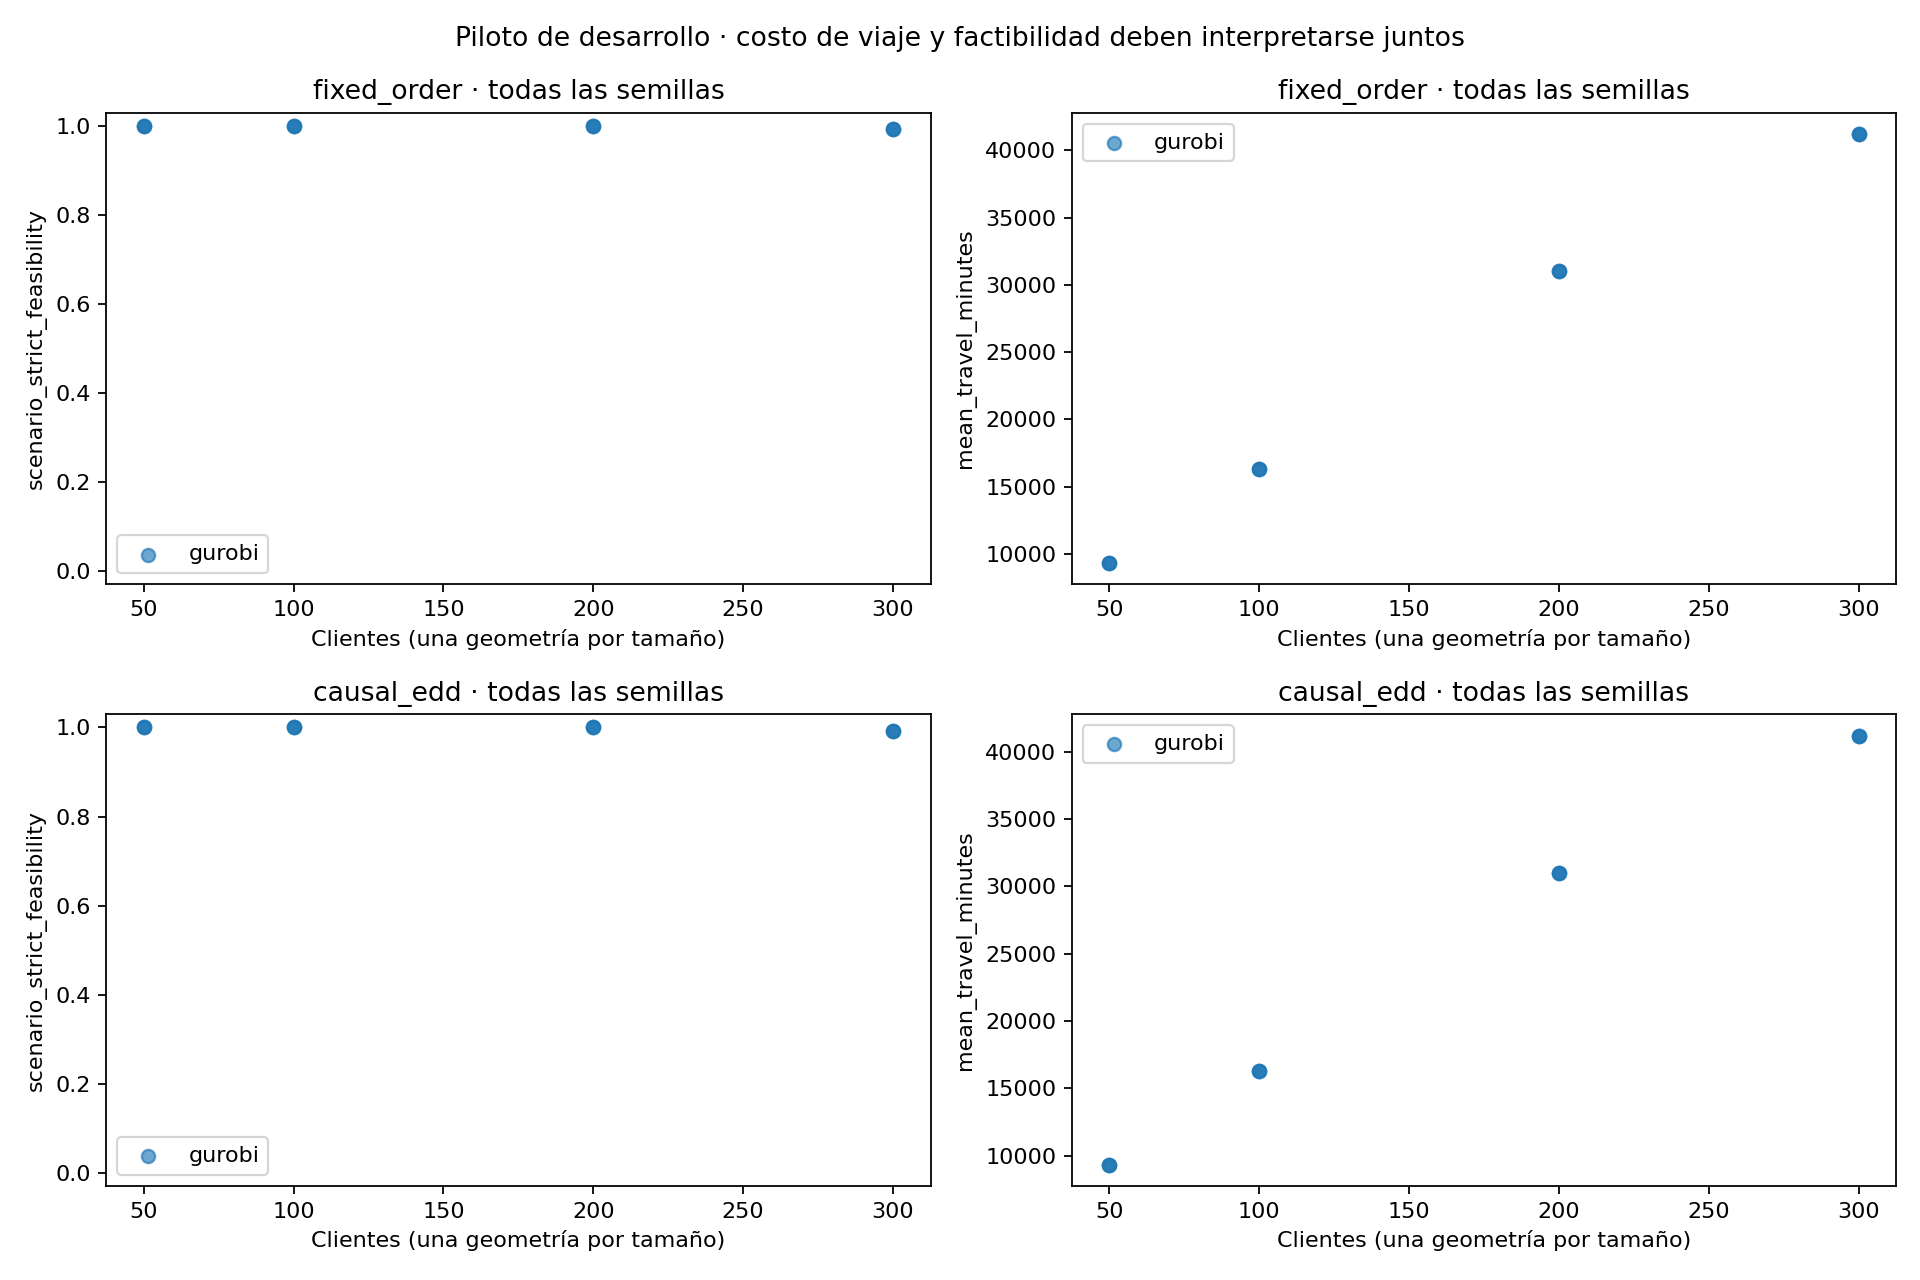

gurobi/n0050/seed_11/solution/routes.png


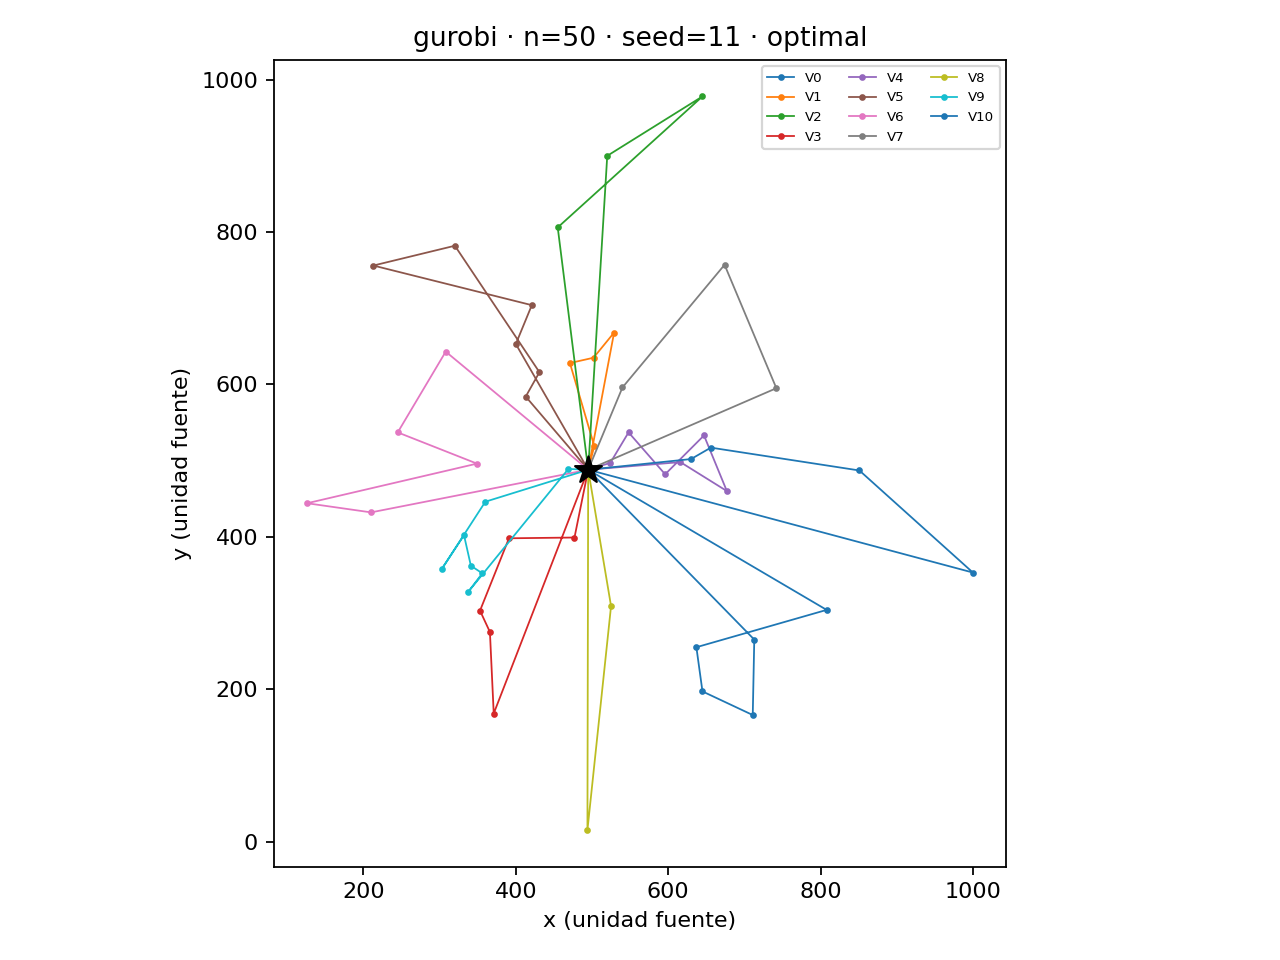

gurobi/n0050/seed_29/solution/routes.png


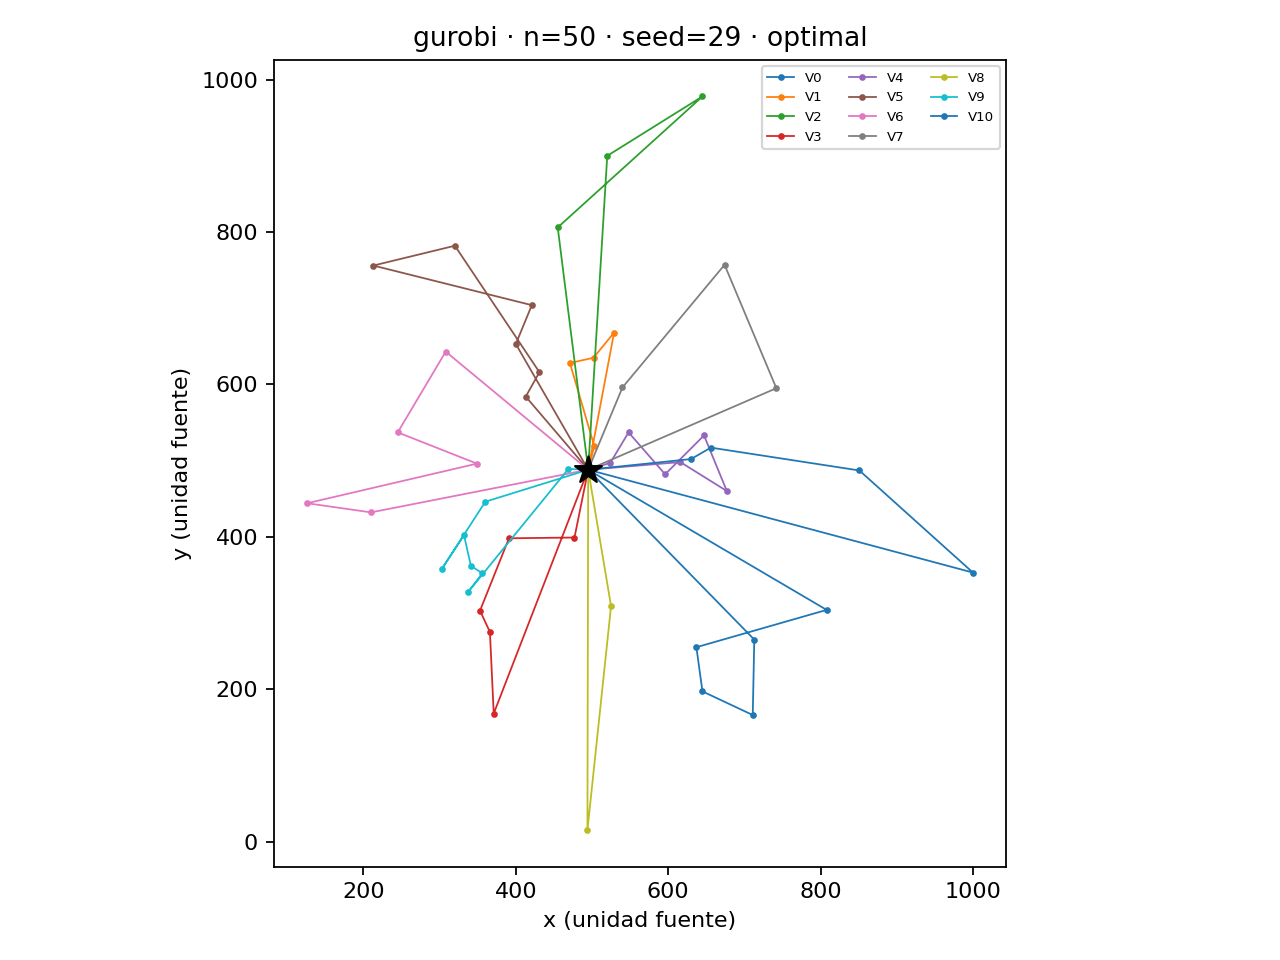

gurobi/n0050/seed_47/solution/routes.png


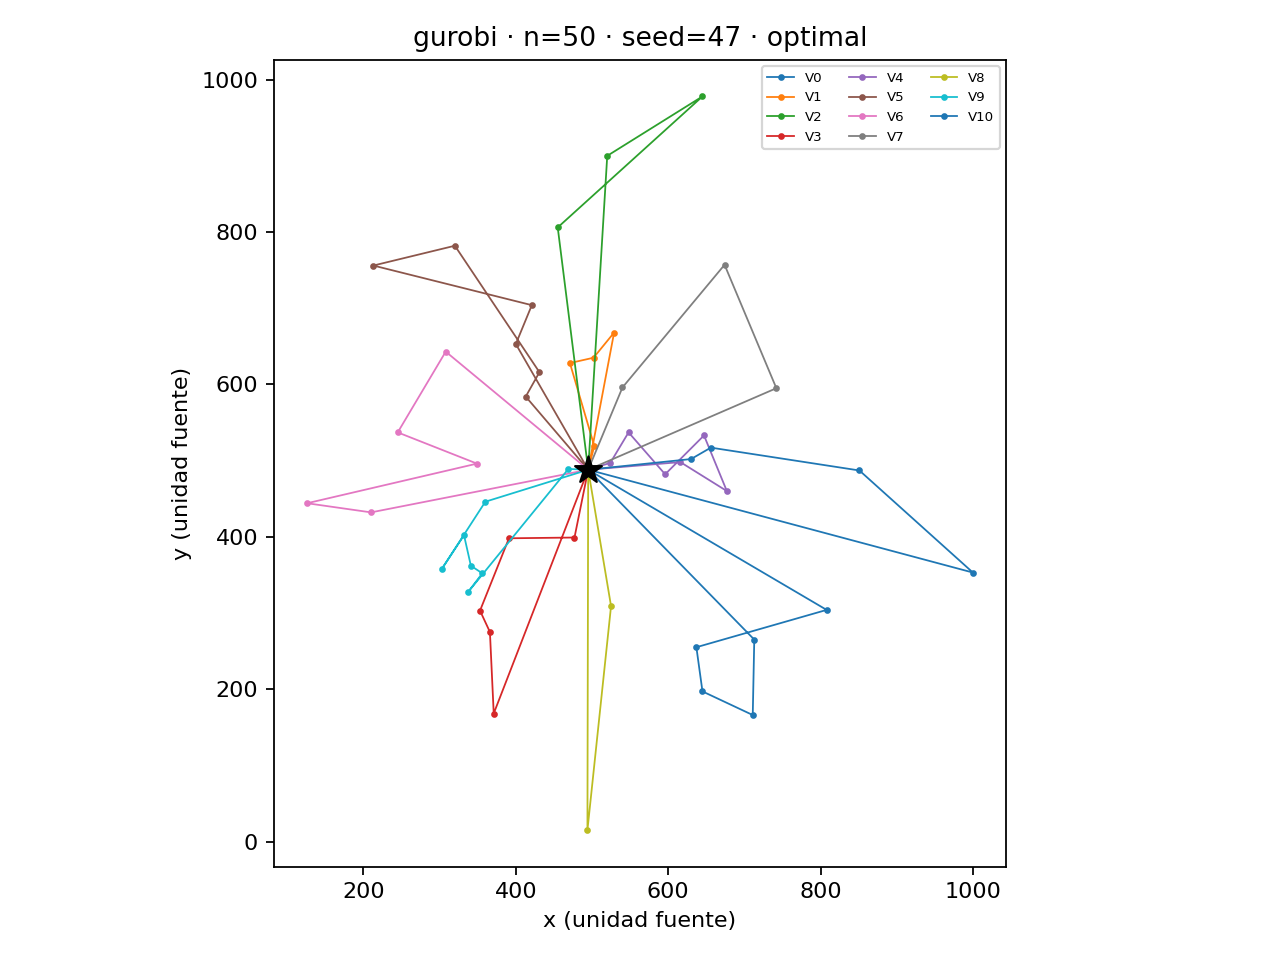

gurobi/n0100/seed_11/solution/routes.png


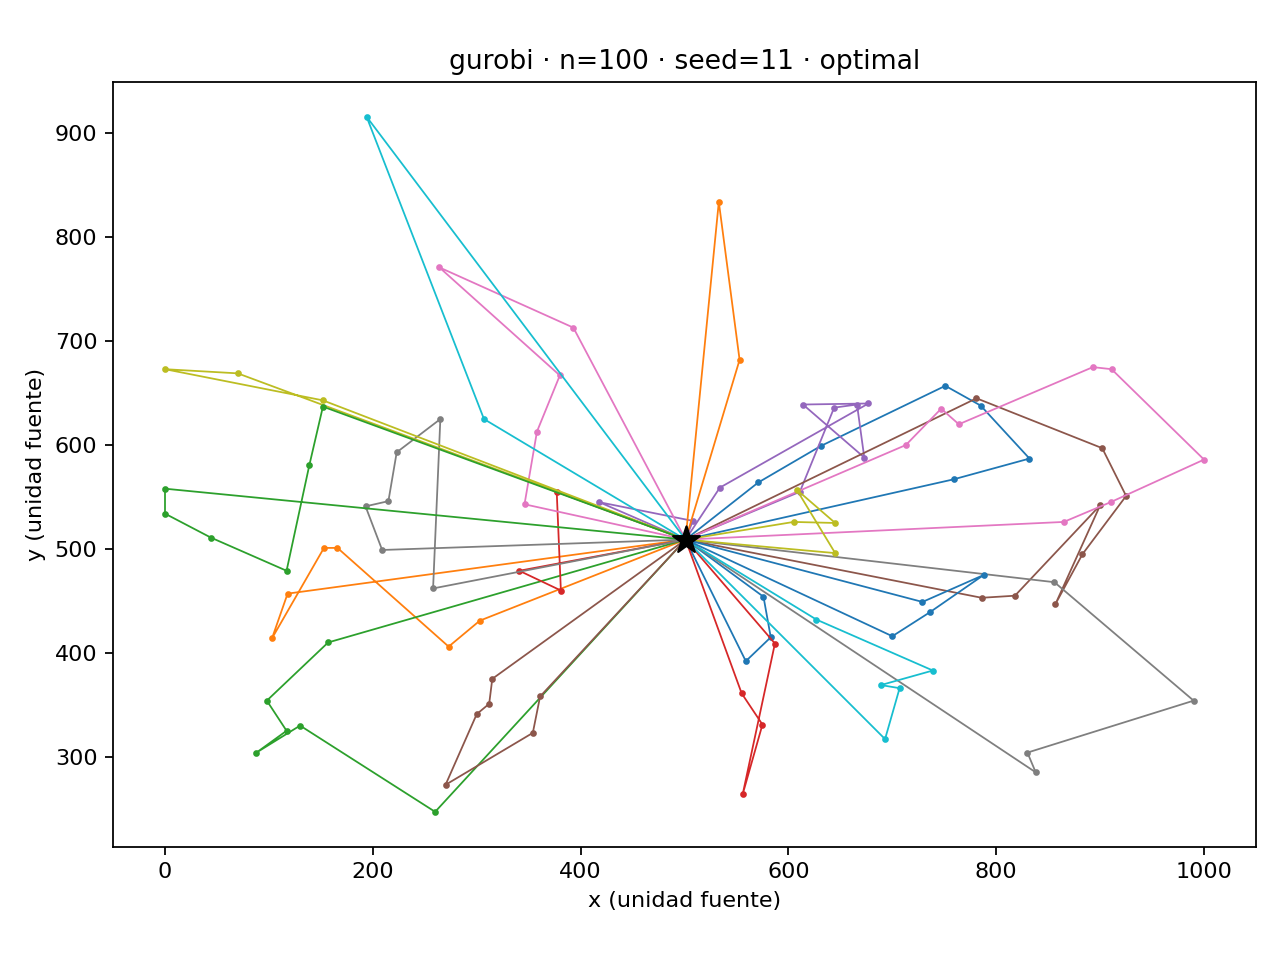

gurobi/n0100/seed_29/solution/routes.png


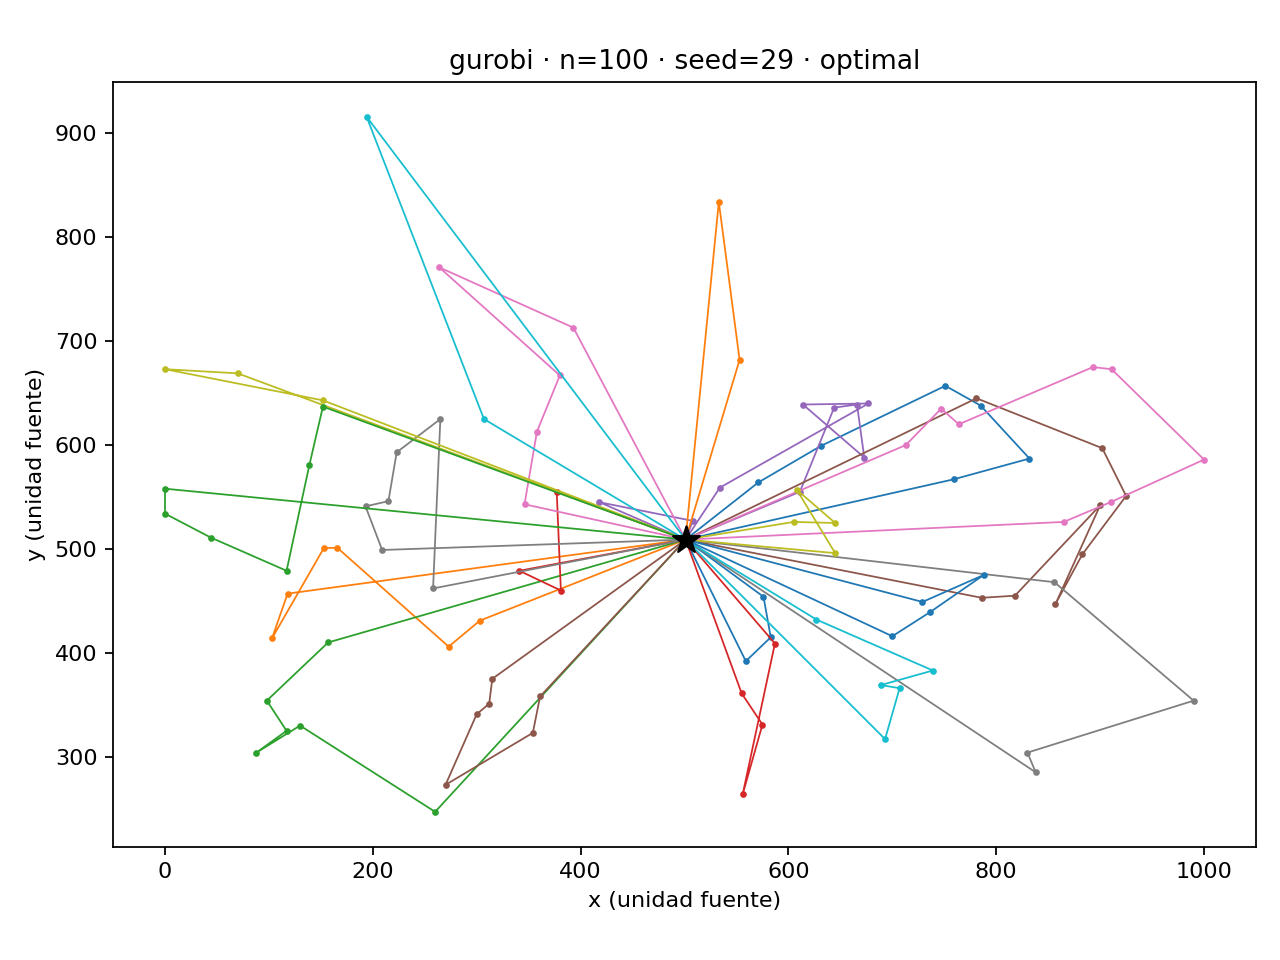

gurobi/n0100/seed_47/solution/routes.png


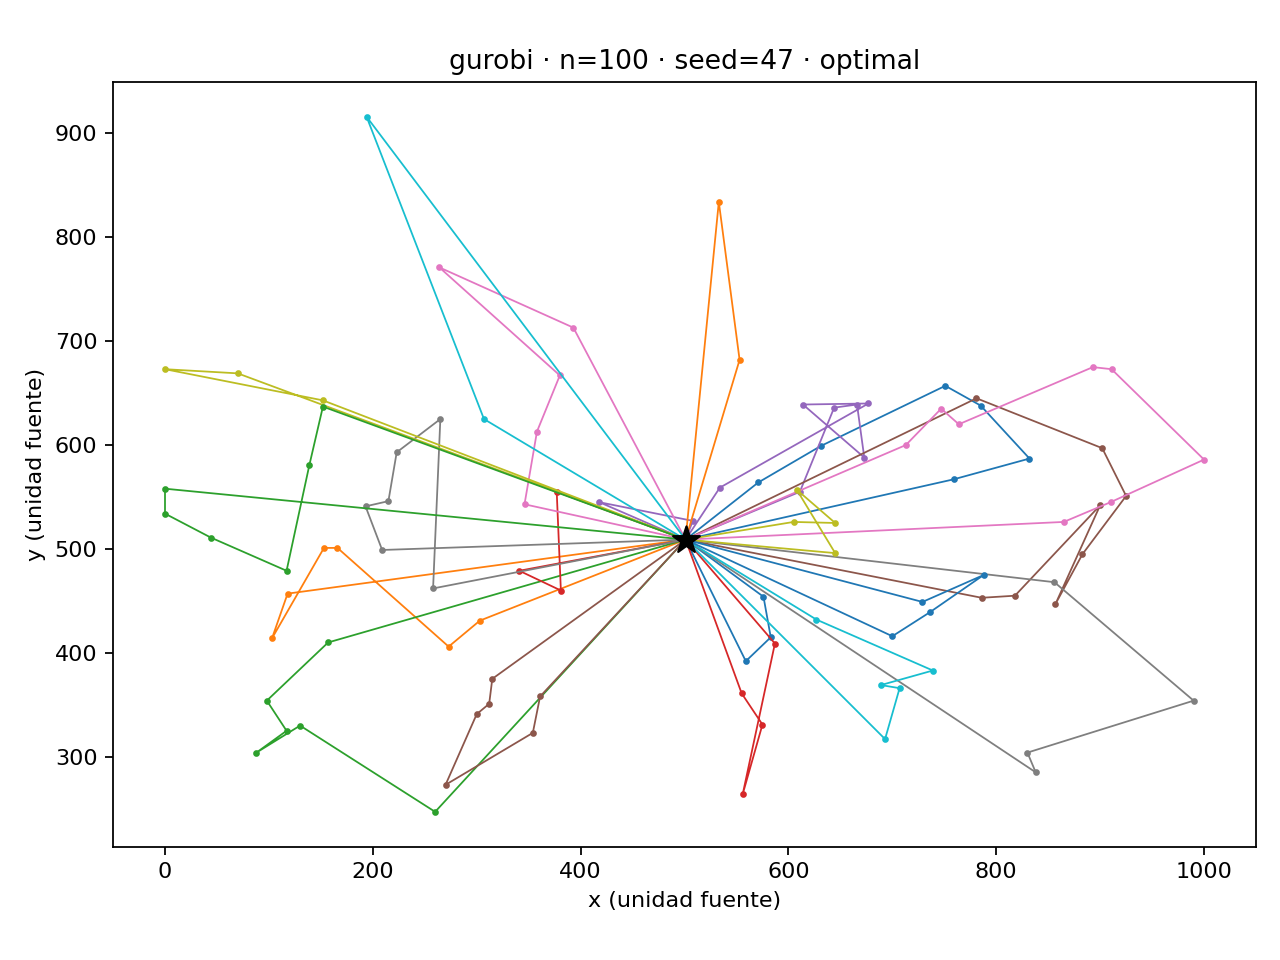

gurobi/n0200/seed_11/solution/routes.png


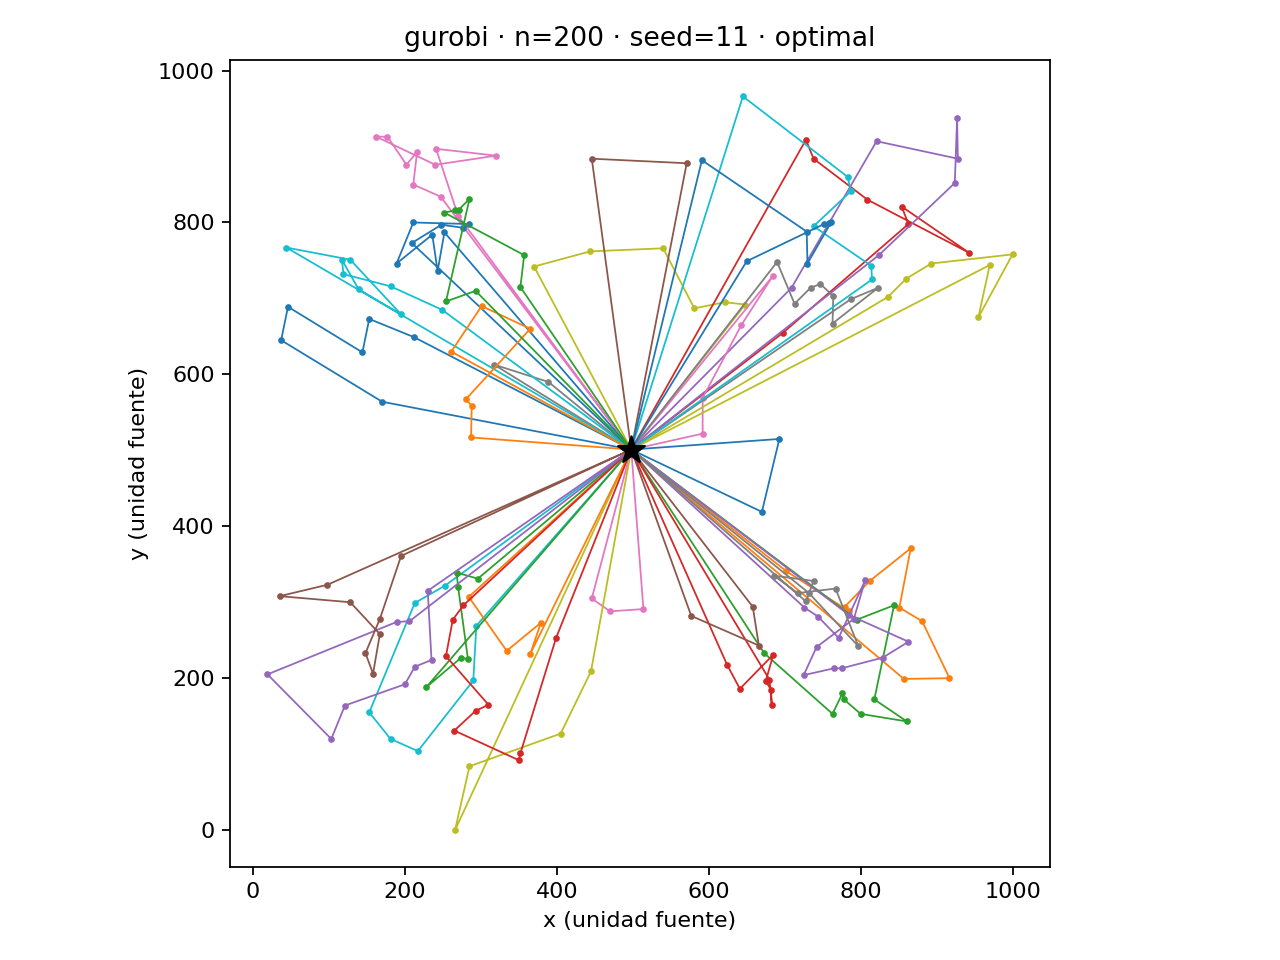

gurobi/n0200/seed_29/solution/routes.png


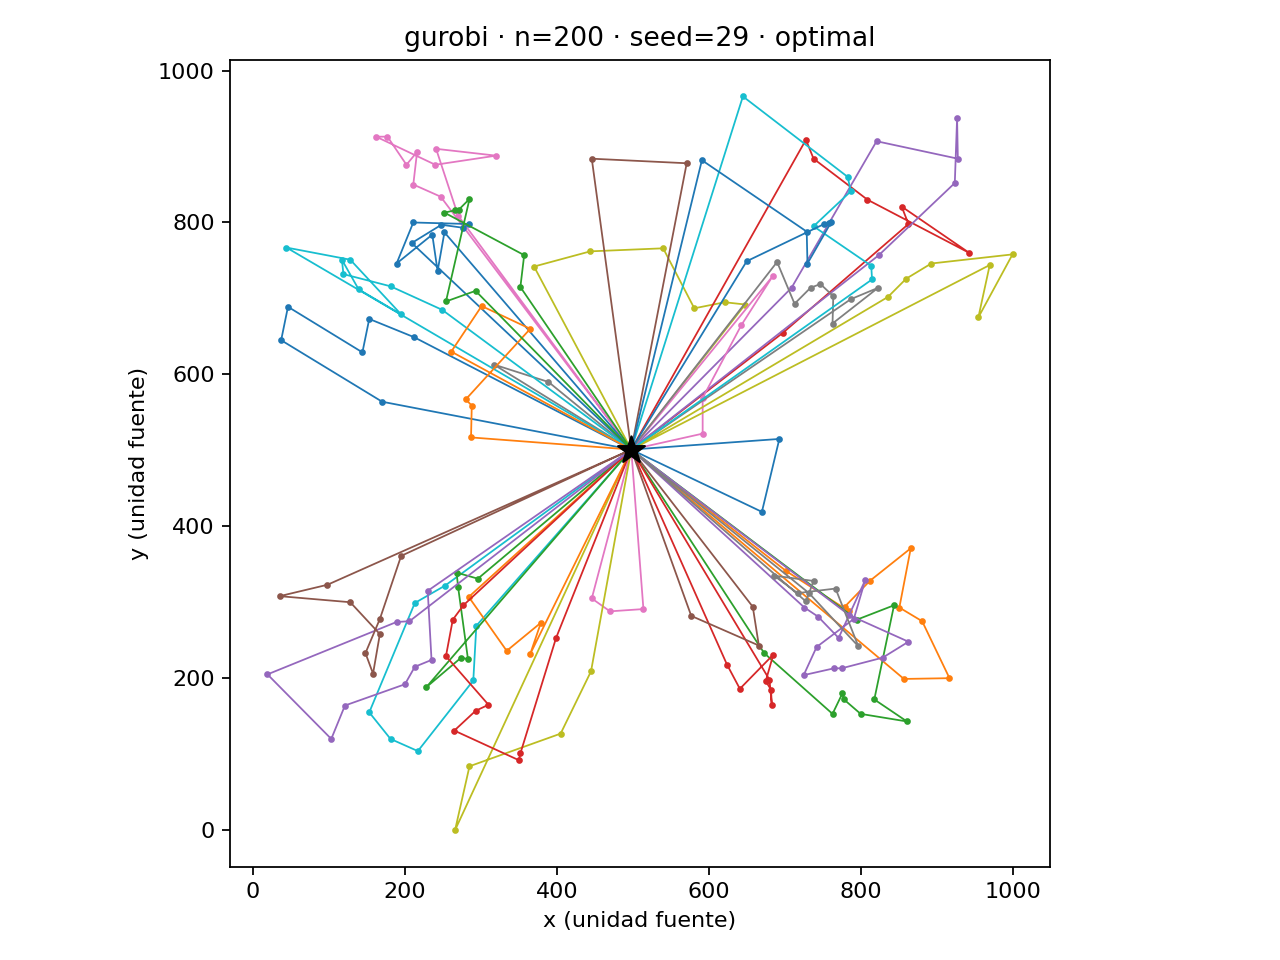

gurobi/n0200/seed_47/solution/routes.png


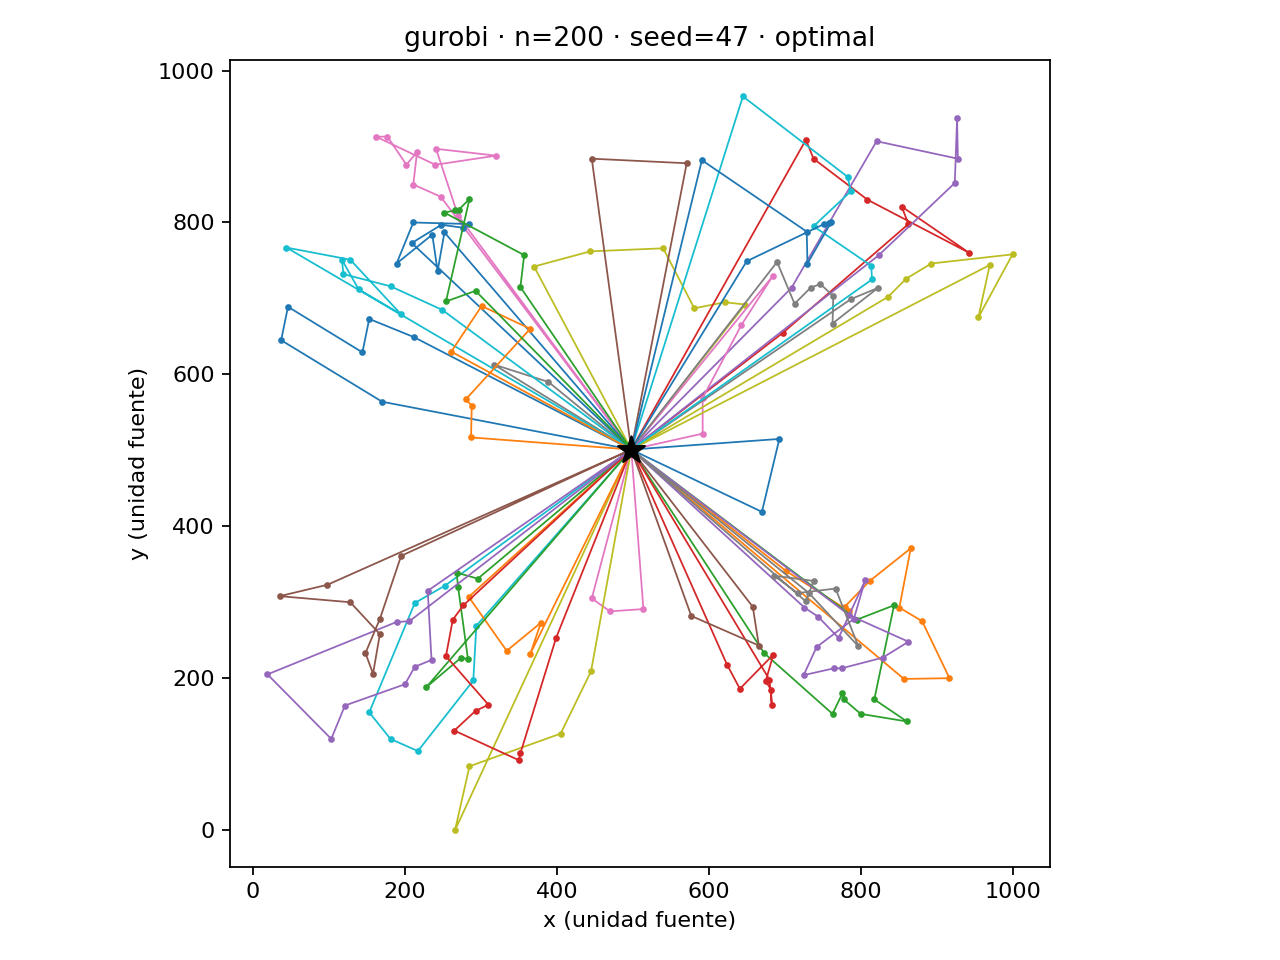

gurobi/n0300/seed_11/solution/routes.png


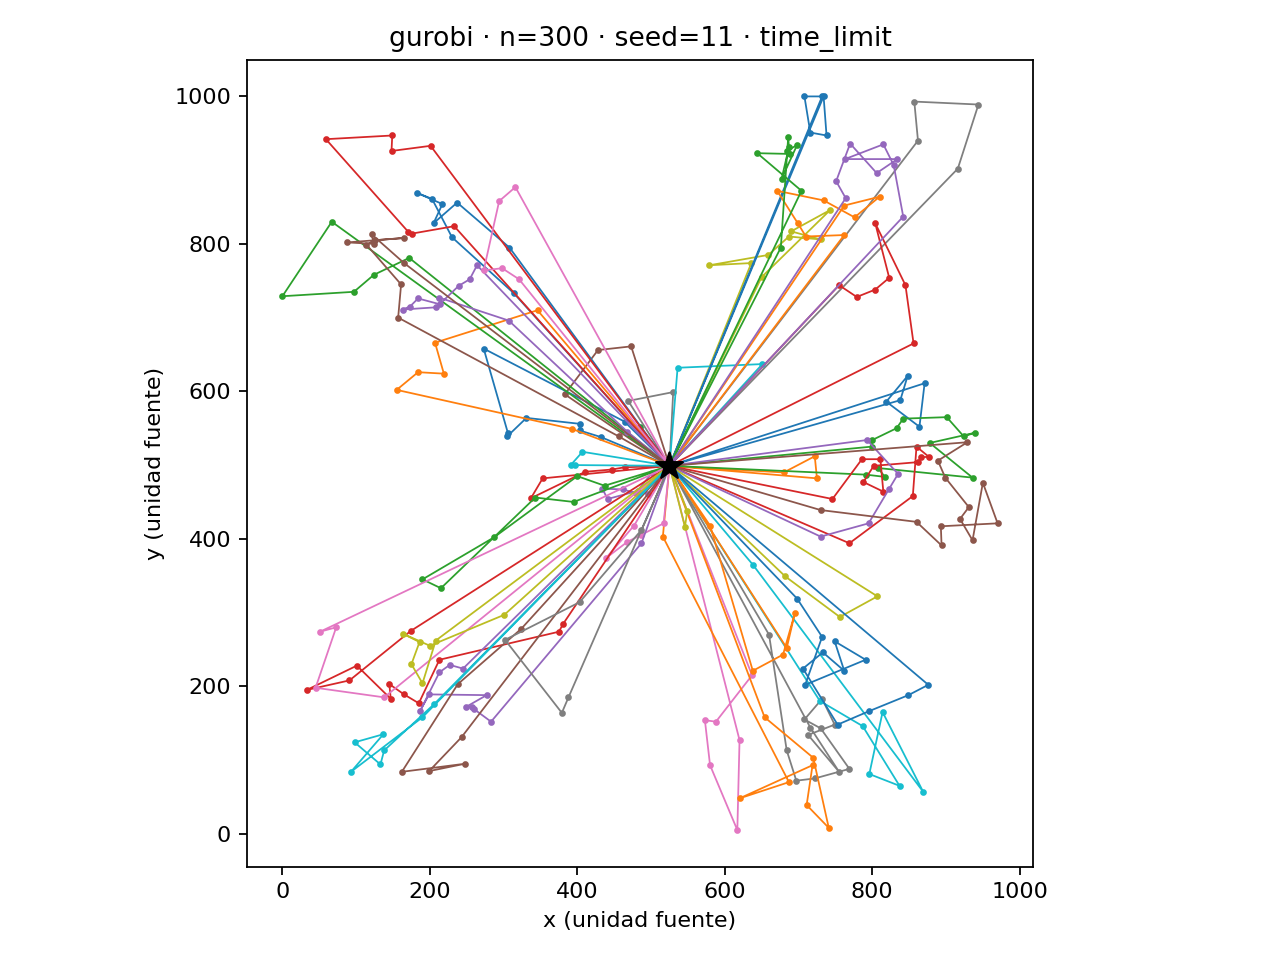

gurobi/n0300/seed_29/solution/routes.png


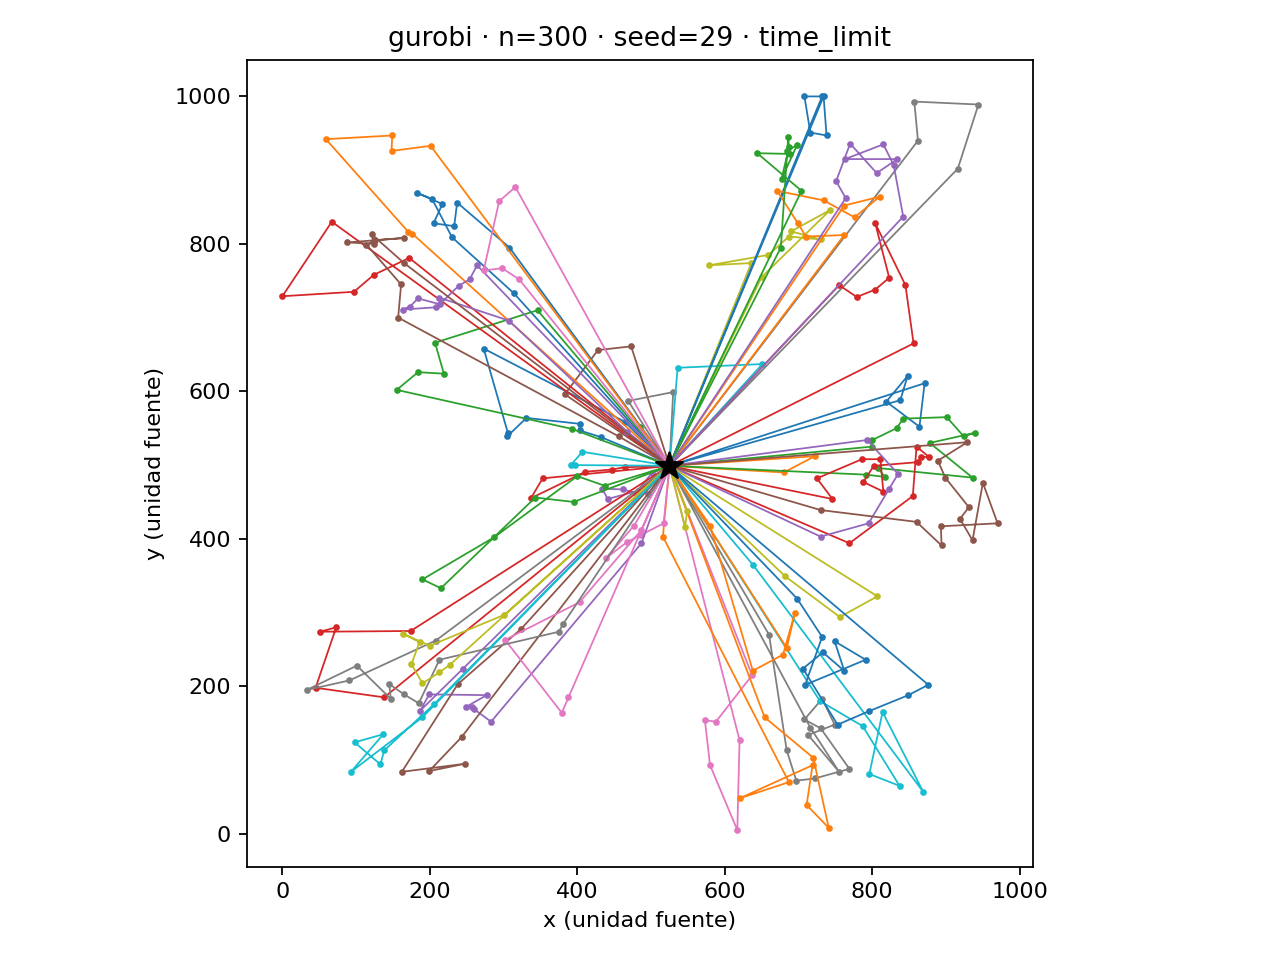

gurobi/n0300/seed_47/solution/routes.png


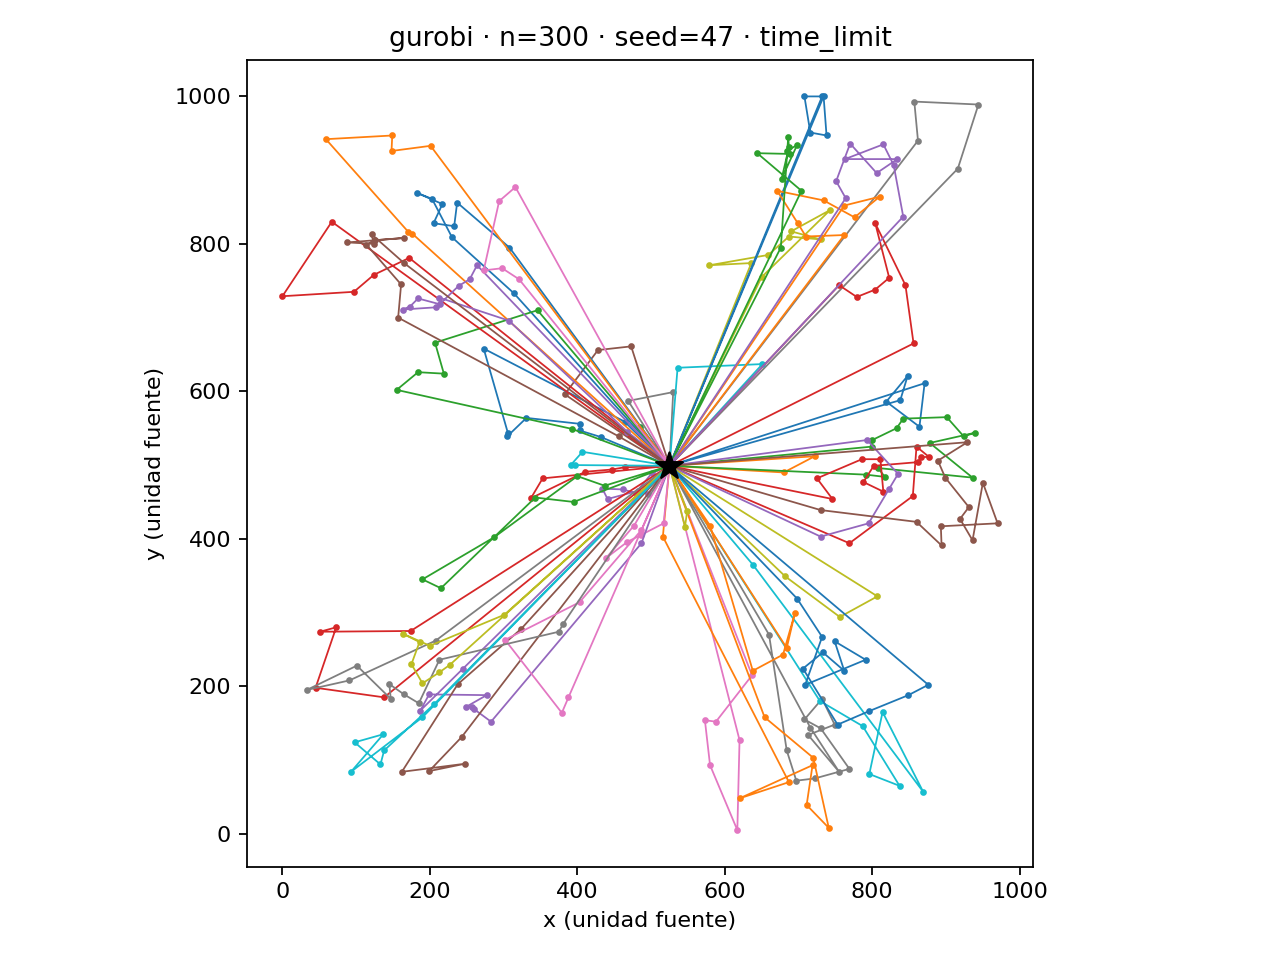

{'status': 'completed',
 'bank_unchanged': True,
 'attempts': 12,
 'summary_rows': 24,
 'unsolved_policy_rows': 0,
 'not_a_claim_of_all_routes_feasible': True,
 'ready_for_confirmatory_comparison': False}

Destino persistente: /content/drive/MyDrive/TESIS-EHBG-FACS/method_runs/pilot00_280553a33c2ab594/20260921T153712Z_ff43d6e0
comparison_id: f6445fdea338a62417782bf24a6664275d4752729b192985d8815f642ce1b6a5


In [16]:
summary = pd.read_csv(RUN / 'report/summary.csv', dtype={'solver_seed': str})
columns = ['method','n_customers','solver_seed','policy','solver_status','evaluation_status',
           'structural_valid','conservative_feasible','nominal_feasible','scenario_strict_feasibility',
           'mean_travel_minutes','cvar_travel_minutes','mean_waiting_minutes',
           'mean_lateness_minutes','mean_depot_overtime_minutes','used_vehicles',
           'search_total_seconds','evaluation_seconds','best_bound','relative_gap']
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(summary[columns])
if (RUN / 'report/metrics.png').exists():
    display(Image(filename=str(RUN / 'report/metrics.png')))
route_figures = sorted(RUN.glob('*/n*/seed_*/solution/routes.png'))
for path in route_figures:
    print(path.relative_to(RUN))
    display(Image(filename=str(path)))
display(json.loads((RUN / 'report/validation.json').read_text()))
print('Destino persistente:', DRIVE_ROOT / 'method_runs' / BANK_ID / RUN.name)
print('comparison_id:', summary['comparison_id'].iloc[0])


## 7. Archivos para el notebook 06
```text
MyDrive/TESIS-EHBG-FACS/method_runs/<bank_id>/<run_id>/
  meta/plan.json, environment.json, metrics_schema.json, code/, validation/, CHECKSUMS.json
  <method>/n0050/seed_11/solution/
    solution.json, identity.json, environment.json, search_history.csv
    planned_routes.csv, nominal_events.csv, routes.png, CHECKSUMS.json
    [Gurobi: modelo algebraico, logs y artefactos del solver]
  <method>/n0050/seed_11/<fixed_order|causal_edd>/
    scenario_metrics.csv, realized_routes.csv, events.csv, summary.json
    validation.json, environment.json, CHECKSUMS.json
  report/summary.csv, summary.json, failures.csv, metrics.png
         validation.json, bundles.json, CHECKSUMS.json
```
Los intentos sin solución tienen `solution.json` y filas en el resumen, con métricas vacías;
no tienen rutas ni escenarios ficticios. Una interrupción puede dejar carpetas `.partial`
o `.interrupted_*`, que se conservan para diagnóstico y no entran al reporte.

Unir 01/02/03 sólo cuando coincidan `comparison_id`, banco, evaluador, escenarios y protocolo
compartido. Los parámetros de cada método se conservan en su firma de corrida. Las claves incluyen método, geometría, semilla y política;
los escenarios y semillas de una misma geometría no son instancias independientes.
Leer `scenario_seed` como texto al importar CSV (64 bits); Excel puede redondear números largos.
Los JSON conservan los enteros exactos. No hay p-valores, prueba final ni conclusiones de superioridad.
